# Prédire l'Elo d'un joueur d'échecs sans biais de pays

**Projet Ethics of AI, ING5 ECE 2026-2027. Rendu final.**

### Résumé

1. On estime l'Elo rapide chess.com d'un joueur à partir d'une seule de ses parties, pour le placer dans la bonne poule d'un tournoi. C'est une décision sur une personne : la prédiction ne doit pas dépendre de son pays.
2. Le dataset réunit 4 200 parties réelles, équilibrées par quotas entre 5 pays et 7 tranches d'Elo, avec des indicateurs de jeu calculés par Stockfish.
3. Nous avons adapté le LLM Qwen3-4B-Instruct-2507 de 3 façons : prompt engineering, RAG et fine-tuning QLoRA. Seul le fine-tuning rivalise avec un gradient boosting (MAE de 380 points contre 369).
4. À partie identique, le modèle de base donne 91 points de moins à un joueur des États-Unis qu'à un joueur français. Après fine-tuning, aucun écart entre pays n'est significatif. Tirer le pays au hasard à l'entraînement (FT-B) va dans le bon sens, sans gain démontré.
5. SHAP et LIME le confirment : le pays pèse 15,5 % de la décision du modèle de base, 1,0 % pour FT-A et 0,2 % pour FT-B.

### Sommaire

0. Résumé et sommaire
1. Problème et cas d'usage
2. Dataset
3. Biais dans les données
4. Modèles de référence
5. Les 3 méthodes d'adaptation du LLM, le benchmark et le modèle retenu
6. Biais du modèle et réduction
7. XAI : SHAP et LIME
8. Démo sur nos propres parties
9. Limites et éthique
10. Conclusion
11. Annexe : vérification des chiffres cités

### Comment lire ce notebook

- Il ne relance **aucun calcul lourd** : ni collecte, ni Stockfish, ni LLM. Il lit les CSV et les figures déjà présents dans le dépôt et les présente. Il s'exécute sur CPU en moins d'une minute.
- Chaque section commence par **ce qu'il faut retenir**. Sous chaque résultat, une ligne *Source* indique le notebook qui l'a produit.
- Les intervalles de confiance sont à 95 %. Un écart dont l'intervalle contient 0 ne permet pas de conclure.
- L'annexe recalcule chaque chiffre cité dans le texte à partir des CSV et s'arrête si l'un d'eux ne correspond pas.

| Consigne du cours | Où |
|---|---|
| (a) Dataset réel, ses biais, et leur réduction pour une prédiction non biaisée | Sections 2, 3 et 6 |
| (b) Un LLM léger adapté par 3 méthodes, benchmarké, et le meilleur retenu | Section 5 |
| (c) Utilisation sur un problème concret lié au dataset | Sections 1 et 8 |
| (d) Explication des décisions avec 2 outils d'XAI | Section 7 |

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
assert (ROOT / "resultats_xai").is_dir(), "Lancer le notebook depuis la racine du dépôt."
PROMPTS = ROOT / "data" / "prompts"

# Fichiers locaux non versionnés (ils contiennent les pseudos) : utilisés seulement s'ils sont présents.
LOCAL = {name: ROOT / "data" / f"{name}.csv" for name in ("games", "stockfish_features", "game_ids")}
HAS_LOCAL_DATA = all(path.exists() for path in LOCAL.values())

# Noms affichés pour les parties de démo. Le dépôt est public : jamais de prénom ni de pseudo.
PLAYER_NAMES = {f"j{k}": f"Joueur {k}" for k in range(1, 5)}

BIN_ORDER = ["100-400", "400-700", "700-1000", "1000-1300", "1300-1600", "1600-1900", "1900+"]
COUNTRY_NAMES = {"FR": "France", "IN": "Inde", "US": "États-Unis", "BR": "Brésil", "DE": "Allemagne"}
COLORS = {"Constante": "#b8b6ae", "Régression linéaire": "#8a887f", "Gradient boosting": "#52514e",
          "Médiane des voisins": "#9cc7b4", "Zero-shot": "#2a78d6", "Few-shot": "#e8692f", "RAG": "#1f9e78",
          "FT-A": "#6a4fd8", "FT-B": "#d9578c", "Réel": "#0b0b0b"}
plt.rcParams.update({
    "figure.figsize": (11, 5.2), "figure.dpi": 100, "font.size": 12, "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e4e3de", "axes.axisbelow": True, "legend.frameon": False,
})


def read(relative):
    return pd.read_csv(ROOT / relative)


def show_image(relative, width=900):
    display(Image(filename=str(ROOT / relative), width=width))


def show_table(frame, digits=0, index=False):
    # digits : un entier pour toutes les colonnes décimales, ou un dictionnaire {colonne: décimales}
    if isinstance(digits, dict):
        formats = {column: f"{{:,.{n}f}}" for column, n in digits.items()}
        styler = frame.style.format(formats, na_rep="", thousands=" ", decimal=",")
    else:
        styler = frame.style.format(precision=digits, na_rep="", thousands=" ", decimal=",")
    if not index:
        styler = styler.hide(axis="index")
    display(styler)


def source(*notebooks):
    display(Markdown("*Source : " + ", ".join(f"`{name}`" for name in notebooks) + "*"))


def interval(mean, low, high, digits=0):
    # « +49 [+37 ; +62] », avec une étoile si l'intervalle exclut 0
    star = " *" if low > 0 or high < 0 else ""
    return f"{mean:+.{digits}f} [{low:+.{digits}f} ; {high:+.{digits}f}]{star}".replace(".", ",")


print("Données locales non versionnées :", "présentes" if HAS_LOCAL_DATA else "absentes, les valeurs enregistrées sont utilisées")

Données locales non versionnées : présentes


## 1. Problème et cas d'usage

> **À retenir.** On prédit l'Elo rapide chess.com d'un joueur à partir d'une seule de ses parties. Cette prédiction sert à prendre une décision sur une personne. Elle doit donc rester la même quel que soit le pays du joueur.

**Le cas d'usage.** Un club organise un tournoi en cadence rapide, avec des poules de niveau. Un joueur s'inscrit sans classement. Il joue une partie de placement, le modèle estime son Elo à partir de cette partie, et l'organisateur le place dans la poule correspondante.

**Pourquoi viser une prédiction non biaisée.** Le cours distingue deux situations (slide 28). Quand un modèle décrit le monde, il peut refléter les écarts réels entre groupes. Quand il **décide** pour une personne, on vise une prédiction non biaisée : deux joueurs qui jouent la même partie doivent recevoir la même estimation. Notre cas est le second : à partie identique, mettre « Inde » ou « États-Unis » au lieu de « France » ne doit rien changer.

**Ce que le modèle reçoit.** Un résumé de la partie : pays, couleur, ouverture, résultat, fin de partie, nombre de coups, gaffes, erreurs, imprécisions, ACPL et 10 premiers coups. Jamais le pseudo, ni l'Elo de l'adversaire, ni le lien vers la partie.

**Comment on mesure le biais.** Par un test contrefactuel : on présente la même partie 5 fois, en ne changeant que le pays, et on regarde si la prédiction bouge (section 6). L'XAI mesure ensuite la part du pays dans la décision (section 7).

## 2. Dataset

> **À retenir.** 4 200 parties rapides réelles de 856 joueurs, collectées sur 12 mois avec l'API publique de chess.com. Des quotas imposent le même nombre de parties par pays dans chaque tranche d'Elo. Les indicateurs de jeu viennent de Stockfish : ils remplacent l'accuracy de chess.com, absente de 71,5 % des parties, et suivent la même tendance qu'elle (corrélation de rang de −0,92).

### Construction (`build_dataset.py`)

- **Source.** L'API publique de chess.com, avec un contact dans l'en-tête de chaque requête.
- **Échantillonnage en boule de neige.** L'API ne liste que 10 000 joueurs par pays, par ordre alphabétique. On part donc de 10 joueurs par pays et des leaderboards, puis on visite les adversaires rencontrés. Les tranches d'Elo sont visitées à tour de rôle, sinon les bas Elo, plus nombreux, rempliraient la file.
- **Quotas.** 7 tranches d'Elo × 5 pays. Chaque tranche compte 240 parties pour la France et 90 pour l'Inde, les États-Unis, le Brésil et l'Allemagne, soit 7 × 600 = 4 200 parties.
- **Filtres.** Cadence rapide, partie classée, règles standard, au moins 20 coups (40 demi-coups), 12 derniers mois, au plus 5 parties par joueur, et au plus 25 % de parties de leaderboard par case.
- **Comptes fermés exclus**, dont les comptes bannis pour triche : leur Elo ne reflète pas forcément leur niveau.
- **Découpage par joueur** en train, val et test (80/10/10) : un joueur n'apparaît jamais dans deux ensembles.

In [2]:
splits = {name: pd.read_json(PROMPTS / f"{name}.jsonl", lines=True) for name in ["train", "val", "test"]}
games = pd.concat(splits.values(), ignore_index=True)
print(f"{len(games)} parties : " + ", ".join(f"{name} {len(frame)}" for name, frame in splits.items()))
if HAS_LOCAL_DATA:
    ids = pd.read_csv(LOCAL["game_ids"], usecols=["game_id", "username"]).merge(games[["game_id", "split"]], on="game_id")
    print(f"{ids['username'].nunique()} joueurs au total, dont {ids.loc[ids['split'] == 'test', 'username'].nunique()} dans le test")

quotas = pd.crosstab(games["elo_bin"], games["country"]).reindex(BIN_ORDER)[list(COUNTRY_NAMES)].rename(columns=COUNTRY_NAMES)
show_table(quotas.rename_axis("Tranche d'Elo").reset_index())

origin = games["source"].value_counts()
labels = {"opponent": "Adversaires visités (boule de neige)", "country_list": "Joueurs de départ (liste par pays)",
          "leaderboard": "Leaderboards"}
show_table(pd.DataFrame({"Origine des parties": origin.index.map(labels), "Parties": origin.values,
                         "Part (%)": 100 * origin.values / len(games)}), 1)
source("build_dataset.py", "build_prompts.py", "data/prompts/*.jsonl")

4200 parties : train 3332, val 431, test 437


856 joueurs au total, dont 89 dans le test


Tranche d'Elo,France,Inde,États-Unis,Brésil,Allemagne
100-400,240,90,90,90,90
400-700,240,90,90,90,90
700-1000,240,90,90,90,90
1000-1300,240,90,90,90,90
1300-1600,240,90,90,90,90
1600-1900,240,90,90,90,90
1900+,240,90,90,90,90


Origine des parties,Parties,Part (%)
Adversaires visités (boule de neige),3 898,"92,8"
Joueurs de départ (liste par pays),201,"4,8"
Leaderboards,101,"2,4"


*Source : `build_dataset.py`, `build_prompts.py`, `data/prompts/*.jsonl`*

**Limites de l'échantillonnage.**
- 93 % des parties viennent d'adversaires visités : les joueurs ne sont pas tirés au hasard. Les joueurs actifs sont favorisés, d'autant que chacun apporte jusqu'à 5 parties.
- Les 101 parties de leaderboard sont toutes dans la tranche 1900+, où elles pèsent 17 % : 8 % en France, mais 26 % en Inde et aux États-Unis. Le haut de cette tranche n'est donc pas comparable d'un pays à l'autre. Les scores sont aussi recalculés sans elles.
- L'équilibre entre pays est **imposé** par les quotas. Il décrit l'échantillon, pas la population de chess.com.

### Indicateurs Stockfish (`stockfish_features.py`)

Chaque partie est analysée par Stockfish à la profondeur 14, avec les définitions de Lichess :
- **ACPL** : perte moyenne du joueur par coup, en centipions (évaluations bornées à ±1 000) ;
- **gaffe, erreur, imprécision** : un coup qui fait baisser les chances de gain d'au moins 0,3, 0,2 ou 0,1, sur une échelle de −1 (perdu) à +1 (gagné). Passer de +9 à +5 ne change pas l'issue de la partie et n'est donc pas une gaffe.

**Validation.** L'accuracy de chess.com n'existe que pour une partie des parties. Là où elle existe, l'ACPL doit la suivre en sens inverse : plus on perd de centipions, moins on est précis.

Voici un prompt tel que le modèle le reçoit, pour une partie du test :

In [3]:
print(splits["test"].iloc[0]["prompt"])

Voici le résumé d'une partie d'échecs en cadence rapide, jouée sur chess.com et vue du côté d'un joueur.

Pays du joueur : France
Couleur du joueur : noirs
Ouverture : Sicilian Defense Smith Morra Gambit (code ECO B21)
Résultat pour le joueur : victoire
Fin de la partie : échec et mat
Nombre de coups de la partie : 22
Gaffes du joueur : 3
Erreurs du joueur : 1
Imprécisions du joueur : 3
Perte moyenne du joueur en centipions (ACPL) : 158,0
Gaffes du joueur par coup analysé : 0,136
10 premiers coups de la partie : 1. e4 c5 2. d4 Qa5+ 3. c3 cxd4 4. b4 Qb6 5. cxd4 Qxb4+ 6. Bd2 Qxd4 7. Nf3 Qxa1 8. Nc3 Qb2 9. Qb1 Qa3 10. Nb5 Qc5

Estime l'Elo rapide chess.com de ce joueur. Réponds UNIQUEMENT par un nombre entier, sans aucun autre texte.


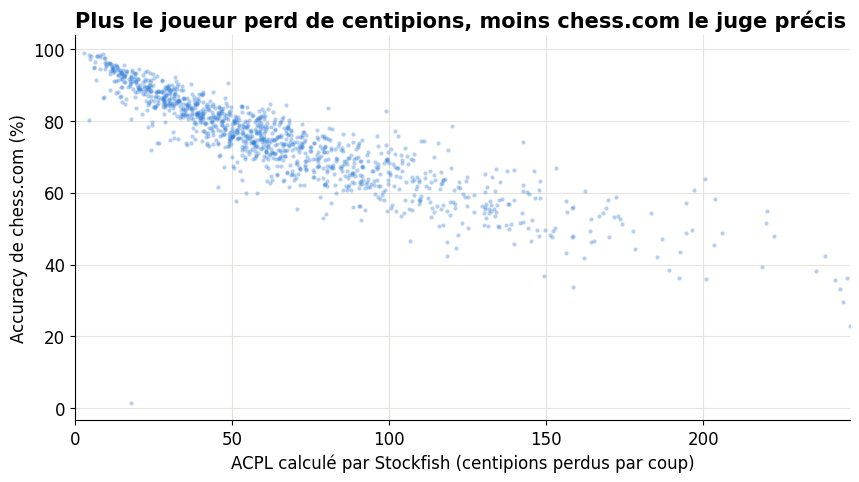

Parties avec accuracy : 1198 ; accuracy absente : 71,5% des parties
Corrélation ACPL / accuracy : Spearman -0,92, Pearson -0,88


*Source : `stockfish_features.py`, `data/games.csv et data/stockfish_features.csv (locaux)`*

In [4]:
if HAS_LOCAL_DATA:
    raw = pd.read_csv(LOCAL["games"], usecols=["game_url", "username", "accuracy"]).merge(
        pd.read_csv(LOCAL["stockfish_features"], usecols=["game_url", "username", "acpl"]), on=["game_url", "username"])
    with_accuracy = raw.dropna(subset=["accuracy", "acpl"])
    SPEARMAN = with_accuracy["acpl"].corr(with_accuracy["accuracy"], method="spearman")
    PEARSON = with_accuracy["acpl"].corr(with_accuracy["accuracy"])
    N_ACCURACY, MISSING_ACCURACY = len(with_accuracy), raw["accuracy"].isna().mean()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(with_accuracy["acpl"], with_accuracy["accuracy"], s=9, alpha=0.35, color=COLORS["Zero-shot"], linewidths=0)
    ax.set_xlim(0, with_accuracy["acpl"].quantile(0.99))
    ax.set_xlabel("ACPL calculé par Stockfish (centipions perdus par coup)")
    ax.set_ylabel("Accuracy de chess.com (%)")
    ax.set_title("Plus le joueur perd de centipions, moins chess.com le juge précis")
    plt.show()
else:  # valeurs obtenues sur les données locales
    SPEARMAN, PEARSON, N_ACCURACY, MISSING_ACCURACY = -0.916, -0.884, 1198, 0.715
print(f"Parties avec accuracy : {N_ACCURACY} ; accuracy absente : {MISSING_ACCURACY:.1%} des parties".replace(".", ","))
print(f"Corrélation ACPL / accuracy : Spearman {SPEARMAN:.2f}, Pearson {PEARSON:.2f}".replace(".", ","))
source("stockfish_features.py", "data/games.csv et data/stockfish_features.csv (locaux)")

## 3. Biais dans les données

> **À retenir.** Dans notre dataset, le pays n'explique rien de l'Elo (η² < 0,001), mais uniquement parce que les quotas l'imposent. Un modèle ne peut donc rien gagner à deviner l'Elo d'après le pays : s'il s'en sert, c'est un biais du modèle, pas un signal des données. D'autres variables sont liées à l'Elo de façon légitime (ouverture, fin de partie). Deux pièges ont été écartés : l'accuracy, dont l'absence dépend du pays et de l'Elo, et les variables qui trahissent la réponse.

Les tests de `01_eda.ipynb` regroupent les erreurs par joueur, car un joueur apporte jusqu'à 5 parties. La part de variance expliquée (η²) donne la taille de l'effet.

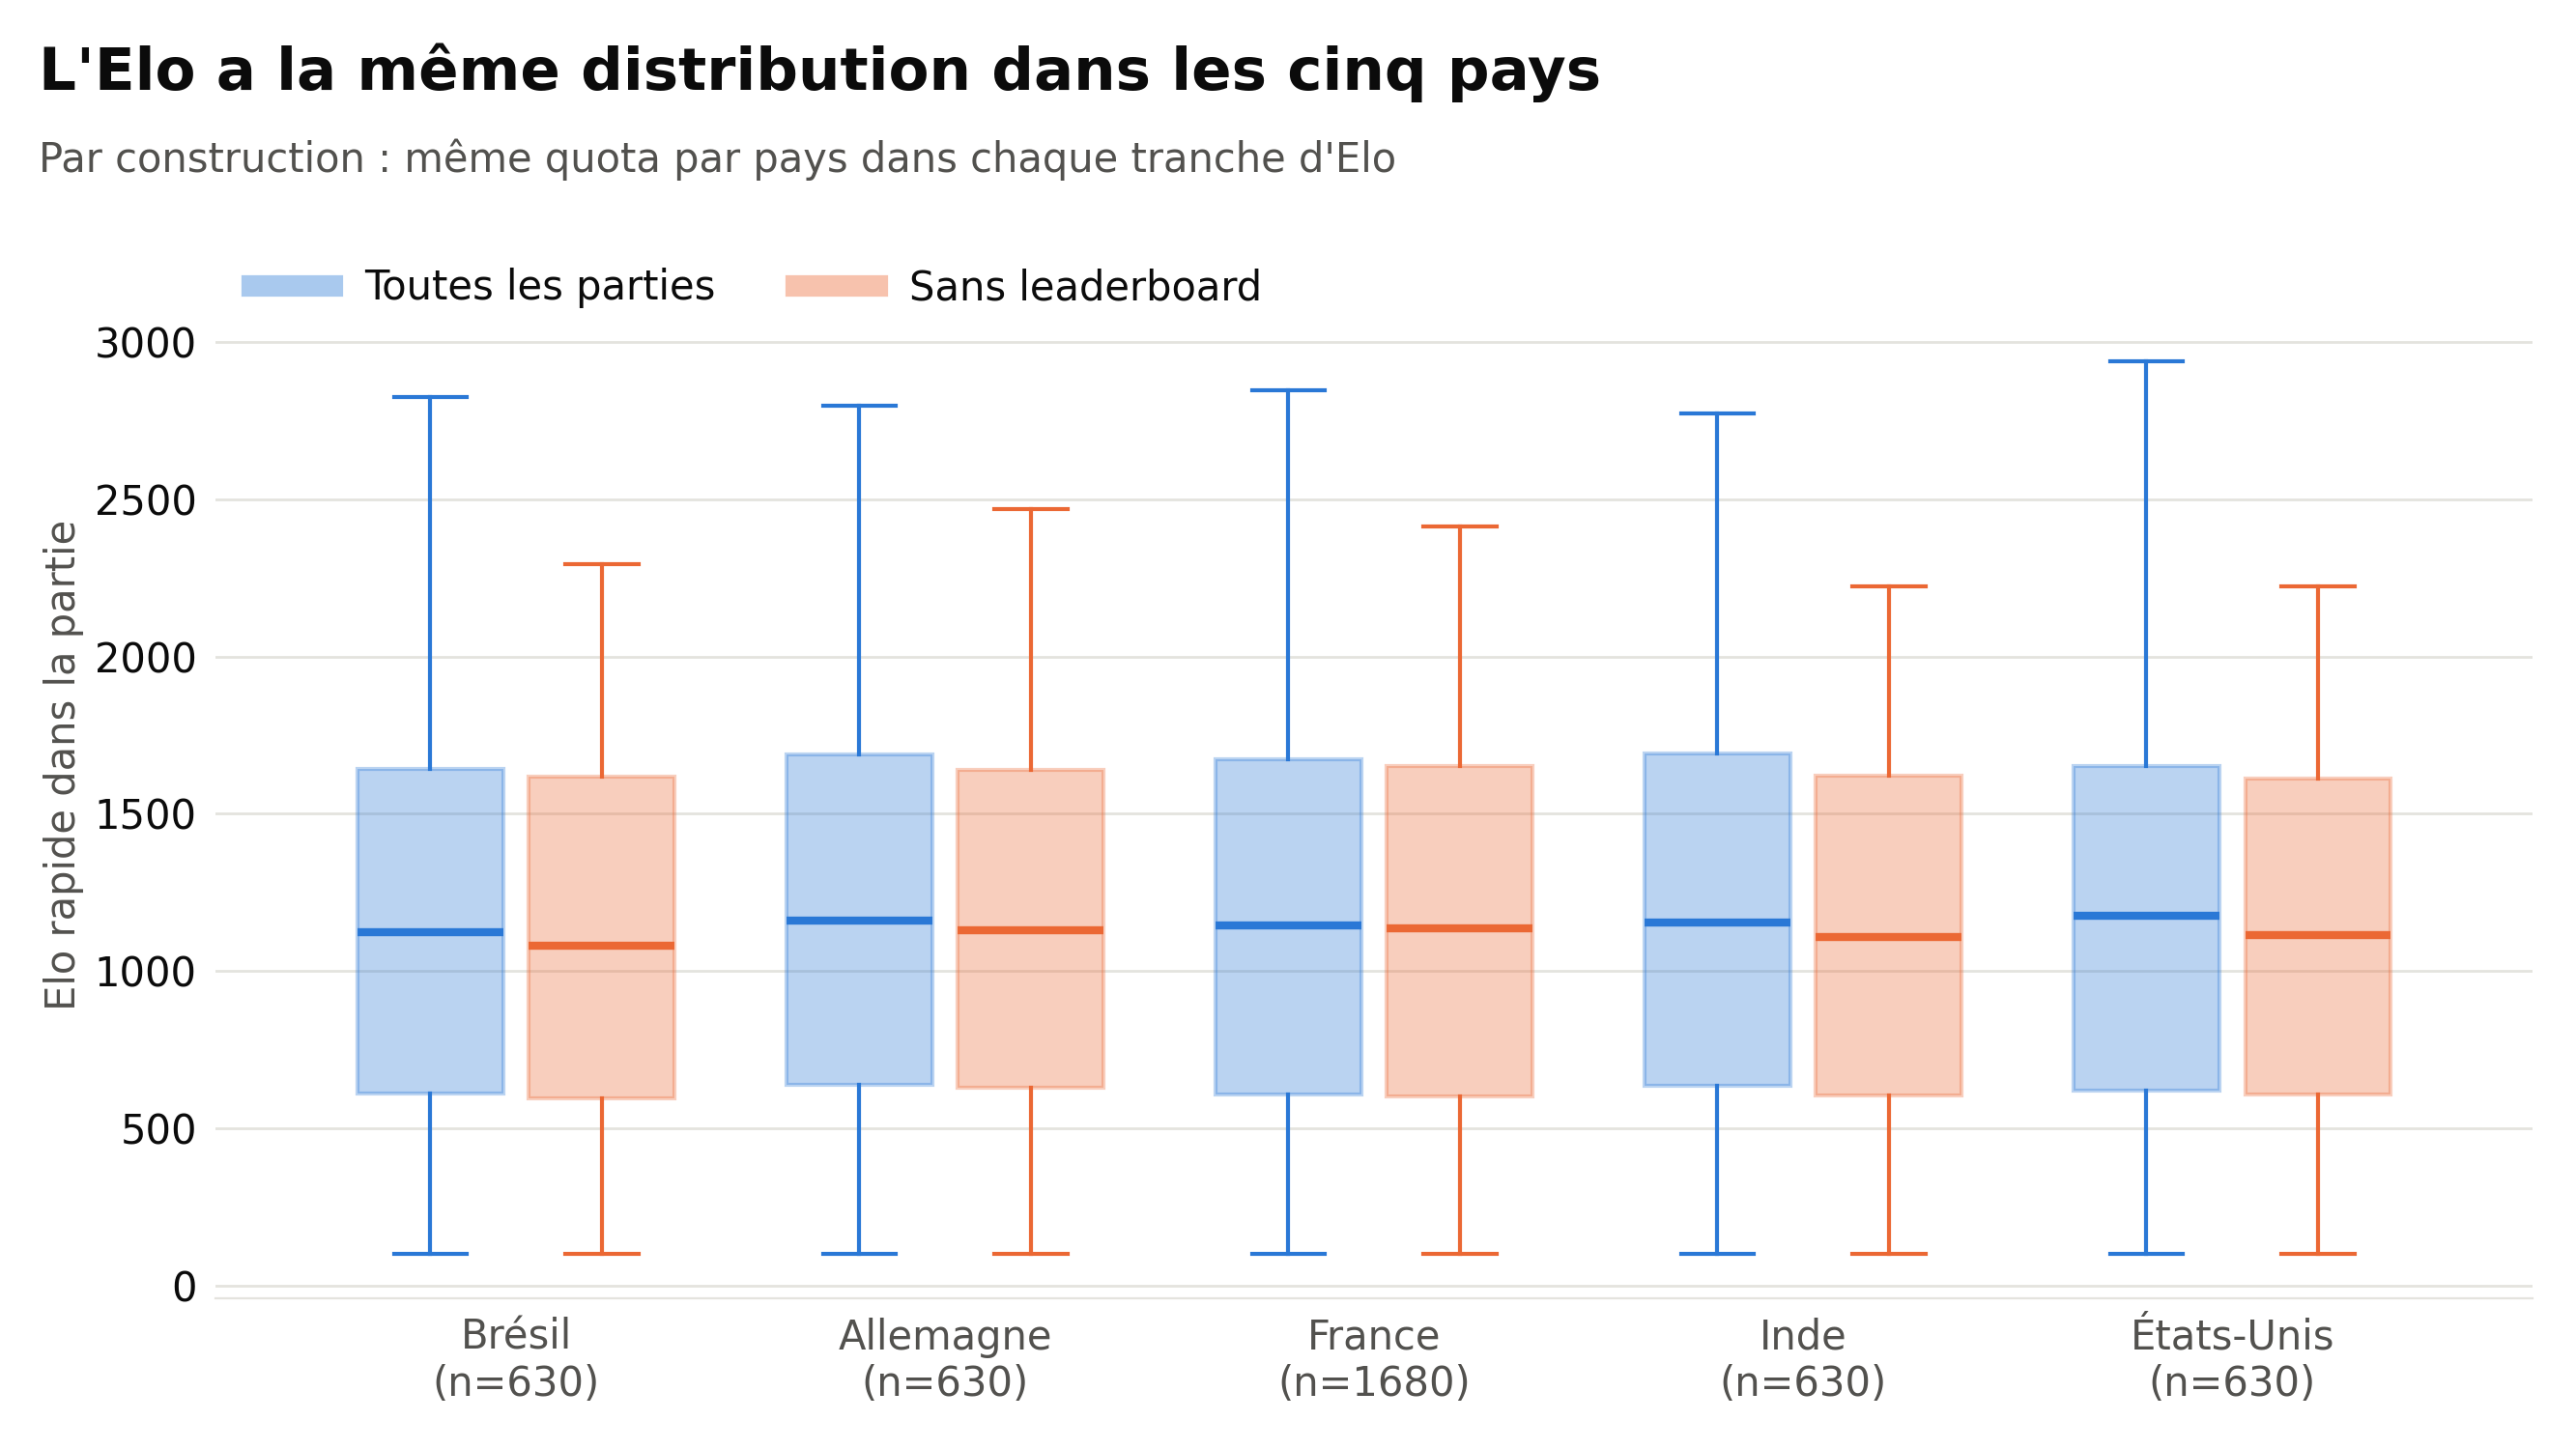

Variable,η²,p,Lecture
Pays (toutes les parties),"0,000","0,999800",Aucun lien : imposé par les quotas
Pays (sans leaderboard),"0,001","0,970000",Aucun lien
Couleur,"0,000","0,490000",Aucun lien
Cadence,"0,010","< 0,001",Effet faible : 94 % des parties en 10 min
Type de fin de partie,"0,094","< 0,001","Répétitions en haut, pats en bas"
Origine de l'échantillon (source),"0,190","< 0,001",Artefact de la collecte : exclue
Ouverture (20 plus fréquentes),"0,217","< 0,001",Lien fort : reflète en partie le niveau


*Source : `01_eda.ipynb`*

In [5]:
show_image("figures/eda/fig01_elo_par_pays.png", 850)
eta = pd.DataFrame([
    ("Pays (toutes les parties)", 0.000, 0.9998, "Aucun lien : imposé par les quotas"),
    ("Pays (sans leaderboard)", 0.001, 0.97, "Aucun lien"),
    ("Couleur", 0.000, 0.49, "Aucun lien"),
    ("Cadence", 0.010, "< 0,001", "Effet faible : 94 % des parties en 10 min"),
    ("Type de fin de partie", 0.094, "< 0,001", "Répétitions en haut, pats en bas"),
    ("Origine de l'échantillon (source)", 0.190, "< 0,001", "Artefact de la collecte : exclue"),
    ("Ouverture (20 plus fréquentes)", 0.217, "< 0,001", "Lien fort : reflète en partie le niveau"),
], columns=["Variable", "η²", "p", "Lecture"])
show_table(eta, {"η²": 3})
source("01_eda.ipynb")

**L'accuracy manque dans 71,5 % des parties, et pas au hasard.** Elle manque dans 73 à 79 % des parties sous 1900, contre 49 % en 1900+. À Elo égal, elle dépend aussi du pays (p = 0,0045) : elle manque dans 76,8 % des parties en Inde, 75,4 % au Brésil, 70,5 % en France, 70,3 % en Allemagne et 65,9 % aux États-Unis. Utiliser l'accuracy, ou le simple fait qu'elle manque, donnerait au modèle un indice indirect sur le pays. Les indicateurs Stockfish, calculés sur toutes les parties, évitent ce problème.

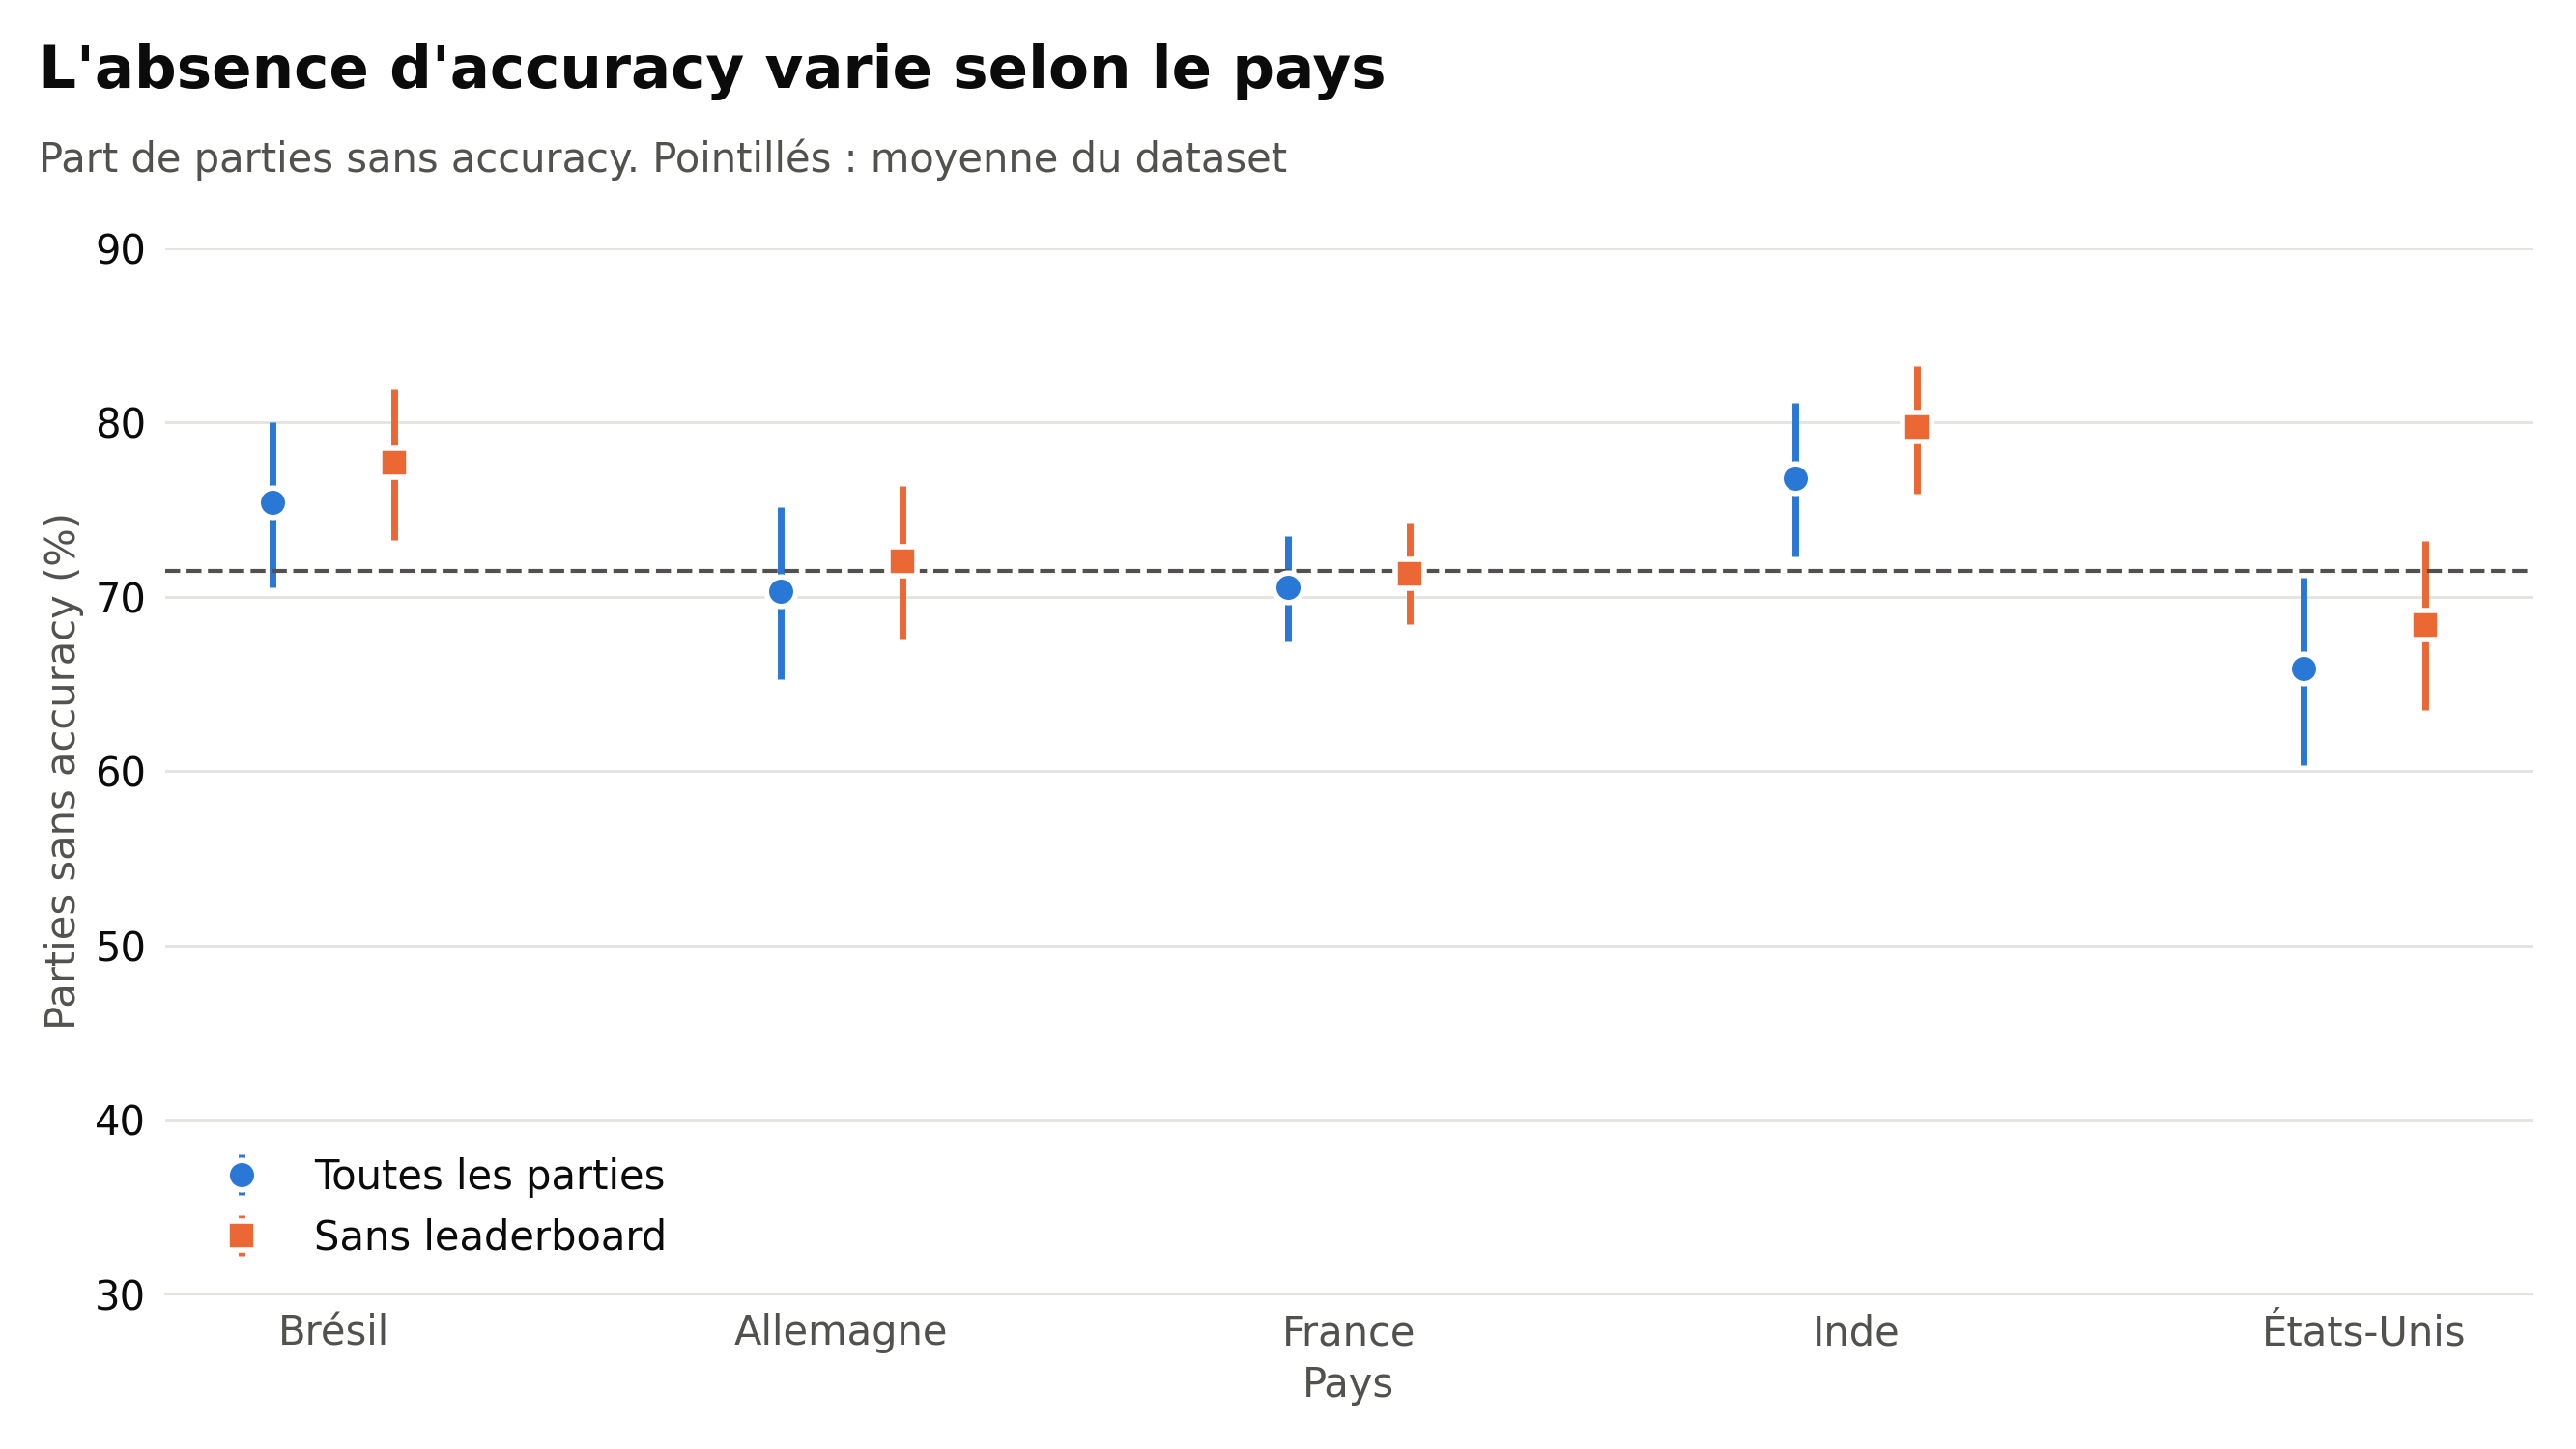

Groupe,Accuracy absente (%)
Brésil,"75,4"
Allemagne,"70,3"
France,"70,5"
Inde,"76,8"
États-Unis,"65,9"
100-400,"74,8"
400-700,"78,7"
700-1000,"74,7"
1000-1300,"76,2"
1300-1600,"74,5"


*Source : `01_eda.ipynb`*

In [6]:
show_image("figures/eda/fig07_absence_accuracy_par_pays.png", 800)
if HAS_LOCAL_DATA:
    missing = raw.merge(pd.read_csv(LOCAL["game_ids"]), on=["game_url", "username"]).merge(
        games[["game_id", "country", "elo_bin"]], on="game_id")
    missing["absente"] = missing["accuracy"].isna()
    MISSING_BY_COUNTRY = (100 * missing.groupby("country")["absente"].mean()).rename(index=COUNTRY_NAMES)
    MISSING_BY_BIN = (100 * missing.groupby("elo_bin")["absente"].mean()).reindex(BIN_ORDER)
    show_table(pd.DataFrame({"Groupe": list(MISSING_BY_COUNTRY.index) + list(MISSING_BY_BIN.index),
                             "Accuracy absente (%)": list(MISSING_BY_COUNTRY) + list(MISSING_BY_BIN)}), 1)
source("01_eda.ipynb")

**Variables exclues pour éviter les fuites.** Le modèle ne voit jamais :
- `accuracy` ni son absence, pour la raison ci-dessus ;
- `source`, l'origine de la partie dans la collecte : c'est un artefact de l'échantillonnage (η² = 0,19) ;
- `opponent_elo` : sa corrélation avec l'Elo du joueur est de 0,99, ce qui reviendrait à donner la réponse ;
- `pgn` : ses en-têtes contiennent l'Elo des deux joueurs. Le modèle ne reçoit que les 10 premiers coups.

**Ce que l'on garde.** L'ouverture et la fin de partie sont liées à l'Elo, mais elles reflètent en partie le niveau de jeu : ce sont des signaux légitimes. Certains noms d'ouverture contiennent une nationalité (« French Defense ») : c'est un indice indirect possible, discuté à la section 9.

**Première réduction du biais, dès les données.** Les quotas rendent le pays inutile pour prédire l'Elo. Un modèle entraîné sur ces données n'a aucune raison d'apprendre un lien entre pays et Elo. C'est la base de la méthode : le biais que l'on observera ensuite vient du modèle, pas des données.

## 4. Modèles de référence

> **À retenir.** Un gradient boosting atteint une MAE de 369 points (R² de 0,44) sur les 437 parties du test. C'est la barre que le LLM doit atteindre. Un modèle qui prédit toujours l'Elo médian fait 530. Comme tous les modèles de ce projet, le gradient boosting ramène les prédictions vers le centre : il surestime les faibles niveaux et sous-estime les plus forts.

Trois modèles, entraînés sur train avec les variables des prompts, pays compris (`02_baseline.ipynb`) :
- **Constante :** l'Elo médian du train. C'est le score d'un modèle qui n'a rien appris.
- **Régression linéaire.**
- **Gradient boosting** (`HistGradientBoostingRegressor`), réglé sur val.

**Indicateurs.** MAE : erreur absolue moyenne, en points d'Elo. R² : part de la variance expliquée. Bonne tranche : part des parties placées dans la bonne tranche de 300 points, c'est-à-dire la bonne poule de notre cas d'usage. Le hasard donne environ 14 % (1 tranche sur 7).

Modèle,MAE,R²,Bonne tranche (%),Erreur moyenne,MAE sans leaderboard
Constante,530,"-0,00","15,3",-29,503
Régression linéaire,377,"0,42","27,7",-10,359
Gradient boosting,369,"0,44","26,1",-4,355


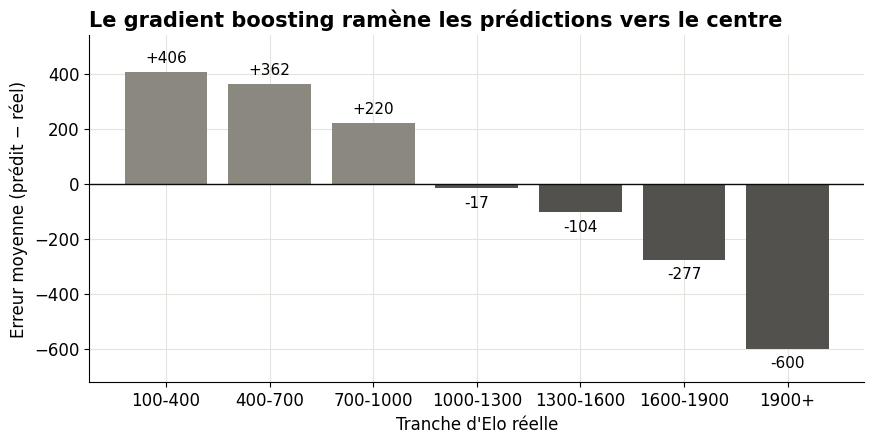

*Source : `02_baseline.ipynb`, `05_finetuning.ipynb (section 12, réentraîne les mêmes modèles)`*

In [7]:
scores = read("resultats_finetuning_complets/scores_global.csv").set_index("Modèle")
no_leaderboard = read("resultats_finetuning_complets/scores_sans_leaderboard.csv").query("Groupe == 'Global'").set_index("Modèle")
BASELINES = ["Constante", "Régression linéaire", "Gradient boosting"]
table = scores.loc[BASELINES, ["MAE", "R²", "Bonne tranche (%)", "Erreur moyenne"]].join(
    no_leaderboard["MAE"].rename("MAE sans leaderboard"))
show_table(table.rename_axis("Modèle").reset_index(), {"MAE": 0, "R²": 2, "Bonne tranche (%)": 1, "Erreur moyenne": 0, "MAE sans leaderboard": 0})

by_bin = read("resultats_finetuning_complets/scores_par_tranche.csv")
gb = by_bin[by_bin["Modèle"] == "Gradient boosting"].set_index("Groupe").reindex(BIN_ORDER)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(gb.index, gb["Erreur moyenne"], color=[COLORS["Gradient boosting"] if v < 0 else "#8a887f" for v in gb["Erreur moyenne"]])
ax.axhline(0, color="#0b0b0b", linewidth=1)
for x, value in enumerate(gb["Erreur moyenne"]):
    ax.text(x, value + (25 if value > 0 else -25), f"{value:+.0f}", ha="center", va="bottom" if value > 0 else "top", fontsize=11)
ax.set_ylim(-720, 540)
ax.set_ylabel("Erreur moyenne (prédit − réel)")
ax.set_xlabel("Tranche d'Elo réelle")
ax.set_title("Le gradient boosting ramène les prédictions vers le centre")
plt.show()
source("02_baseline.ipynb", "05_finetuning.ipynb (section 12, réentraîne les mêmes modèles)")

## 5. Les 3 méthodes d'adaptation du LLM

> **À retenir.** Le prompt engineering et le RAG font moins bien que le simple gradient boosting, et même que la médiane des voisins pour le RAG. Seul le fine-tuning QLoRA atteint le niveau des modèles de référence : MAE de 380 (FT-A) et 382 (FT-B), contre 369 pour le gradient boosting, une différence non significative. Nous retenons **FT-B** : aussi précis que FT-A, et le moins dépendant du pays.

### Protocole commun

- **Modèle :** Qwen3-4B-Instruct-2507, 4 milliards de paramètres, assez léger pour un GPU T4 gratuit (Colab ou Kaggle).
- **Consigne système :** « Tu es un expert des échecs et du classement Elo de chess.com. Tu réponds uniquement par un nombre entier, sans aucun autre texte. » Puis le prompt de la partie (section 2).
- **Décodage glouton** (`do_sample=False`, l'équivalent d'une température de 0), un prompt à la fois. On lit le premier nombre de la réponse, ramené entre 100 et 3 000. Aucune réponse n'a été illisible.
- **Mêmes 437 parties de test** que les modèles de référence, et mêmes indicateurs.
- **Deux versions de chaque prompt :** avec le pays, et sans la ligne du pays (« sans pays »).

### 5.1 Prompt engineering (`03_prompting.ipynb`)

**Principe.** On ne modifie pas le modèle : on lui donne seulement des instructions, et éventuellement des exemples.
- **Zero-shot :** la consigne, puis la partie.
- **Few-shot :** 7 parties de train placées avant la question, une par tranche d'Elo, chacune suivie de son vrai Elo, présentées comme des échanges précédents.
  - **v1** : les exemples portaient leur pays.
  - **v2** : les mêmes exemples, dans le même ordre, sans leur pays. C'est la version retenue (section 6 pour la raison).

**Réglages.** Poids en `float16`, non quantifiés. Le zero-shot sur le test est généré par lots ; tout le reste, dont le test de biais, un prompt à la fois.

In [8]:
prompting = read("resultats_prompting_v2/scores_global.csv").set_index("Modèle")
frequent = read("resultats_finetuning_complets/valeurs_frequentes.csv").set_index("Modèle")
rows = {"LLM zero-shot": "Zero-shot", "LLM zero-shot sans pays": "Zero-shot, sans pays",
        "LLM few-shot, exemples avec pays": "Few-shot v1 (exemples avec pays)", "LLM few-shot": "Few-shot v2 (exemples sans pays)"}
table = prompting.loc[list(rows), ["MAE", "R²", "Bonne tranche (%)"]].rename(index=rows)
table["Erreur moyenne"] = scores["Erreur moyenne"].reindex(list(rows)).values
table["Valeurs distinctes"] = frequent["Valeurs distinctes"].reindex(list(rows)).values
table["Valeur la plus fréquente"] = frequent["10 plus fréquentes"].reindex(list(rows)).str.split(",").str[0].values
show_table(table.rename_axis("Variante").reset_index(), {"MAE": 0, "R²": 2, "Bonne tranche (%)": 1, "Erreur moyenne": 0, "Valeurs distinctes": 0})
source("03_prompting.ipynb (resultats_prompting_v1 et v2)", "05_finetuning.ipynb (valeurs fréquentes)")

Variante,MAE,R²,Bonne tranche (%),Erreur moyenne,Valeurs distinctes,Valeur la plus fréquente
Zero-shot,644,"-0,57","14,0",460,8,1800 (44.9 %)
"Zero-shot, sans pays",624,"-0,45","13,3",402,5,1800 (40.7 %)
Few-shot v1 (exemples avec pays),510,"0,04","17,2",,,
Few-shot v2 (exemples sans pays),507,"0,06","15,6",-40,25,1024 (46.9 %)


*Source : `03_prompting.ipynb (resultats_prompting_v1 et v2)`, `05_finetuning.ipynb (valeurs fréquentes)`*

**Résultats.**
- **Zero-shot : MAE de 644, pire que la constante (530).** Le modèle surestime presque tout le monde (+460 points en moyenne) et répond 1800 pour 44,9 % des parties. Il n'utilise que 8 valeurs différentes.
- **Few-shot : MAE de 507.** Les exemples corrigent le niveau moyen, mais le modèle recopie surtout l'Elo d'un exemple : 1024 dans 46,9 % des cas. Il reste moins bon que la constante sur le R² (0,06).
- Retirer le pays des exemples (v1 → v2) ne change presque pas la précision (510 → 507). En revanche, il change beaucoup le biais (section 6).

### 5.2 RAG (`04_rag.ipynb`)

**Principe.** Pour chaque partie, on cherche les 10 parties de train les plus proches et on les met dans le prompt avec leur vrai Elo. Le modèle peut s'appuyer sur ces exemples ciblés.

**Réglages.**
- Distance euclidienne sur l'ACPL, les gaffes par coup, les erreurs, les imprécisions et le nombre de coups (standardisés), plus le résultat et la fin de partie.
- **Le pays n'entre pas dans la distance :** les 5 versions d'une partie du test de biais ont exactement les mêmes voisins. Un écart entre pays ne peut donc venir que du modèle.
- **Baseline sans LLM :** la médiane de l'Elo des 10 voisins. Si le LLM ne la bat pas, il n'apporte rien de plus que les voisins eux-mêmes.

In [9]:
rag_rows = {"Médiane des voisins": "Médiane des 10 voisins (sans LLM)", "LLM RAG": "RAG", "LLM RAG sans pays": "RAG, sans pays"}
table = scores.loc[list(rag_rows), ["MAE", "R²", "Bonne tranche (%)", "Erreur moyenne"]].rename(index=rag_rows)
show_table(table.rename_axis("Variante").reset_index(), {"MAE": 0, "R²": 2, "Bonne tranche (%)": 1, "Erreur moyenne": 0})
rag_vs = read("resultats_rag/comparaison_mae.csv").query("Modèle == 'LLM RAG'")
rag_vs = rag_vs.assign(**{"Différence de MAE [IC 95 %]": [interval(*v) for v in rag_vs[["Différence de MAE", "IC 95 % bas", "IC 95 % haut"]].values]})
show_table(rag_vs[["Comparé à", "Différence de MAE [IC 95 %]"]])
source("04_rag.ipynb")

Variante,MAE,R²,Bonne tranche (%),Erreur moyenne
Médiane des 10 voisins (sans LLM),453,"0,18","20,8",27
RAG,573,"-0,31","16,2",275
"RAG, sans pays",589,"-0,38","14,9",320


Comparé à,Différence de MAE [IC 95 %]
Médiane des voisins,+121 [+87 ; +157] *
Gradient boosting,+204 [+165 ; +244] *
Régression linéaire,+196 [+158 ; +236] *
Constante,+43 [+0 ; +87] *
LLM zero-shot,-71 [-110 ; -31] *
LLM few-shot,+66 [+22 ; +110] *


*Source : `04_rag.ipynb`*

**Résultats.** Le RAG (MAE de 573) fait mieux que le zero-shot, mais **121 points moins bien que la simple médiane de ses propres voisins**. Il surestime toujours (+275 points en moyenne). Le modèle ne sait pas tirer parti des exemples qu'on lui donne : il vaut mieux ne pas lui demander son avis.

*(Une étoile signale un intervalle qui exclut 0. Une différence négative signifie que le RAG fait mieux.)*

### 5.3 Fine-tuning QLoRA (`05_finetuning.ipynb`, exécuté sur Kaggle)

**Principe.** On entraîne un petit adaptateur LoRA sur les 3 332 parties de train, chacune avec son vrai Elo comme réponse attendue. Le modèle de base reste figé et chargé en 4 bits (QLoRA) : l'entraînement tient sur un GPU T4.

**Deux versions, qui ne diffèrent que par la ligne du pays des prompts d'entraînement :**
- **FT-A, standard :** le vrai pays du joueur ;
- **FT-B, débiaisé :** pour chaque partie, un pays tiré au hasard parmi les 5. C'est la méthode « modifier le dataset » du cours (slide 28) : le lien entre le pays écrit et l'Elo est rompu. FT-A et FT-B voient les mêmes parties, dans le même ordre, avec la même initialisation.

**Réglages** (identiques pour FT-A et FT-B) :

Réglage,Valeur
Quantification,"4 bits NF4, calculs en float16"
Adaptateur LoRA,"rang 8, alpha 16, dropout 0.05"
Couches adaptées,"q_proj, k_proj, v_proj, o_proj, gate_proj, up_proj, down_proj"
Époques,2
Taille de lot,8
Taux d'apprentissage,"0.0002, avec 5% de montée progressive"
Perte,"Seulement sur l'Elo et la fin du message, jamais sur le prompt"
Moteur,"Unsloth, GPU T4 sur Kaggle"


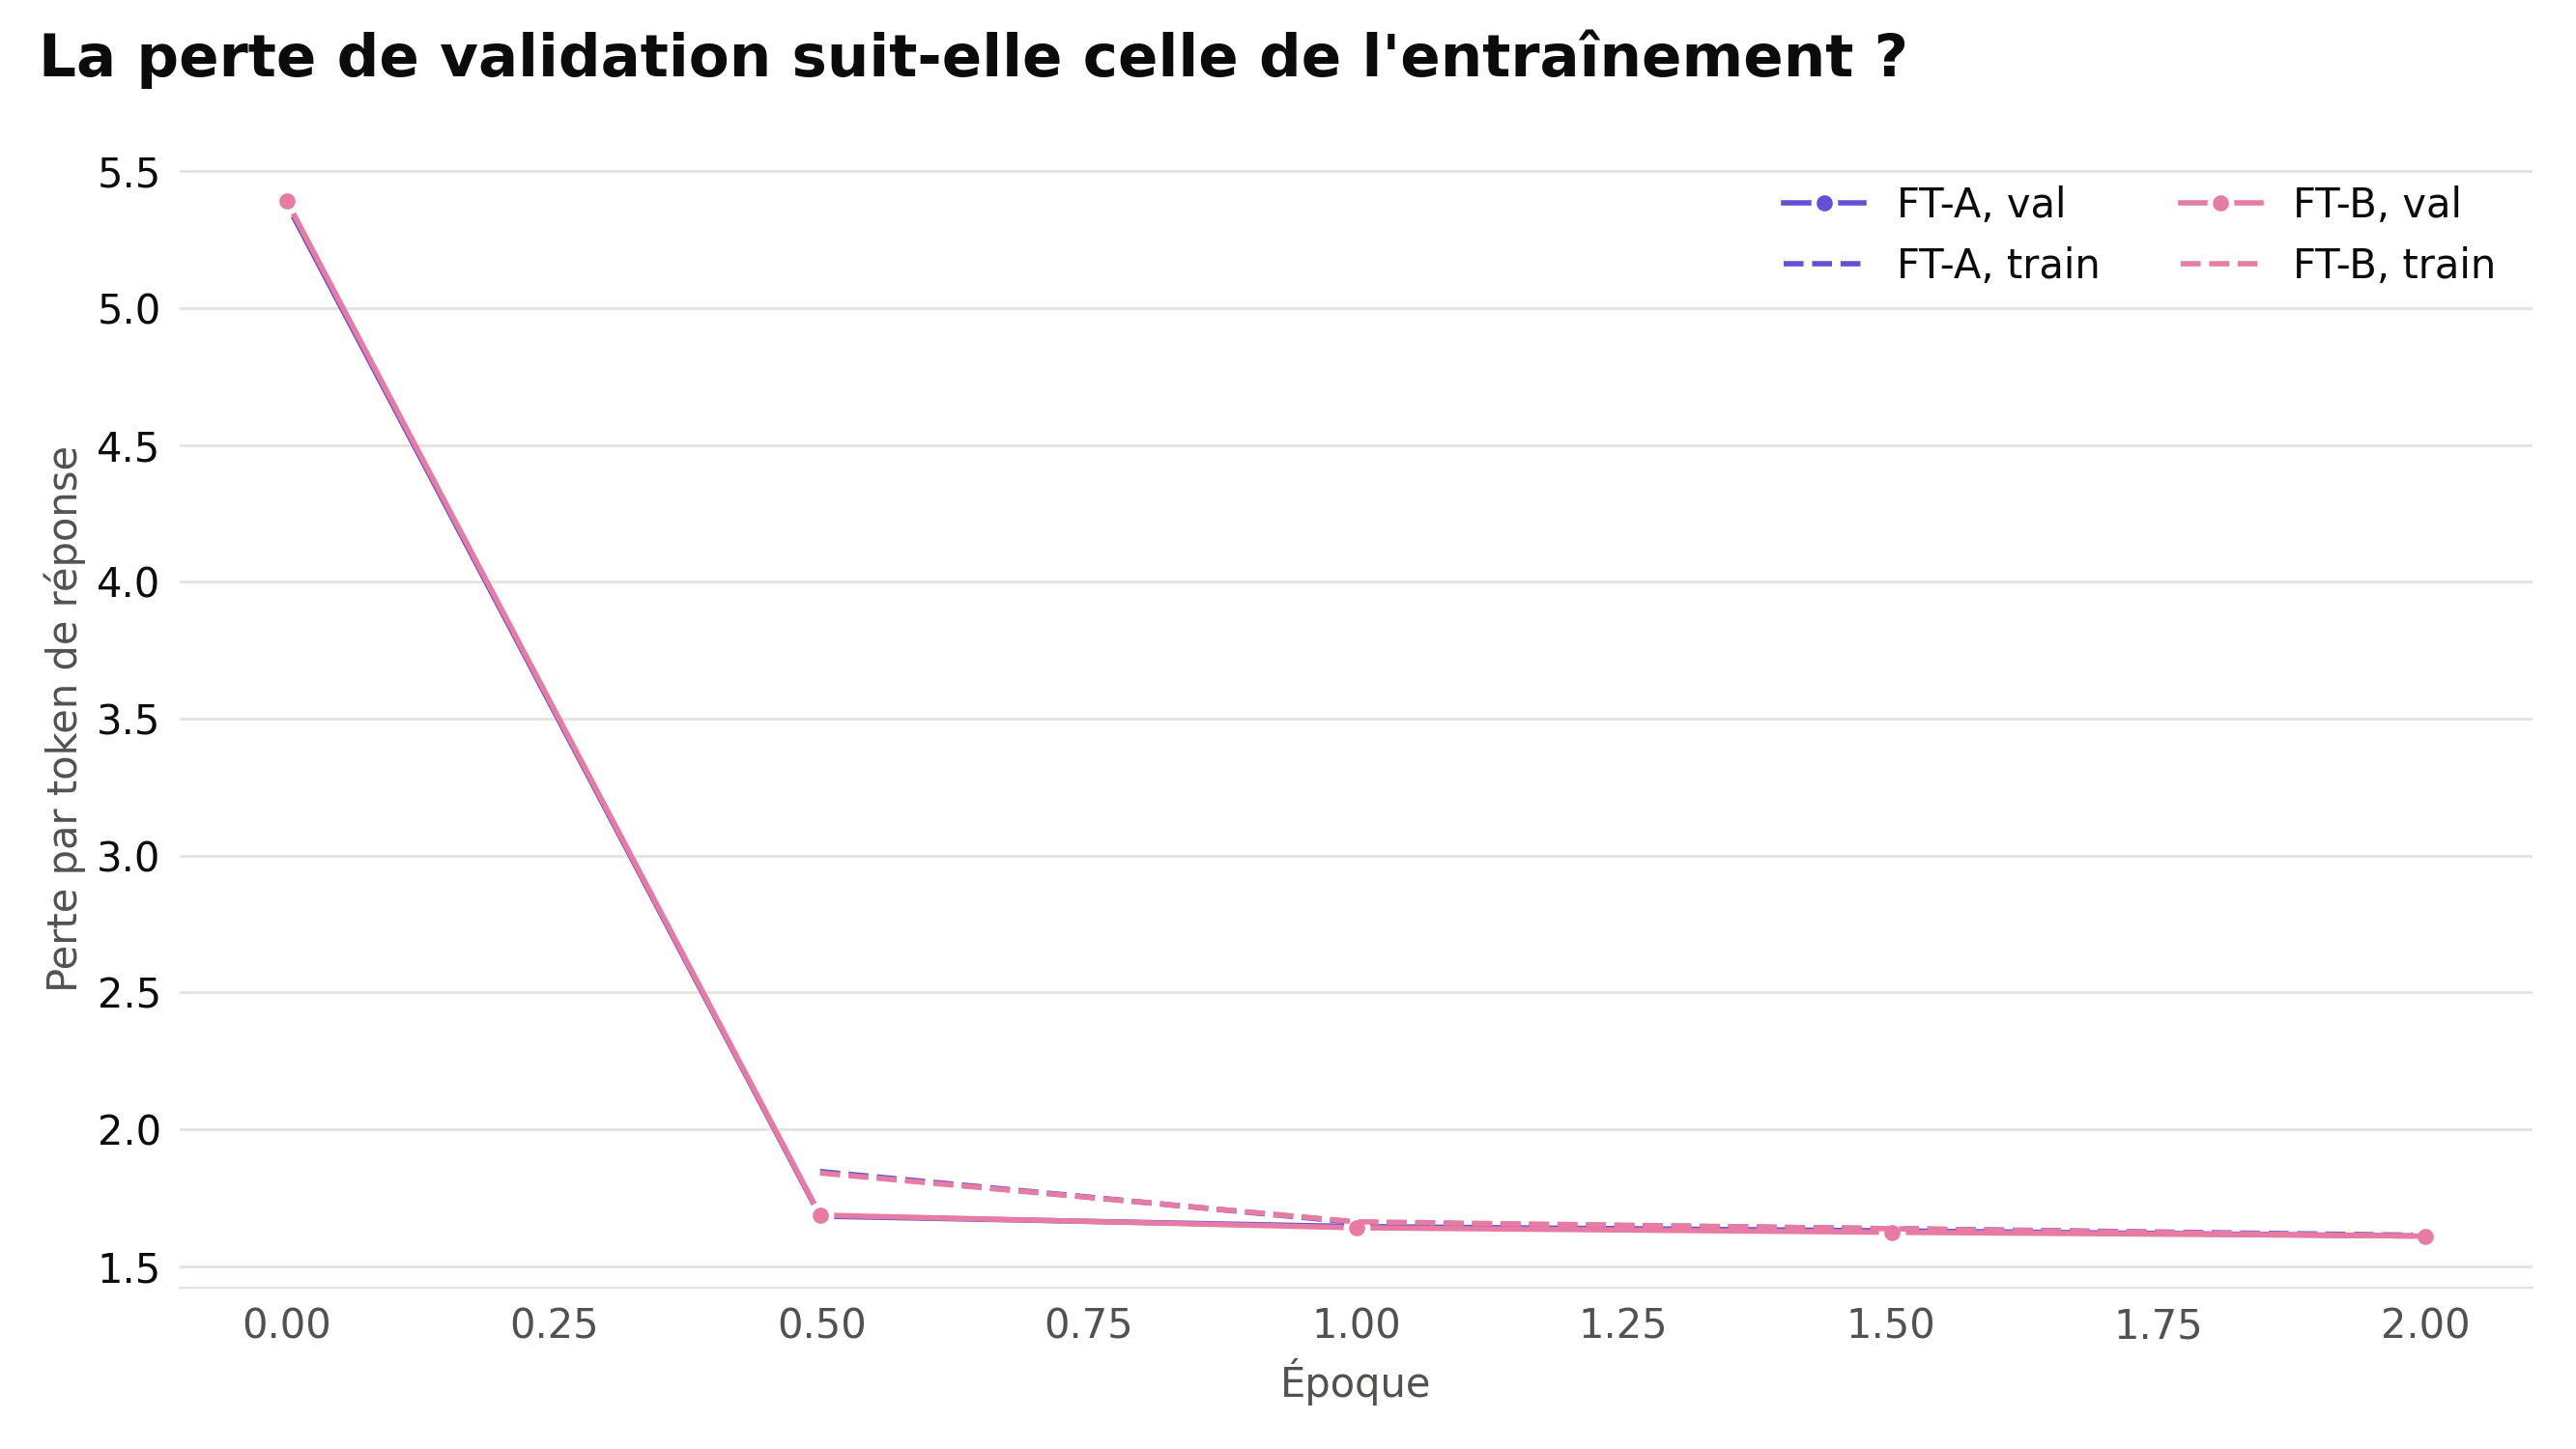

*Source : `05_finetuning.ipynb`, `05_finetuning_kaggle.ipynb`*

In [10]:
config = json.loads((ROOT / "resultats_finetuning_complets" / "config_ft_a.json").read_text(encoding="utf-8"))
assert config["settings"] == json.loads((ROOT / "resultats_finetuning_complets" / "config_ft_b.json").read_text(encoding="utf-8"))["settings"]
settings = config["settings"]
show_table(pd.DataFrame([
    ("Quantification", "4 bits NF4, calculs en float16"),
    ("Adaptateur LoRA", f"rang {settings['lora_r']}, alpha {settings['lora_alpha']}, dropout {settings['lora_dropout']}"),
    ("Couches adaptées", ", ".join(settings["lora_targets"])),
    ("Époques", settings["epochs"]),
    ("Taille de lot", settings["batch_size"]),
    ("Taux d'apprentissage", f"{settings['learning_rate']:g}, avec {settings['warmup_share']:.0%} de montée progressive"),
    ("Perte", "Seulement sur l'Elo et la fin du message, jamais sur le prompt"),
    ("Moteur", f"{config['engine']}, GPU T4 sur Kaggle"),
], columns=["Réglage", "Valeur"]))
show_image("resultats_finetuning_complets/fig_perte.png", 850)
source("05_finetuning.ipynb", "05_finetuning_kaggle.ipynb")

In [11]:
ft_rows = {"LLM FT-A": "FT-A", "LLM FT-A sans pays": "FT-A, sans pays", "LLM FT-B": "FT-B", "LLM FT-B sans pays": "FT-B, sans pays"}
table = scores.loc[list(ft_rows), ["MAE", "R²", "Bonne tranche (%)", "Erreur moyenne"]].rename(index=ft_rows)
table["Valeurs distinctes"] = frequent["Valeurs distinctes"].reindex(list(ft_rows)).values
table["Valeur la plus fréquente"] = frequent["10 plus fréquentes"].reindex(list(ft_rows)).str.split(",").str[0].values
show_table(table.rename_axis("Variante").reset_index(), {"MAE": 0, "R²": 2, "Bonne tranche (%)": 1, "Erreur moyenne": 0, "Valeurs distinctes": 0})
source("05_finetuning.ipynb (resultats_finetuning_complets)")

Variante,MAE,R²,Bonne tranche (%),Erreur moyenne,Valeurs distinctes,Valeur la plus fréquente
FT-A,380,"0,39","27,7",90,23,1677 (24.5 %)
"FT-A, sans pays",386,"0,38","26,5",83,22,1677 (23.8 %)
FT-B,382,"0,38","28,6",103,23,1777 (25.6 %)
"FT-B, sans pays",389,"0,37","28,6",99,23,1777 (25.4 %)


*Source : `05_finetuning.ipynb (resultats_finetuning_complets)`*

**Résultats.** Le fine-tuning divise presque l'erreur par deux par rapport au zero-shot : MAE de 380 pour FT-A et 382 pour FT-B, R² de 0,39 et 0,38, et 28 % de bonnes tranches, le meilleur score du projet avec la régression linéaire. Les deux versions se valent.

**Une faiblesse visible :** les prédictions se concentrent sur 23 valeurs, comme 1677 ou 1777. Le modèle génère l'Elo chiffre par chiffre, en prenant chaque fois le plus probable : il retombe souvent sur les mêmes nombres.

### 5.4 Benchmark complet et choix du modèle

Le tableau réunit la **précision** (MAE, R², bonne tranche) et l'**indépendance au pays**, mesurée par le test de biais de la section 6 :
- **Étendue du biais :** pour une partie présentée avec les 5 pays, la plus haute prédiction moins la plus basse, en moyenne. Elle vaut 0 si le pays ne change rien.
- **Parties où le pays change la prédiction**, en %.

Le biais des modèles de référence n'a pas été mesuré par ce test. La constante et la médiane des voisins sont indépendantes du pays par construction. Pour le gradient boosting, SHAP donne au pays 0,9 % de l'importance (section 7).

In [12]:
spread = read("resultats_finetuning_complets/biais_etendue_par_partie.csv").set_index("Méthode")
shap_share = read("resultats_xai/part_du_pays.csv").query("Méthode == 'SHAP'").set_index("Modèle")["Part du pays (%)"]
BENCH = {"Constante": ("Référence", "Constante"), "Régression linéaire": ("Référence", "Régression linéaire"),
         "Gradient boosting": ("Référence", "Gradient boosting"), "Médiane des voisins": ("Référence", "Médiane des voisins"),
         "Zero-shot": ("Prompt engineering", "LLM zero-shot"), "Few-shot": ("Prompt engineering", "LLM few-shot"),
         "RAG": ("RAG", "LLM RAG"), "FT-A": ("Fine-tuning", "LLM FT-A"), "FT-B": ("Fine-tuning", "LLM FT-B")}
bench = pd.DataFrame({
    "Approche": list(BENCH), "Méthode": [family for family, _ in BENCH.values()],
    "MAE": [scores.loc[row, "MAE"] for _, row in BENCH.values()],
    "R²": [scores.loc[row, "R²"] for _, row in BENCH.values()],
    "Bonne tranche (%)": [scores.loc[row, "Bonne tranche (%)"] for _, row in BENCH.values()],
    "Étendue du biais (points)": [spread["Étendue moyenne"].get(name, np.nan) for name in BENCH],
    "Pays change la prédiction (%)": [spread["Parties où le pays change la prédiction (%)"].get(name, np.nan) for name in BENCH],
    "Part du pays, SHAP (%)": [shap_share.get(name, np.nan) for name in BENCH],
})
bench.loc[bench["Approche"].isin(["Constante", "Médiane des voisins"]), ["Étendue du biais (points)", "Pays change la prédiction (%)"]] = 0
bench.loc[bench["Approche"] == "Gradient boosting", "Part du pays, SHAP (%)"] = read("resultats_xai_baseline/part_du_pays.csv")["Part du pays (%)"].iloc[0]
show_table(bench, {"MAE": 0, "R²": 2, "Bonne tranche (%)": 1, "Étendue du biais (points)": 0, "Pays change la prédiction (%)": 0, "Part du pays, SHAP (%)": 1})
source("02_baseline.ipynb", "03_prompting.ipynb", "04_rag.ipynb", "05_finetuning.ipynb", "06_xai_kaggle.ipynb", "06b_xai_baseline.ipynb")

Approche,Méthode,MAE,R²,Bonne tranche (%),Étendue du biais (points),Pays change la prédiction (%),"Part du pays, SHAP (%)"
Constante,Référence,530,"-0,00","15,3",0,0,
Régression linéaire,Référence,377,"0,42","27,7",,,
Gradient boosting,Référence,369,"0,44","26,1",,,"0,9"
Médiane des voisins,Référence,453,"0,18","20,8",0,0,
Zero-shot,Prompt engineering,644,"-0,57","14,0",150,78,"15,5"
Few-shot,Prompt engineering,507,"0,06","15,6",120,42,
RAG,RAG,573,"-0,31","16,2",58,36,
FT-A,Fine-tuning,380,"0,39","27,7",37,13,"1,0"
FT-B,Fine-tuning,382,"0,38","28,6",16,10,"0,2"


*Source : `02_baseline.ipynb`, `03_prompting.ipynb`, `04_rag.ipynb`, `05_finetuning.ipynb`, `06_xai_kaggle.ipynb`, `06b_xai_baseline.ipynb`*

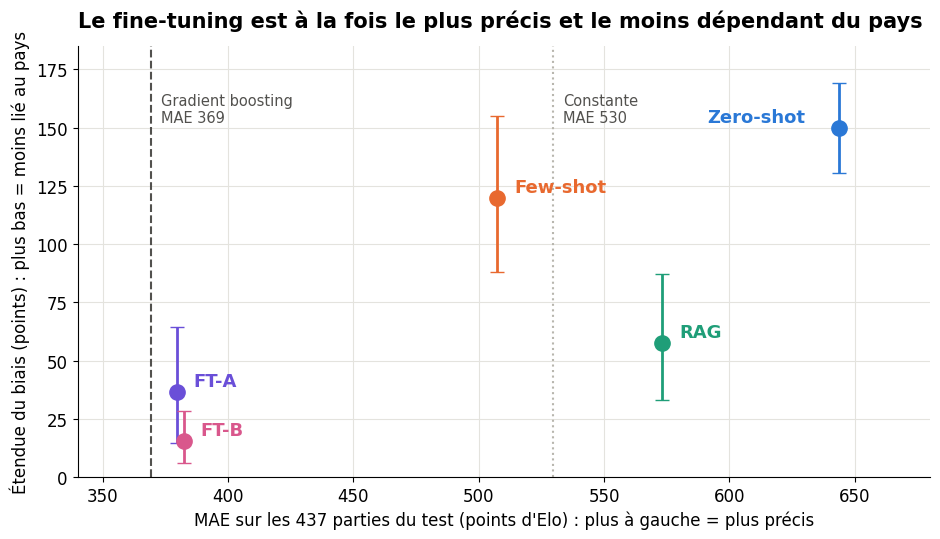

*Source : `05_finetuning.ipynb (scores_global.csv, biais_etendue_par_partie.csv)`*

In [13]:
fig, ax = plt.subplots(figsize=(11, 5.6))
for name in ["Zero-shot", "Few-shot", "RAG", "FT-A", "FT-B"]:
    row = spread.loc[name]
    mae = bench.set_index("Approche").loc[name, "MAE"]
    ax.errorbar(mae, row["Étendue moyenne"], yerr=[[row["Étendue moyenne"] - row["IC 95 % bas"]], [row["IC 95 % haut"] - row["Étendue moyenne"]]],
                fmt="o", markersize=11, color=COLORS[name], capsize=5, linewidth=2)
    ax.annotate(name, (mae, row["Étendue moyenne"]), xytext=(-95 if name == "Zero-shot" else 12, 4), textcoords="offset points", fontsize=13, color=COLORS[name], weight="bold")
for name, style in [("Gradient boosting", "--"), ("Constante", ":")]:
    value = bench.set_index("Approche").loc[name, "MAE"]
    ax.axvline(value, color=COLORS[name], linestyle=style, linewidth=1.5)
    ax.text(value + 4, 165, f"{name}\nMAE {value:.0f}", fontsize=10.5, color="#52514e", va="top")
ax.set_xlim(340, 680)
ax.set_ylim(0, 185)
ax.set_xlabel("MAE sur les 437 parties du test (points d'Elo) : plus à gauche = plus précis")
ax.set_ylabel("Étendue du biais (points) : plus bas = moins lié au pays")
ax.set_title("Le fine-tuning est à la fois le plus précis et le moins dépendant du pays", pad=14)
plt.show()
source("05_finetuning.ipynb (scores_global.csv, biais_etendue_par_partie.csv)")

In [14]:
mae_diff = read("resultats_finetuning_complets/comparaison_mae.csv")
pairs = [("LLM FT-B", "Gradient boosting"), ("LLM FT-A", "Gradient boosting"), ("LLM FT-B", "LLM FT-A"), ("LLM FT-B", "LLM zero-shot"),
         ("LLM FT-B", "LLM few-shot"), ("LLM FT-B", "LLM RAG")]
selected = pd.concat([mae_diff[(mae_diff["Modèle"] == a) & (mae_diff["Comparé à"] == b)] for a, b in pairs])
selected["Différence de MAE [IC 95 %]"] = [interval(*v) for v in selected[["Différence de MAE", "IC 95 % bas", "IC 95 % haut"]].values]
show_table(selected[["Modèle", "Comparé à", "Différence de MAE [IC 95 %]"]].replace({"LLM ": ""}, regex=True))
source("05_finetuning.ipynb (comparaison_mae.csv)")

Modèle,Comparé à,Différence de MAE [IC 95 %]
FT-B,Gradient boosting,+13 [-17 ; +43]
FT-A,Gradient boosting,+10 [-17 ; +37]
FT-B,FT-A,+3 [-15 ; +20]
FT-B,zero-shot,-262 [-305 ; -219] *
FT-B,few-shot,-125 [-166 ; -84] *
FT-B,RAG,-191 [-234 ; -149] *


*Source : `05_finetuning.ipynb (comparaison_mae.csv)`*

**Le modèle retenu : FT-B.**

1. **Précision.** FT-A et FT-B sont nettement meilleurs que les autres méthodes LLM : 125 points de moins que le few-shot, 191 de moins que le RAG, 262 de moins que le zero-shot. Face au gradient boosting, l'écart (+13 points pour FT-B) n'est pas significatif : ils font jeu égal.
2. **Indépendance au pays.** FT-B a la plus petite étendue (16 points), le pays ne change sa prédiction que pour 10 % des parties, aucun écart entre pays n'est significatif (section 6), et SHAP ne lui attribue que 0,2 % de la décision (section 7).
3. **FT-B contre FT-A.** Même précision (+2,8 points, intervalle de −14,8 à +20,3). FT-B dépend moins du pays, sans que la différence soit démontrée (section 6). À précision égale, nous retenons la version débiaisée **par conception** : elle ne coûte rien et va dans le bon sens.

**Remarque honnête.** Le gradient boosting est aussi précis et bien moins coûteux, et le pays n'y pèse que 0,9 %. Pour un vrai tournoi, ce serait un choix défendable. Le LLM fine-tuné, lui, lit aussi les premiers coups et accepte du texte libre.

## 6. Biais du modèle et réduction

> **À retenir.** À partie identique, le modèle de base change sa prédiction selon le pays : −91 points pour les États-Unis, +49 pour l'Inde et l'Allemagne, par rapport à la France. Le few-shot v1 montre qu'on peut **créer** un biais par le choix des exemples. Le fine-tuning sur des données équilibrées fait disparaître ces écarts. Tirer le pays au hasard (FT-B) réduit encore l'étendue, mais ce dernier gain n'est pas démontré.

### Le test contrefactuel

- 140 parties du test, de 79 joueurs, présentées **5 fois** : seule la ligne du pays change (`bias_test.jsonl`).
- Pour chaque partie : l'Elo prédit avec un pays, moins l'Elo prédit avec la France. On fait ensuite la moyenne par pays.
- Le dataset est équilibré : le pays n'apporte aucune information utile sur l'Elo. Tout écart vient donc du modèle.

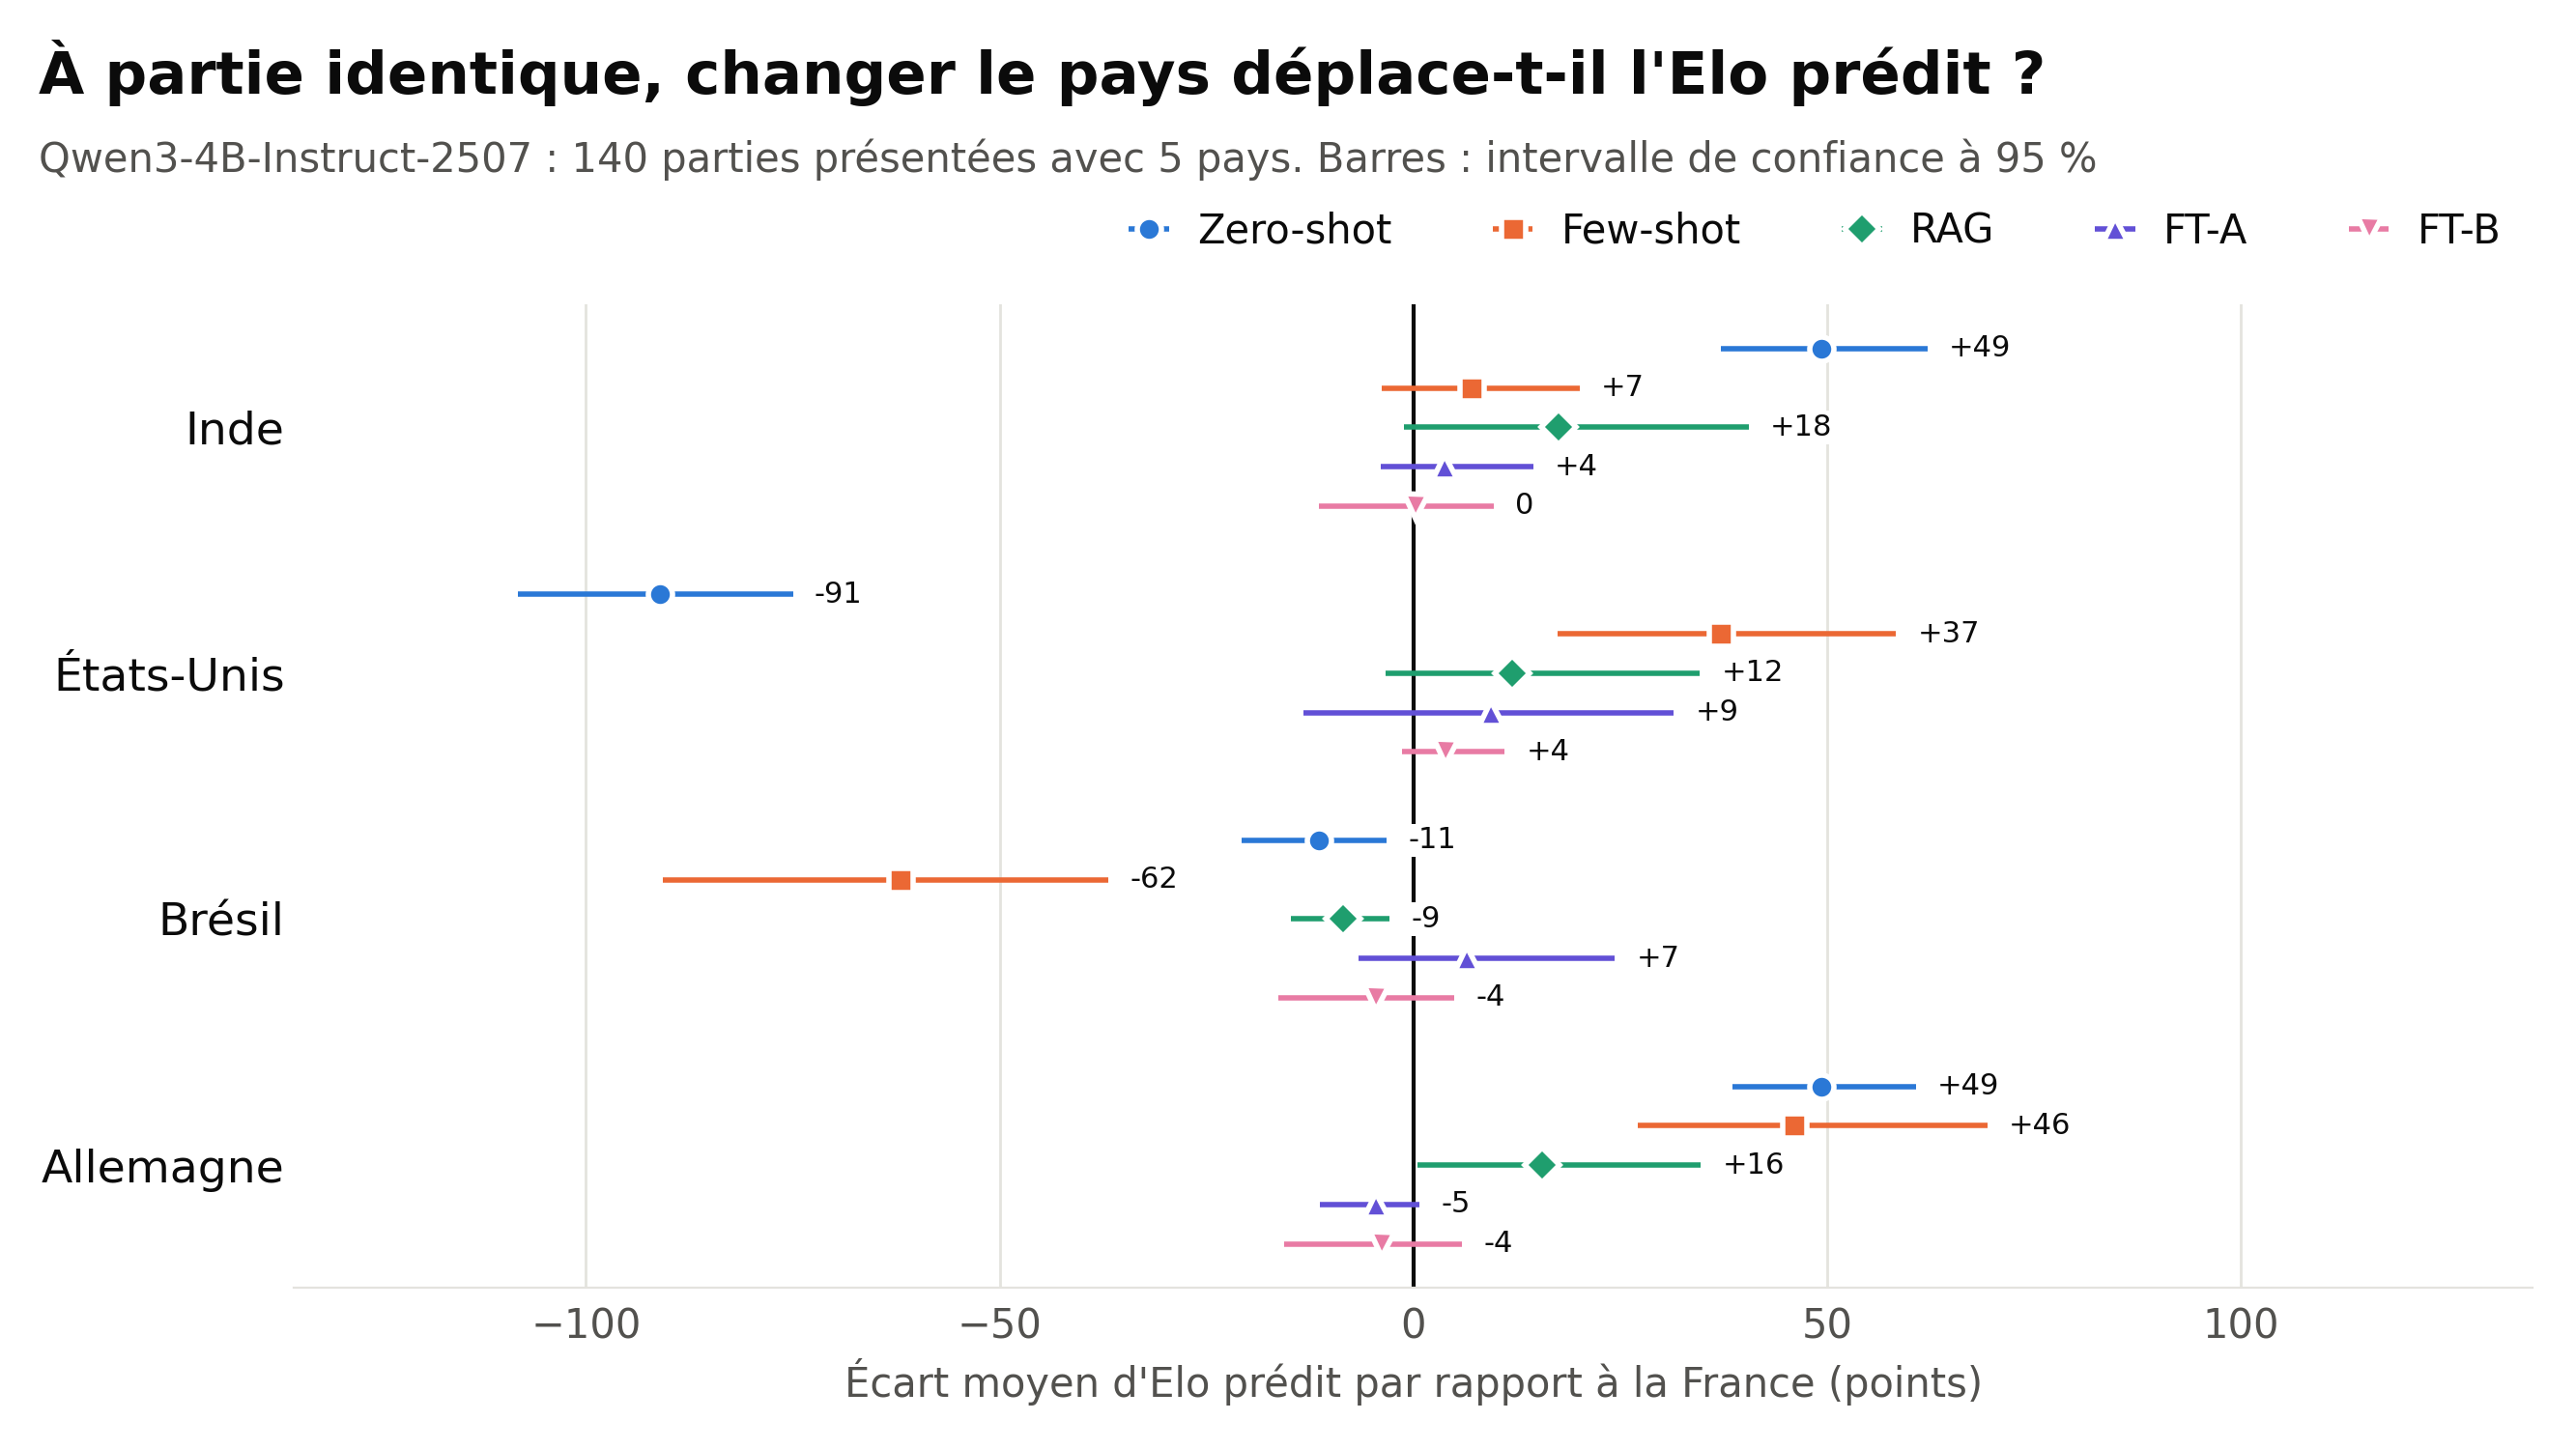

Écart à la France,Inde,États-Unis,Brésil,Allemagne
Zero-shot,+49 [+37 ; +62] *,-91 [-108 ; -75] *,-11 [-21 ; -3] *,+49 [+39 ; +61] *
Few-shot,+7 [-4 ; +20],+37 [+17 ; +58] *,-62 [-91 ; -37] *,+46 [+27 ; +69] *
RAG,+18 [-1 ; +41],+12 [-3 ; +35],-9 [-15 ; -3] *,+16 [+0 ; +35] *
FT-A,+4 [-4 ; +14],+9 [-13 ; +32],+7 [-7 ; +24],-5 [-11 ; +1]
FT-B,+0 [-11 ; +10],+4 [-1 ; +11],-4 [-16 ; +5],-4 [-16 ; +6]


*Une étoile signale un intervalle qui exclut 0 : l'écart ne s'explique probablement pas par le choix des parties.*

*Source : `03_prompting.ipynb`, `04_rag.ipynb`, `05_finetuning.ipynb (section 12)`*

In [15]:
show_image("resultats_finetuning_complets/fig_biais_pays.png", 950)
gaps = read("resultats_finetuning_complets/biais_ecarts_france.csv")
gaps["Écart [IC 95 %]"] = [interval(*v) for v in gaps[["Écart moyen", "IC 95 % bas", "IC 95 % haut"]].values]
table = gaps.pivot(index="Variante", columns="Pays", values="Écart [IC 95 %]").reindex(["Zero-shot", "Few-shot", "RAG", "FT-A", "FT-B"])
show_table(table[["Inde", "États-Unis", "Brésil", "Allemagne"]].rename_axis("Écart à la France").reset_index())
display(Markdown("*Une étoile signale un intervalle qui exclut 0 : l'écart ne s'explique probablement pas par le choix des parties.*"))
source("03_prompting.ipynb", "04_rag.ipynb", "05_finetuning.ipynb (section 12)")

In [16]:
table = spread.reindex(["Zero-shot", "Few-shot", "RAG", "FT-A", "FT-B"]).reset_index()
table["Étendue moyenne [IC 95 %]"] = [f"{m:.0f} [{l:.0f} ; {h:.0f}]" for m, l, h in table[["Étendue moyenne", "IC 95 % bas", "IC 95 % haut"]].values]
show_table(table[["Méthode", "Étendue moyenne [IC 95 %]", "Parties où le pays change la prédiction (%)"]], 0)
source("05_finetuning.ipynb (biais_etendue_par_partie.csv)")

Méthode,Étendue moyenne [IC 95 %],Parties où le pays change la prédiction (%)
Zero-shot,150 [131 ; 169],78
Few-shot,120 [88 ; 155],42
RAG,58 [33 ; 87],36
FT-A,37 [15 ; 64],13
FT-B,16 [6 ; 29],10


*Source : `05_finetuning.ipynb (biais_etendue_par_partie.csv)`*

**Lecture.** Le modèle de base a des a priori sur les pays : le seul mot « États-Unis » lui fait retirer 91 points en moyenne, et il change d'avis pour 78 % des parties. Chaque méthode réduit l'étendue : 150 points en zero-shot, 120 en few-shot, 58 en RAG, 37 pour FT-A, 16 pour FT-B. Le test ne dit pas si l'écart vient d'un stéréotype sur le pays ou d'un effet du mot lui-même.

### La leçon du few-shot v1 : un biais créé par le choix des exemples

Dans la première version du few-shot, les 7 exemples portaient leur pays et leur Elo. Le modèle a appris de ces 7 lignes un lien entre pays et Elo : l'exemple brésilien avait un Elo bas, et le Brésil perdait 243 points. En retirant seulement le pays des exemples (mêmes parties, même ordre), cet écart tombe à −62.

In [17]:
lesson = read("resultats_prompting_v2/comparaison_premiere_execution.csv").query("Variante == 'Few-shot'")
lesson["Variation [IC 95 %]"] = [interval(*v) for v in lesson[["Variation", "IC 95 % bas", "IC 95 % haut"]].values]
show_table(lesson.rename(columns={"Écart, première exécution": "v1 : exemples avec pays", "Écart, cette exécution": "v2 : exemples sans pays"})
           [["Pays", "v1 : exemples avec pays", "v2 : exemples sans pays", "Variation [IC 95 %]"]], 0)
source("03_prompting.ipynb (deuxième exécution, section 10)")

Pays,v1 : exemples avec pays,v2 : exemples sans pays,Variation [IC 95 %]
Inde,-101,7,+108 [+83 ; +133] *
États-Unis,-47,37,+84 [+56 ; +113] *
Brésil,-243,-62,+181 [+142 ; +218] *
Allemagne,72,46,-26 [-53 ; +4]


*Source : `03_prompting.ipynb (deuxième exécution, section 10)`*

**Ce qu'on en tire.** Un biais peut venir d'un détail de conception, ici 7 exemples. Il faut le mesurer à chaque changement, pas une fois pour toutes. Retirer l'attribut sensible des exemples ne suffit pourtant pas : le few-shot v2 garde des écarts significatifs (Brésil −62, Allemagne +46, États-Unis +37).

### Le test direct : FT-B fait-il mieux que FT-A ?

Partie par partie, on compare FT-B à FT-A sur les mêmes 140 parties. Une valeur négative signifie que FT-B dépend moins du pays.

In [18]:
direct = read("resultats_finetuning_complets/biais_ft_b_moins_ft_a.csv")
direct["FT-B moins FT-A [IC 95 %]"] = [interval(*v) for v in direct[["Écart moyen", "IC 95 % bas", "IC 95 % haut"]].values]
show_table(direct[["Pays", "FT-B moins FT-A [IC 95 %]"]].rename(columns={"Pays": "Écart à la France, pays"}))


def spread_by_game(model):
    predictions = read(f"resultats_finetuning_complets/predictions_{model}_bias.csv")
    table = predictions.pivot_table(index="game_id", columns="country", values="prediction")
    return table.max(axis=1) - table.min(axis=1)


spread_diff = (spread_by_game("ft_b") - spread_by_game("ft_a")).dropna()
draws = np.random.default_rng(42).choice(spread_diff.values, size=(10_000, len(spread_diff))).mean(axis=1)
SPREAD_DIFF = (spread_diff.mean(), *np.percentile(draws, [2.5, 97.5]))
print(f"Étendue, FT-B moins FT-A, sur {len(spread_diff)} parties : {interval(*SPREAD_DIFF, digits=1)}")
print(f"FT-B dépend moins du pays sur {(spread_diff < 0).sum()} parties, plus sur {(spread_diff > 0).sum()}, autant sur {(spread_diff == 0).sum()}")
source("05_finetuning.ipynb (predictions_ft_*_bias.csv), bootstrap sur les parties recalculé ici")

"Écart à la France, pays",FT-B moins FT-A [IC 95 %]
Inde,-4 [-19 ; +9]
États-Unis,-6 [-29 ; +18]
Brésil,-11 [-32 ; +6]
Allemagne,+1 [-13 ; +12]


Étendue, FT-B moins FT-A, sur 140 parties : -20,9 [-51,3 ; +5,3]
FT-B dépend moins du pays sur 17 parties, plus sur 13, autant sur 110


*Source : `05_finetuning.ipynb (predictions_ft_*_bias.csv), bootstrap sur les parties recalculé ici`*

**Lecture.** FT-B réduit l'étendue de 21 points en moyenne, mais l'intervalle va de −51 à +5 : il contient 0. Sur 109 des 140 parties, ni FT-A ni FT-B ne changent leur prédiction, quel que soit le pays. Il y a donc peu de biais à corriger après FT-A. C'est logique : le train est équilibré par quotas, FT-A n'avait aucun lien réel entre pays et Elo à apprendre.

**Le pays aide-t-il à prédire ?** Non. Sur le test, retirer le pays ne change pas l'erreur de façon significative (−6,7 points pour FT-A, intervalle de −15,2 à +0,6). Le mentionner n'apporte rien à la précision.

**Bilan de la réduction du biais, en trois couches :**
1. **Données équilibrées** par quotas : il n'y a pas de lien entre pays et Elo à apprendre (section 3).
2. **Fine-tuning sur des données réelles** : le modèle remplace ses a priori par ce que montrent les parties. L'étendue passe de 150 à 37 points.
3. **Pays tiré au hasard** à l'entraînement (FT-B) : l'étendue passe à 16 points, dans le bon sens, mais sans gain démontré face à FT-A.

## 7. XAI : expliquer les décisions avec SHAP et LIME

> **À retenir.** SHAP mesure ce que chaque ligne du prompt change à l'Elo prédit. Le pays représente 15,5 % de la décision du modèle de base (2e variable sur 12), contre 1,0 % pour FT-A et 0,2 % pour FT-B. Le modèle de base juge surtout le **résultat** de la partie. Les modèles fine-tunés regardent la **qualité du jeu** : ACPL, ouverture et premiers coups. LIME confirme le classement, avec plus de bruit.

### Méthode (`06_xai.ipynb`, exécuté sur Kaggle avec `06_xai_kaggle.ipynb`)

- Chaque modèle est vu comme une fonction : 12 variables (les lignes du prompt) → Elo prédit.
- **Masquer une variable**, c'est remplacer sa ligne par celle d'une partie de « fond » : 25 parties de train, 5 par pays.
- **SHAP par permutations antithétiques :** on part d'une partie du fond, on redonne une à une les vraies variables dans un ordre tiré au hasard, puis dans l'ordre inverse. Ce que chaque étape change à la prédiction est la contribution de la variable.
- **LIME :** une régression ridge pondérée (`LimeBase`) sur « cette variable a-t-elle sa vraie valeur ? », à partir des mêmes prédictions et de tirages supplémentaires.
- **12 parties du test** expliquées, 2 par tranche d'Elo environ, au plus 150 appels au modèle par partie. Les 3 modèles passent par exactement les mêmes prompts.
- **Part du pays :** l'importance du pays divisée par la somme des 12 importances. Si toutes les variables pesaient autant, elle vaudrait 8,3 %.

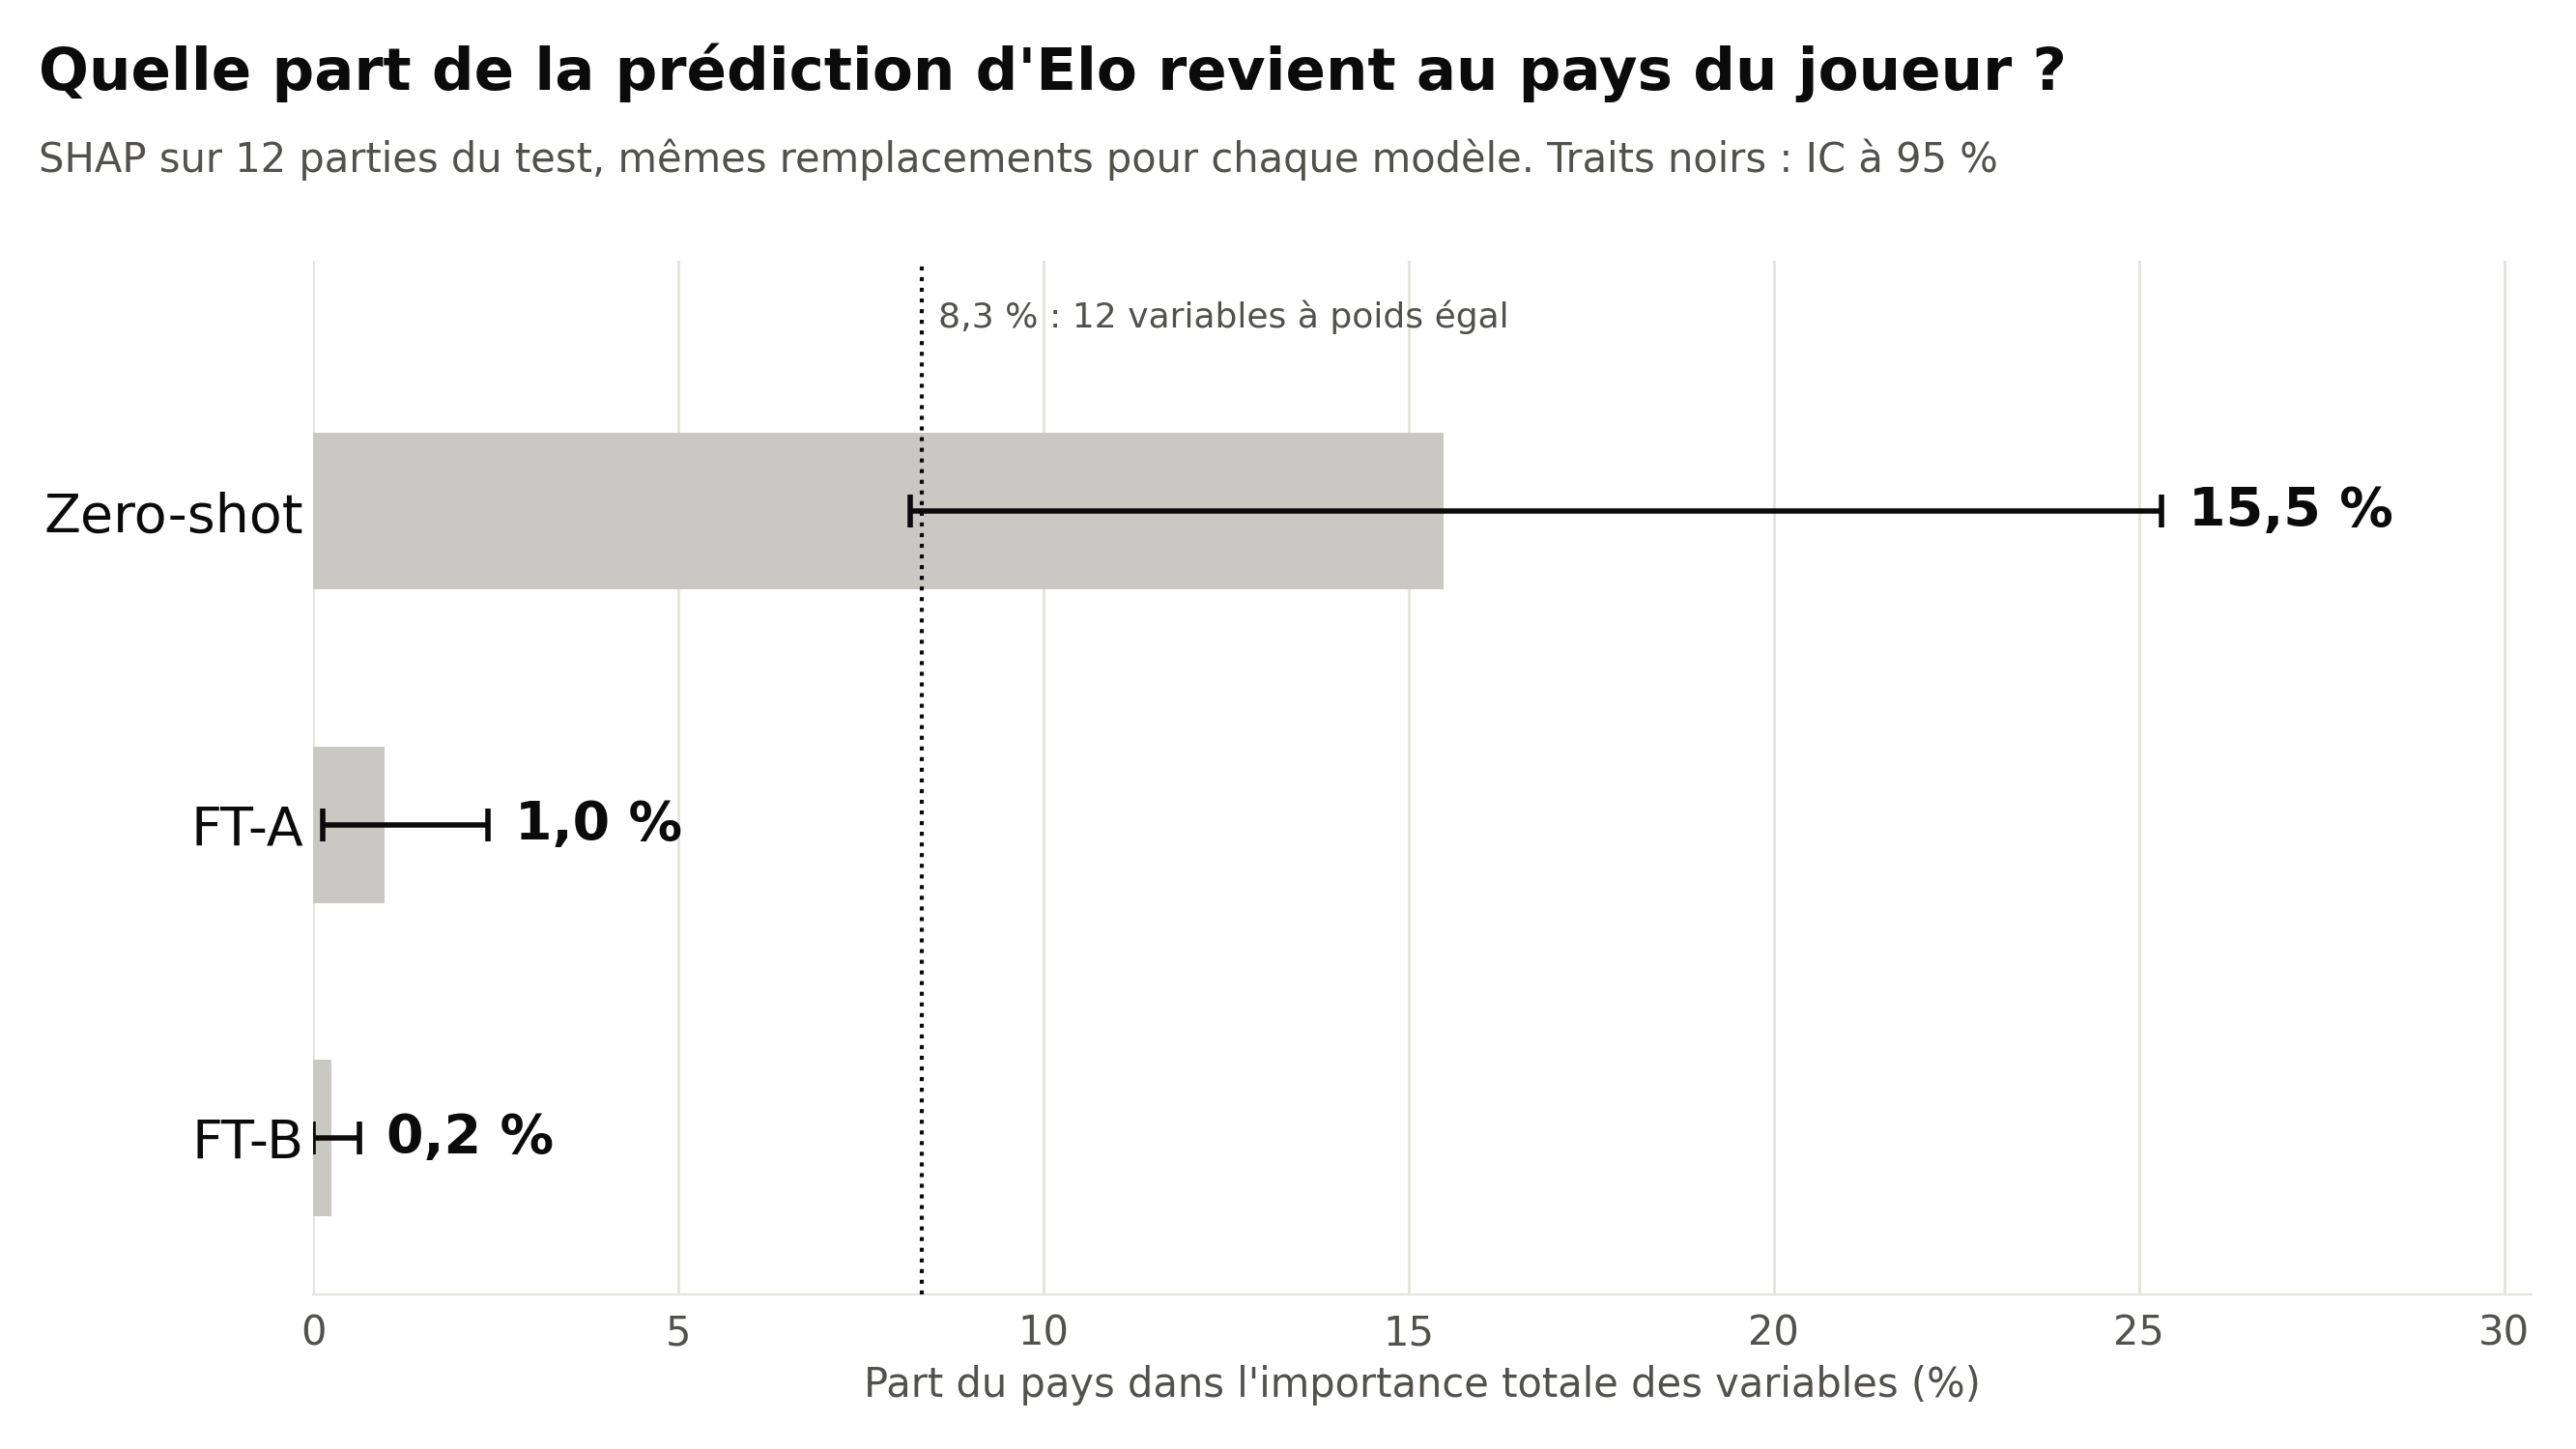

Méthode,Modèle,Part du pays (%) [IC 95 %],Rang du pays sur 12
SHAP,Zero-shot,"15,5 [8,2 ; 25,3]",2
SHAP,FT-A,"1,0 [0,1 ; 2,4]",12
SHAP,FT-B,"0,2 [0,0 ; 0,6]",11
LIME,Zero-shot,"8,8 [4,7 ; 14,0]",2
LIME,FT-A,"7,0 [4,8 ; 9,1]",6
LIME,FT-B,"5,8 [4,4 ; 7,2]",7


Méthode,Comparaison,Écart de part (points) [IC 95 %]
SHAP,FT-A moins Zero-shot,"-14,5 [-24,1 ; -7,6] *"
SHAP,FT-B moins Zero-shot,"-15,2 [-24,9 ; -8,0] *"
SHAP,FT-B moins FT-A,"-0,7 [-2,2 ; +0,3]"
LIME,FT-A moins Zero-shot,"-1,9 [-7,3 ; +2,6]"
LIME,FT-B moins Zero-shot,"-3,0 [-9,0 ; +1,8]"
LIME,FT-B moins FT-A,"-1,1 [-2,6 ; +0,3]"


*Source : `06_xai_kaggle.ipynb (resultats_xai)`*

In [19]:
show_image("resultats_xai/fig_part_du_pays.png", 900)
share = read("resultats_xai/part_du_pays.csv")
share["Part du pays (%) [IC 95 %]"] = [f"{m:.1f} [{l:.1f} ; {h:.1f}]".replace(".", ",") for m, l, h in share[["Part du pays (%)", "IC 95 % bas", "IC 95 % haut"]].values]
show_table(share[["Méthode", "Modèle", "Part du pays (%) [IC 95 %]", "Rang du pays sur 12"]])
differences = read("resultats_xai/part_du_pays_differences.csv")
differences["Écart de part (points) [IC 95 %]"] = [interval(*v, digits=1) for v in differences[["Écart de part (points)", "IC 95 % bas", "IC 95 % haut"]].values]
show_table(differences[["Méthode", "Comparaison", "Écart de part (points) [IC 95 %]"]])
source("06_xai_kaggle.ipynb (resultats_xai)")

**Lecture.**
- **SHAP :** le fine-tuning fait tomber la part du pays de 15,5 % à 1,0 % (FT-A) et 0,2 % (FT-B). Ces deux baisses sont significatives. L'écart entre FT-B et FT-A (−0,7 point) ne l'est pas, comme au test contrefactuel.
- **LIME :** même ordre (8,8 %, 7,0 %, 5,8 %), mais aucune différence n'est significative. LIME donne environ 5 % au pays même sur un modèle simulé où le pays n'a **aucun** effet : ces chiffres sont au niveau de son bruit.

### Quelles variables dominent ?

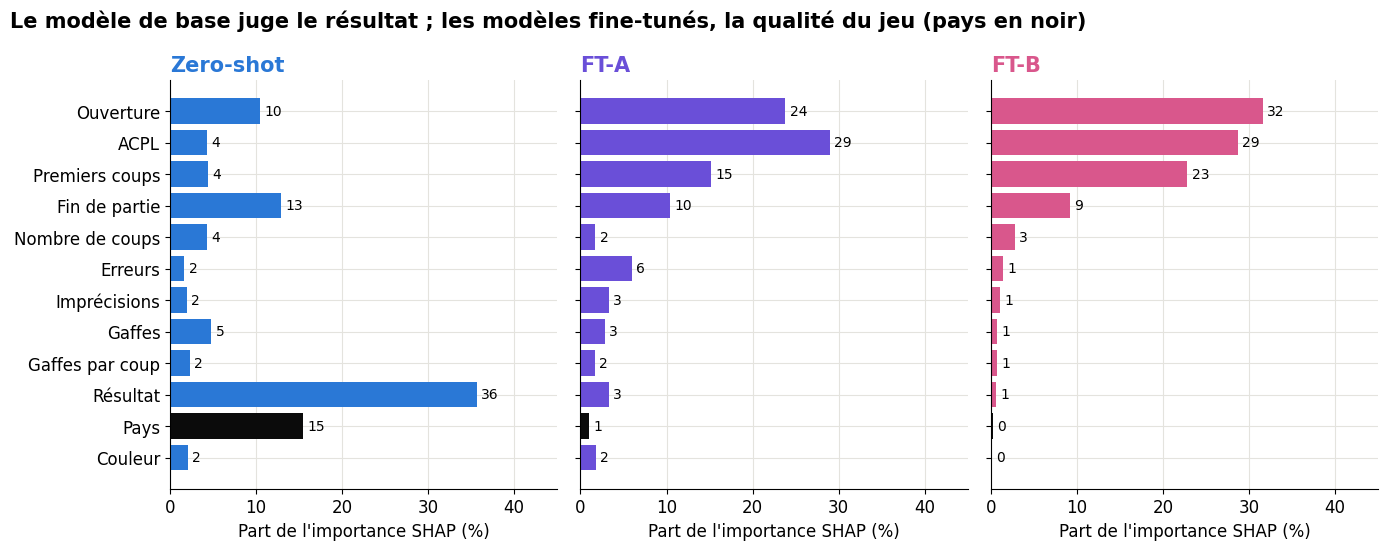

Variable,Zero-shot,FT-A,FT-B
Ouverture,"10,4","23,8","31,6"
ACPL,"4,2","29,0","28,7"
Premiers coups,"4,4","15,2","22,8"
Fin de partie,"12,9","10,4","9,2"
Nombre de coups,"4,2","1,7","2,8"
Erreurs,"1,6","6,0","1,4"
Imprécisions,"1,9","3,3","1,0"
Gaffes,"4,8","2,8","0,7"
Gaffes par coup,"2,3","1,7","0,7"
Résultat,"35,6","3,3","0,6"


*Source : `06_xai_kaggle.ipynb (importance_moyenne.csv)`*

In [20]:
importance = read("resultats_xai/importance_moyenne.csv").query("Méthode == 'SHAP'")
importance["Part (%)"] = 100 * importance["Importance"] / importance.groupby("Modèle")["Importance"].transform("sum")
models = ["Zero-shot", "FT-A", "FT-B"]
order = importance[importance["Modèle"] == "FT-B"].sort_values("Part (%)")["Variable"].tolist()
fig, axes = plt.subplots(1, 3, figsize=(14, 5.6), sharey=True)
for ax, model in zip(axes, models):
    values = importance[importance["Modèle"] == model].set_index("Variable").loc[order, "Part (%)"]
    colors = [COLORS[model] if variable != "Pays" else "#0b0b0b" for variable in order]
    ax.barh(order, values, color=colors)
    for y, value in enumerate(values):
        ax.text(value + 0.5, y, f"{value:.0f}", va="center", fontsize=10)
    ax.set_title(model, color=COLORS[model])
    ax.set_xlim(0, 45)
    ax.set_xlabel("Part de l'importance SHAP (%)")
fig.suptitle("Le modèle de base juge le résultat ; les modèles fine-tunés, la qualité du jeu (pays en noir)", x=0.01, ha="left", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()
show_table(importance.pivot(index="Variable", columns="Modèle", values="Part (%)")[models].loc[order[::-1]].reset_index(), 1)
source("06_xai_kaggle.ipynb (importance_moyenne.csv)")

**Lecture.** Le modèle de base fonde d'abord sa réponse sur le **résultat** (victoire ou défaite) et sur le **pays**, qui n'informent pas sur le niveau. Après fine-tuning, l'**ACPL**, l'**ouverture** et les **premiers coups** dominent : ce sont de vrais indicateurs du niveau de jeu. Le résultat ne compte presque plus pour FT-B.

### Une partie en détail : un joueur des États-Unis à 707 Elo

Partie g1852 du test. Le graphique en cascade part de la prédiction moyenne sur le fond, puis ajoute la contribution de chaque variable jusqu'à la prédiction. Pour le modèle de base, le seul mot « États-Unis » retire 190 points. Pour FT-A et FT-B, il ne pèse que +10 et −10 points, au niveau du bruit de l'estimation.

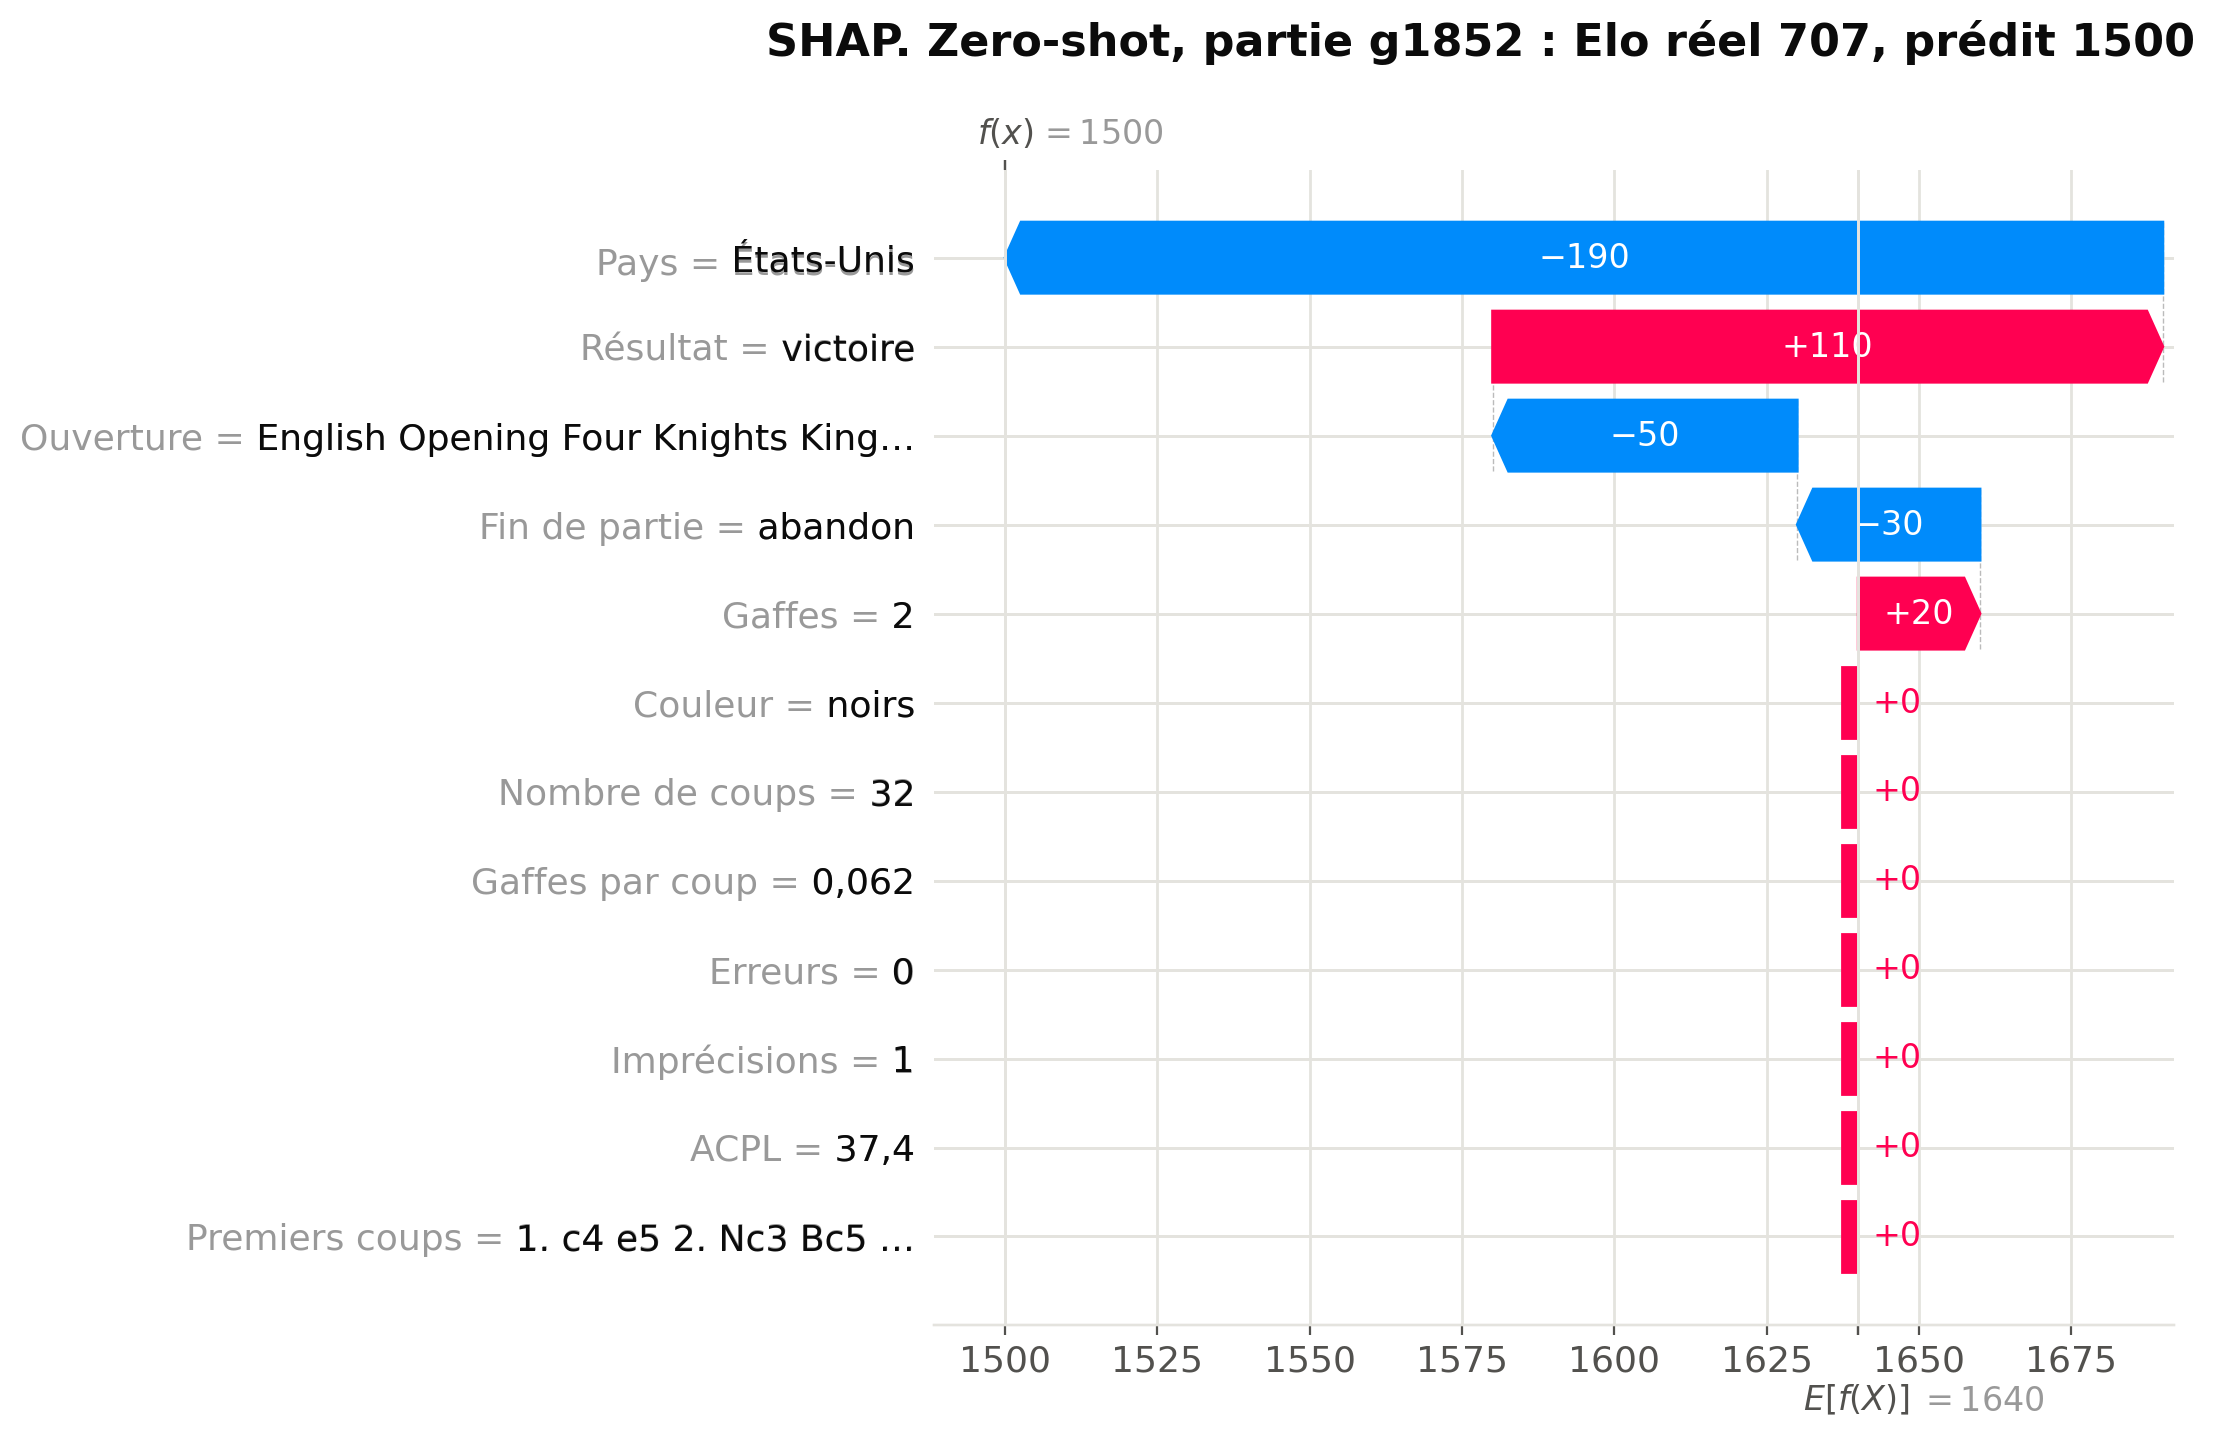

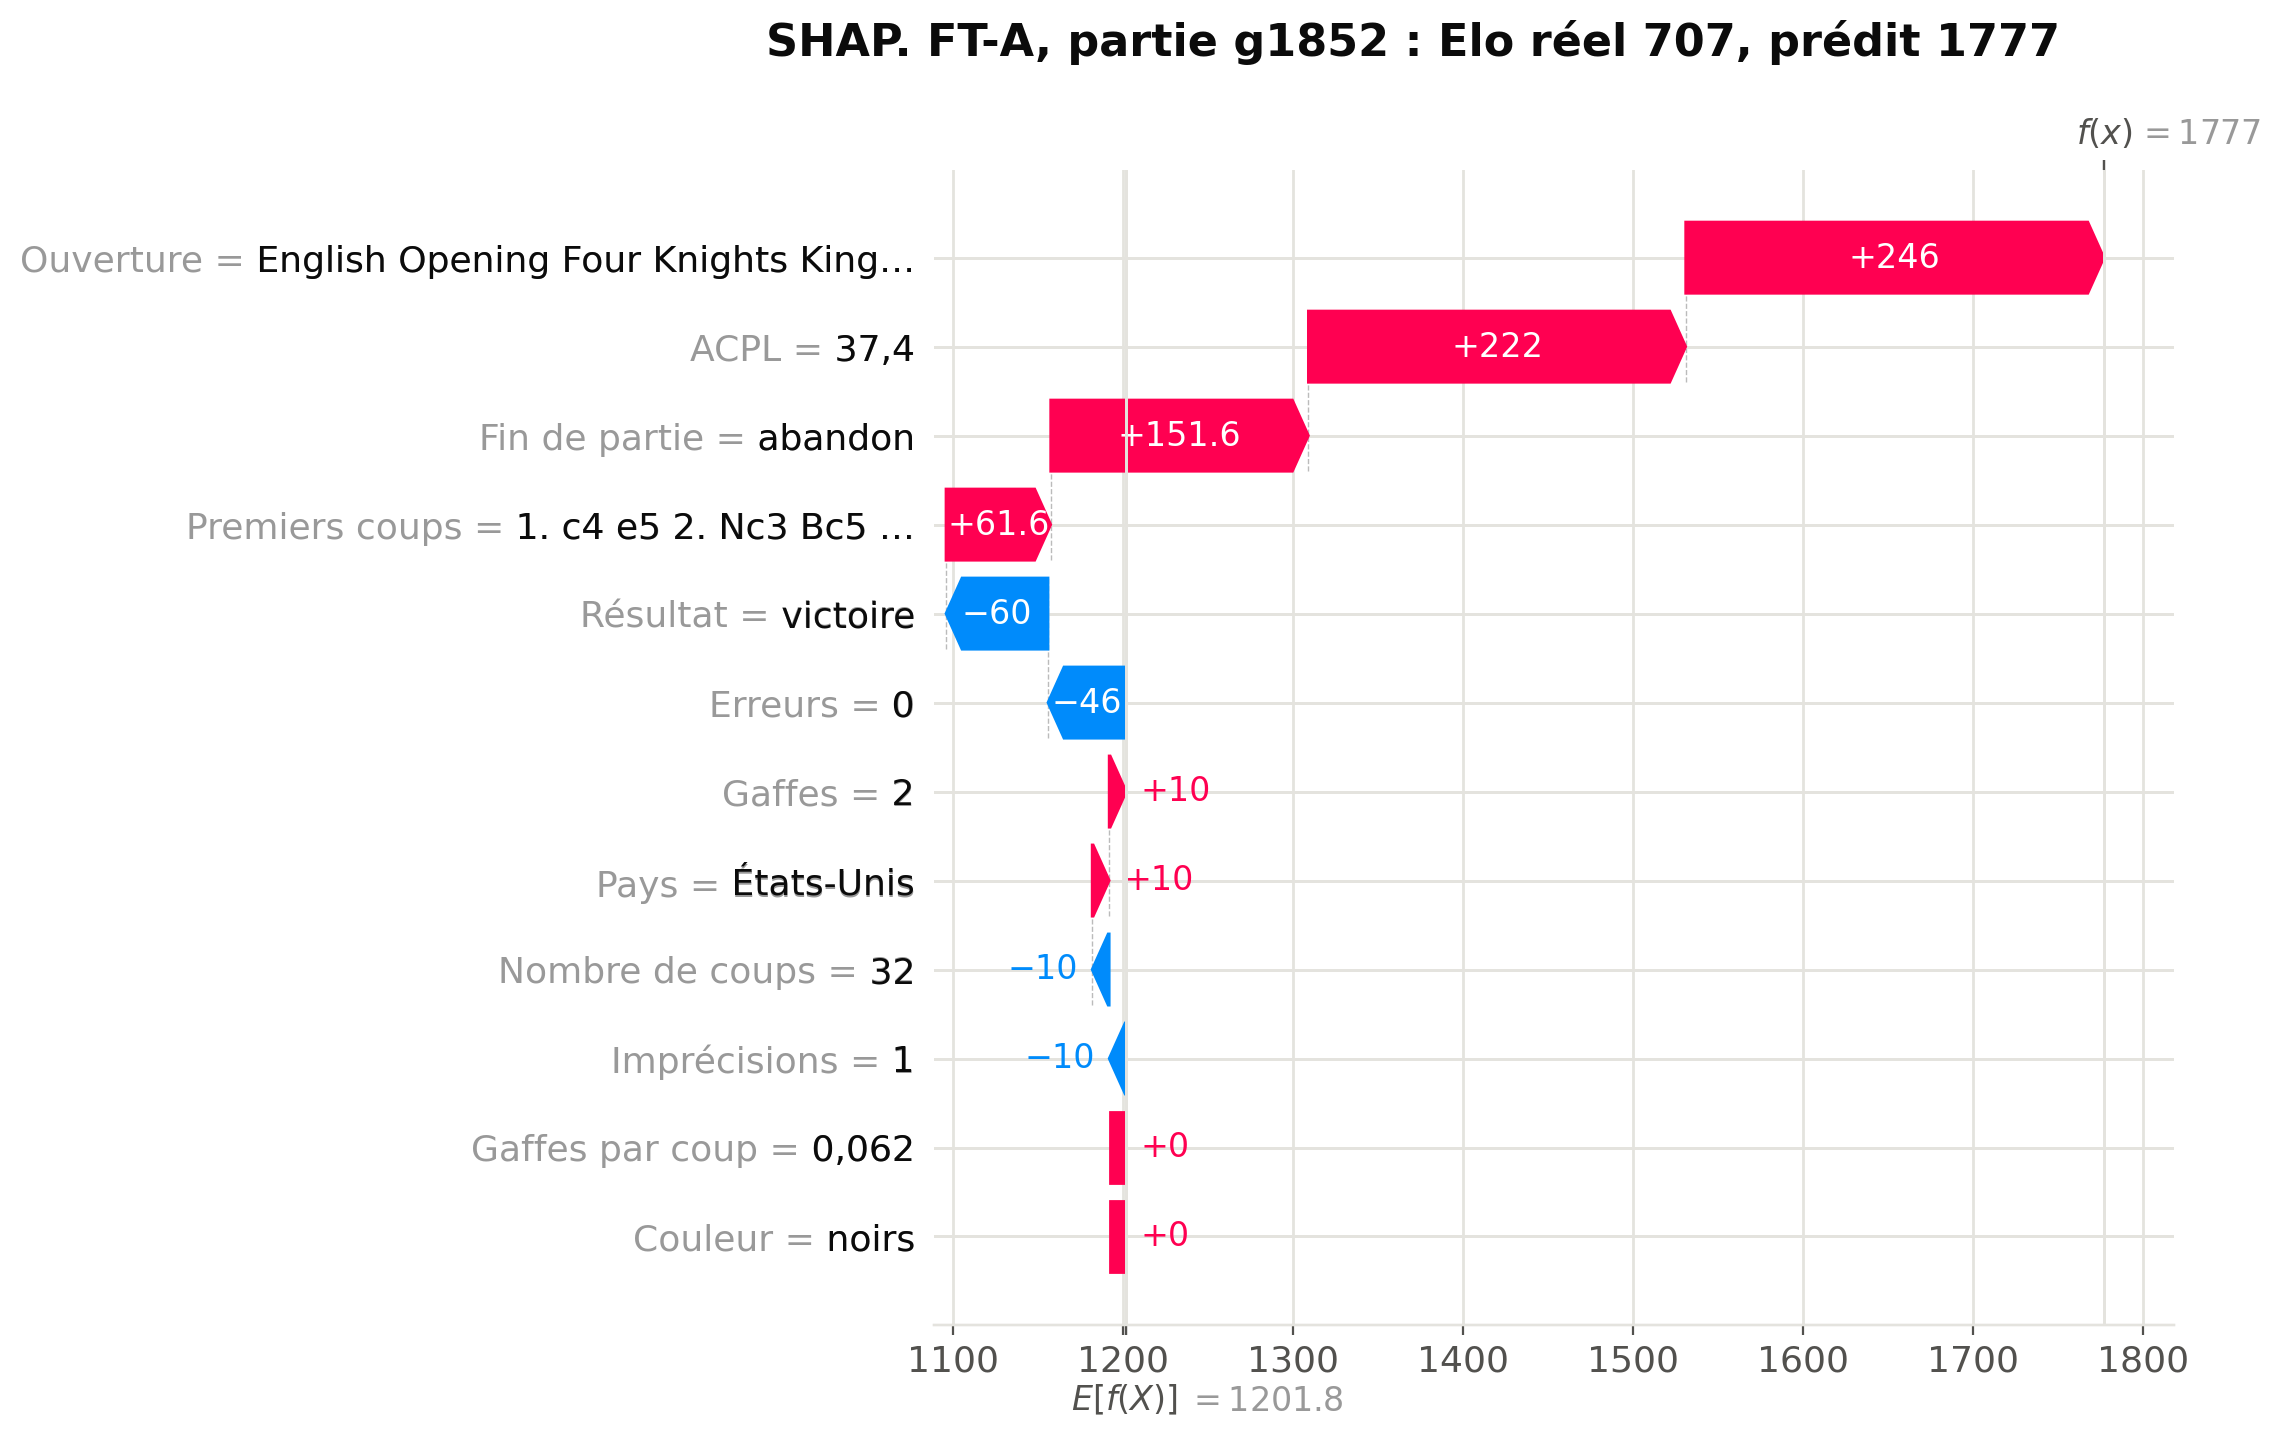

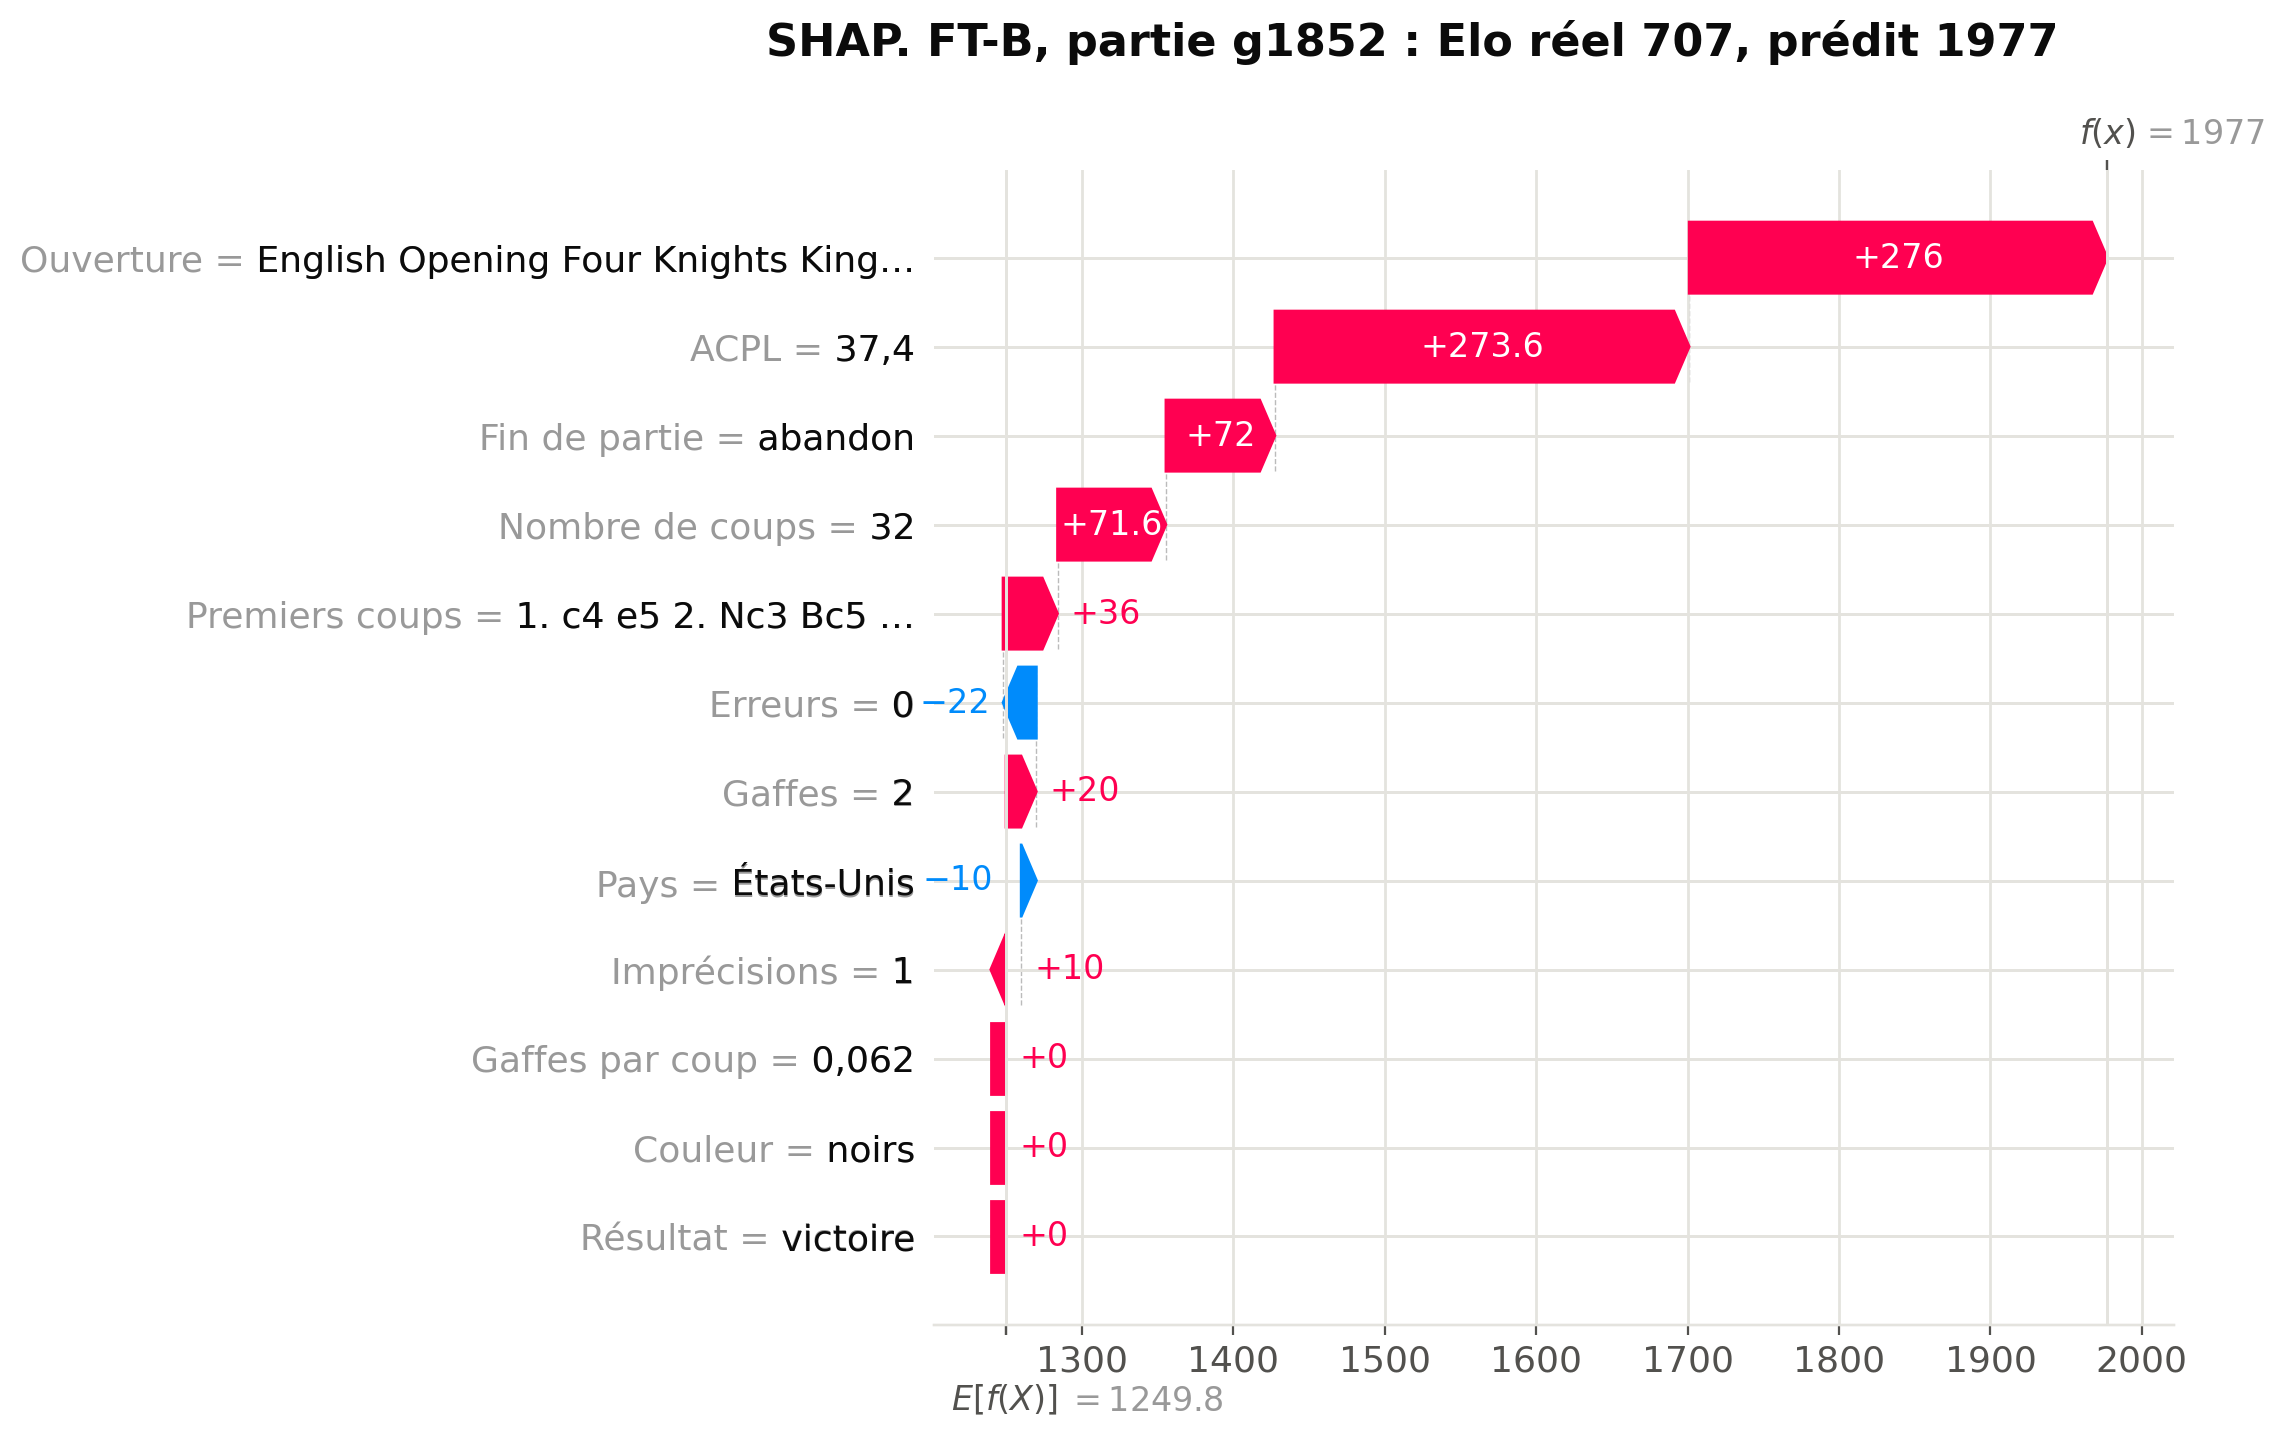

*Source : `06_xai_kaggle.ipynb`*

In [21]:
for model in ["zero_shot", "ft_a", "ft_b"]:
    show_image(f"resultats_xai/fig_waterfall_{model}_g1852.png", 760)
source("06_xai_kaggle.ipynb")

### Référence : SHAP sur le gradient boosting (`06b_xai_baseline.ipynb`)

Pour le gradient boosting, `TreeExplainer` calcule des valeurs SHAP exactes, sur les 427 parties du test hors leaderboard. Le pays y pèse 0,9 % (rang 11 sur 12), et l'ACPL 36,7 %. C'est le même profil que les modèles fine-tunés : un modèle qui apprend sur des données équilibrées n'a rien à tirer du pays.

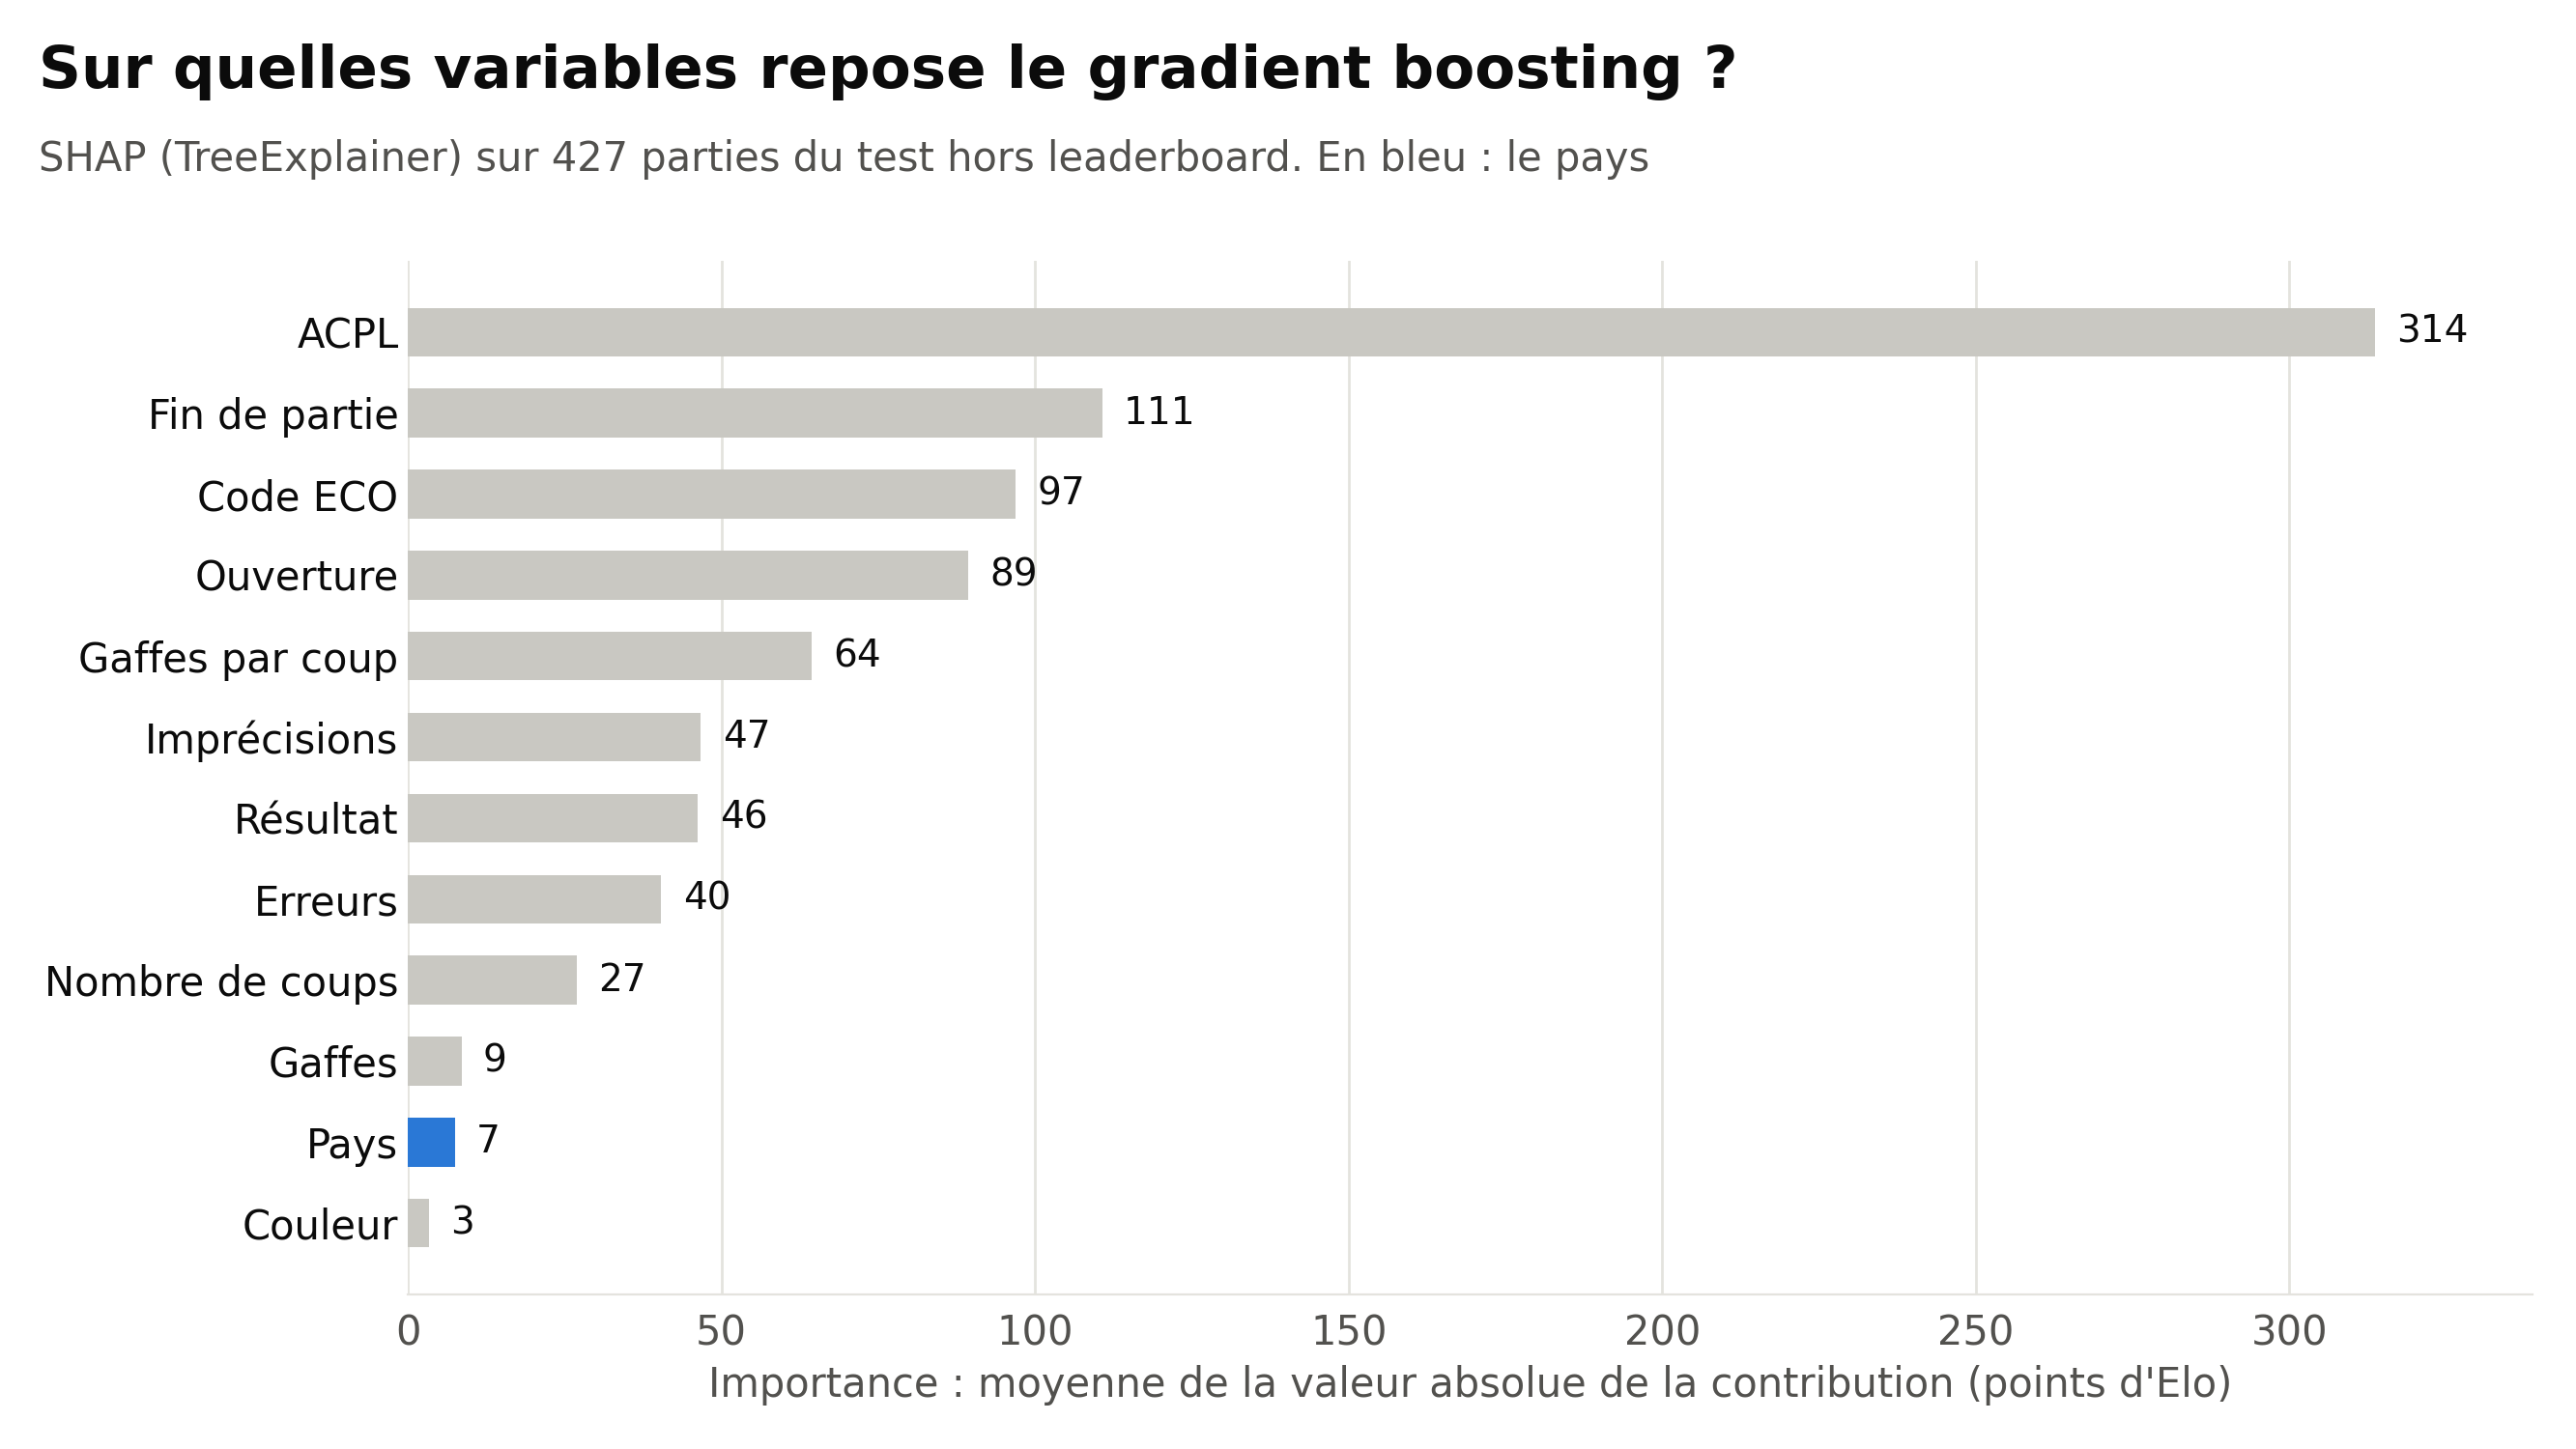

Parties,Part du pays (%),IC 95 % bas,IC 95 % haut,Rang du pays sur 12
427,"0,87","0,80","0,96",11


*Source : `06b_xai_baseline.ipynb`*

In [22]:
show_image("resultats_xai_baseline/fig_importance_globale.png", 850)
baseline_share = read("resultats_xai_baseline/part_du_pays.csv")
show_table(baseline_share[["Parties", "Part du pays (%)", "IC 95 % bas", "IC 95 % haut", "Rang du pays sur 12"]], 2)
source("06b_xai_baseline.ipynb")

### Pourquoi SHAP est la mesure principale

1. **Additivité exacte :** la valeur de base plus la somme des contributions redonne exactement la prédiction (tableau ci-dessous). LIME n'a pas cette propriété : c'est une approximation locale, dont la qualité se lit dans son R².
2. **Fiabilité sur un cas connu :** sur un modèle simulé où le pays n'a aucun effet, SHAP donne 0 au pays, LIME environ 5 %.
3. **Pas deux mesures indépendantes :** LIME réutilise les prédictions de SHAP. Leur accord confirme la lecture, sans valoir une seconde preuve.
4. **Une limite commune :** mélanger deux parties crée des prompts incohérents (une ouverture avec les coups d'une autre). Les modèles sont alors interrogés hors de ce qu'ils ont vu.

In [23]:
quality = []
for key, label in [("zero_shot", "Zero-shot"), ("ft_a", "FT-A"), ("ft_b", "FT-B")]:
    shap_values = read(f"resultats_xai/shap_{key}.csv")
    lime_values = read(f"resultats_xai/lime_{key}.csv")
    totals = shap_values.groupby("game_id").agg(base=("base", "first"), total=("shap", "sum"), prediction=("prediction", "first"))
    quality.append({"Modèle": label, "Parties expliquées": totals.shape[0],
                    "Écart d'additivité SHAP max (points)": (totals["base"] + totals["total"] - totals["prediction"]).abs().max(),
                    "R² médian de LIME": lime_values.groupby("game_id")["r2"].first().median(),
                    "Réponses illisibles": int(shap_values["illisibles"].max())})
show_table(pd.DataFrame(quality), {"Écart d'additivité SHAP max (points)": 1, "R² médian de LIME": 2})
display(Markdown("*Parties expliquées : 12 du test et 15 versions des parties de démo (section 8).*"))
source("06_xai_kaggle.ipynb")

Modèle,Parties expliquées,Écart d'additivité SHAP max (points),R² médian de LIME,Réponses illisibles
Zero-shot,27,"0,0","0,91",0
FT-A,27,"0,0","0,52",0
FT-B,27,"0,0","0,52",0


*Parties expliquées : 12 du test et 15 versions des parties de démo (section 8).*

*Source : `06_xai_kaggle.ipynb`*

## 8. Démo sur nos propres parties

> **À retenir.** Sur 12 de nos parties récentes, les modèles fine-tunés se trompent de 388 (FT-A) et 403 points (FT-B) en moyenne, contre 622 pour le modèle de base. Sur les parties de Joueur 4, écrire « États-Unis » au lieu de « France » retire 100 points à chaque fois au modèle de base, et ne change qu'une partie sur trois pour les modèles fine-tunés. Certains ratés sont nets, et nous les montrons.

*Cette section est dédiée au Joueur 4, notre ami parti vivre aux États-Unis.*

**Les données.**
- Les 3 parties rapides classées les plus récentes de chacun de nous quatre, avec les mêmes filtres que le dataset et la même analyse Stockfish (profondeur 14).
- Toutes présentées avec le pays « France ». Les 3 parties de Joueur 4 sont aussi présentées avec « États-Unis ».
- Les parties sont anonymes (`demo_j1_p1`, …) : le fichier ne contient ni prénom, ni pseudo, ni lien.

In [24]:
demo = read("resultats_xai/predictions_demo.csv")


def demo_label(game_id):
    _, player, game = game_id.split("_")[:3]
    return f"{PLAYER_NAMES[player]}, partie {game[1:]}"


demo["Partie de démo"] = demo["Partie"].map(demo_label)
france = demo[demo["Pays du prompt"] == "France"].copy()
DEMO_MODELS = {"Zero-shot": "Zero-shot, avec pays", "FT-A": "FT-A, avec pays", "FT-B": "FT-B, avec pays"}
table = france[["Partie de démo", "Elo réel"] + list(DEMO_MODELS.values())].rename(columns={v: k for k, v in DEMO_MODELS.items()})
show_table(table)
DEMO_MAE = {name: (france[column] - france["Elo réel"]).abs().mean() for name, column in DEMO_MODELS.items()}
show_table(pd.DataFrame({"Modèle": list(DEMO_MAE), "Erreur moyenne absolue sur nos 12 parties": list(DEMO_MAE.values())}))
source("06_xai_kaggle.ipynb (predictions_demo.csv)")

Partie de démo,Elo réel,Zero-shot,FT-A,FT-B
"Joueur 1, partie 1",969,1 800,1 777,1 777
"Joueur 1, partie 2",957,1 400,1 017,1 017
"Joueur 1, partie 3",969,1 400,101,101
"Joueur 2, partie 1",506,1 800,1 077,1 017
"Joueur 2, partie 2",498,1 800,1 177,1 517
"Joueur 2, partie 3",490,1 400,307,371
"Joueur 3, partie 1",844,1 500,1 077,1 017
"Joueur 3, partie 2",888,1 400,307,375
"Joueur 3, partie 3",944,1 850,1 017,1 017
"Joueur 4, partie 1",1 471,1 400,1 777,1 677


Modèle,Erreur moyenne absolue sur nos 12 parties
Zero-shot,622
FT-A,388
FT-B,403


*Source : `06_xai_kaggle.ipynb (predictions_demo.csv)`*

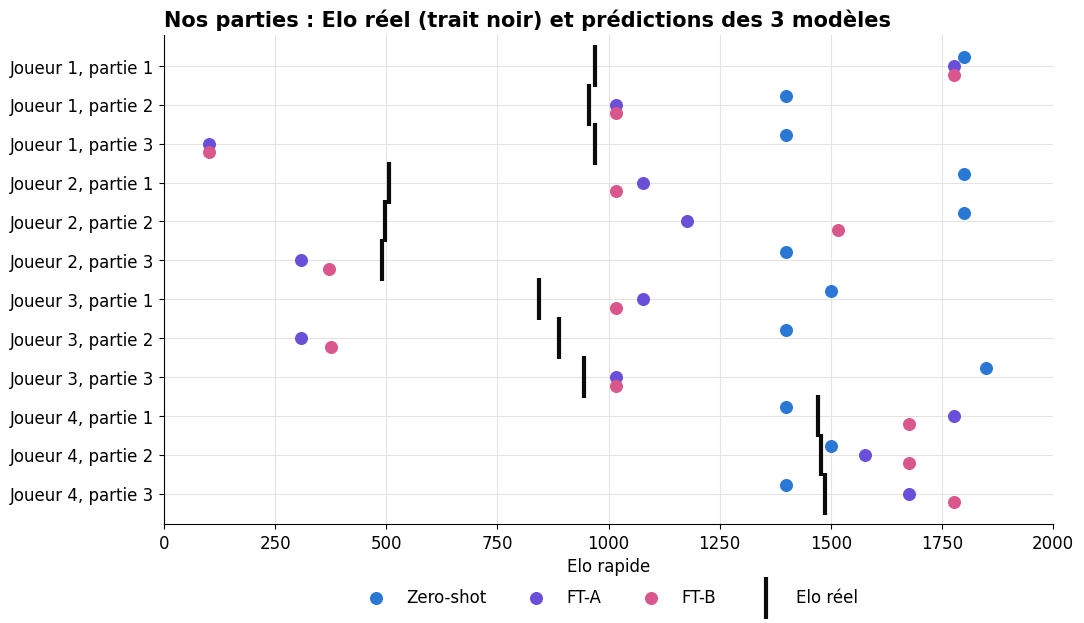

In [25]:
fig, ax = plt.subplots(figsize=(11, 6.4))
y = np.arange(len(france))[::-1]
offsets = {"Zero-shot": 0.22, "FT-A": 0, "FT-B": -0.22}
for name, column in DEMO_MODELS.items():
    ax.scatter(france[column], y + offsets[name], s=70, color=COLORS[name], label=name, zorder=3)
ax.scatter(france["Elo réel"], y, marker="|", s=900, linewidths=3, color=COLORS["Réel"], label="Elo réel", zorder=4)
ax.set_yticks(y)
ax.set_yticklabels(france["Partie de démo"])
ax.set_xlim(0, 2000)
ax.set_xlabel("Elo rapide")
ax.set_title("Nos parties : Elo réel (trait noir) et prédictions des 3 modèles")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
plt.tight_layout()
plt.show()

**Lecture.**
- **Le modèle de base répond entre 1 300 et 1 850 pour tout le monde.** Il ne distingue pas un joueur à 500 d'un joueur à 1 480. Il vise juste pour Joueur 4 (1 471 à 1 487), mais par hasard : c'est le centre de ses réponses.
- **Les modèles fine-tunés classent correctement Joueur 4 en tête** (1 577 à 1 777).
- **Les ratés assumés :**
  - partie 3 de Joueur 1 : **101** pour un joueur à 969, avec FT-A comme avec FT-B. 101 fait partie des valeurs sur lesquelles leurs prédictions se concentrent (section 5.3) ;
  - Joueur 2 (environ 500) est estimé entre 1 017 et 1 517 sur ses deux premières parties ;
  - partie 2 de Joueur 3 : 307 (FT-A) et 375 (FT-B) pour un joueur à 888.
- Avec 12 parties de 4 joueurs, ces chiffres sont une illustration, pas une mesure.

### Le test France / États-Unis sur les parties de Joueur 4

In [26]:
friend = demo[demo["Partie"].str.startswith("demo_j4")]
rows = []
for game_id, group in friend.groupby("Partie"):
    by_country = group.set_index("Pays du prompt")
    for name, column in DEMO_MODELS.items():
        rows.append({"Partie de démo": demo_label(game_id), "Modèle": name, "France": by_country.loc["France", column],
                     "États-Unis": by_country.loc["États-Unis", column]})
friend_table = pd.DataFrame(rows)
friend_table["États-Unis − France"] = friend_table["États-Unis"] - friend_table["France"]
show_table(friend_table.pivot(index="Partie de démo", columns="Modèle", values="États-Unis − France")[list(DEMO_MODELS)].reset_index())

changes = {name: int((demo[f"{name}, avec pays"] != demo[f"{name}, sans pays"]).sum()) for name in DEMO_MODELS}
print("Versions dont la prédiction change quand on retire le pays (sur 15) :", changes)
source("06_xai_kaggle.ipynb (predictions_demo.csv)")

Partie de démo,Zero-shot,FT-A,FT-B
"Joueur 4, partie 1",-100,0,100
"Joueur 4, partie 2",-100,-200,0
"Joueur 4, partie 3",-100,0,0


Versions dont la prédiction change quand on retire le pays (sur 15) : {'Zero-shot': 8, 'FT-A': 2, 'FT-B': 2}


*Source : `06_xai_kaggle.ipynb (predictions_demo.csv)`*

**Lecture.** Le modèle de base retire 100 points à Joueur 4 sur ses 3 parties dès qu'on écrit « États-Unis » : c'est le biais mesuré à la section 6 (−91 points en moyenne), visible sur une vraie personne. Les modèles fine-tunés ne bougent que sur une partie sur trois, une fois vers le bas (FT-A, −200) et une fois vers le haut (FT-B, +100) : pas de sens constant. Retirer complètement le pays change 8 prédictions sur 15 pour le modèle de base, 2 sur 15 pour les modèles fine-tunés.

Le graphique en cascade de la partie 3, version « États-Unis », montre l'explication. Pour le modèle de base, le pays retire 105 points. Pour FT-B, il ne pèse rien.

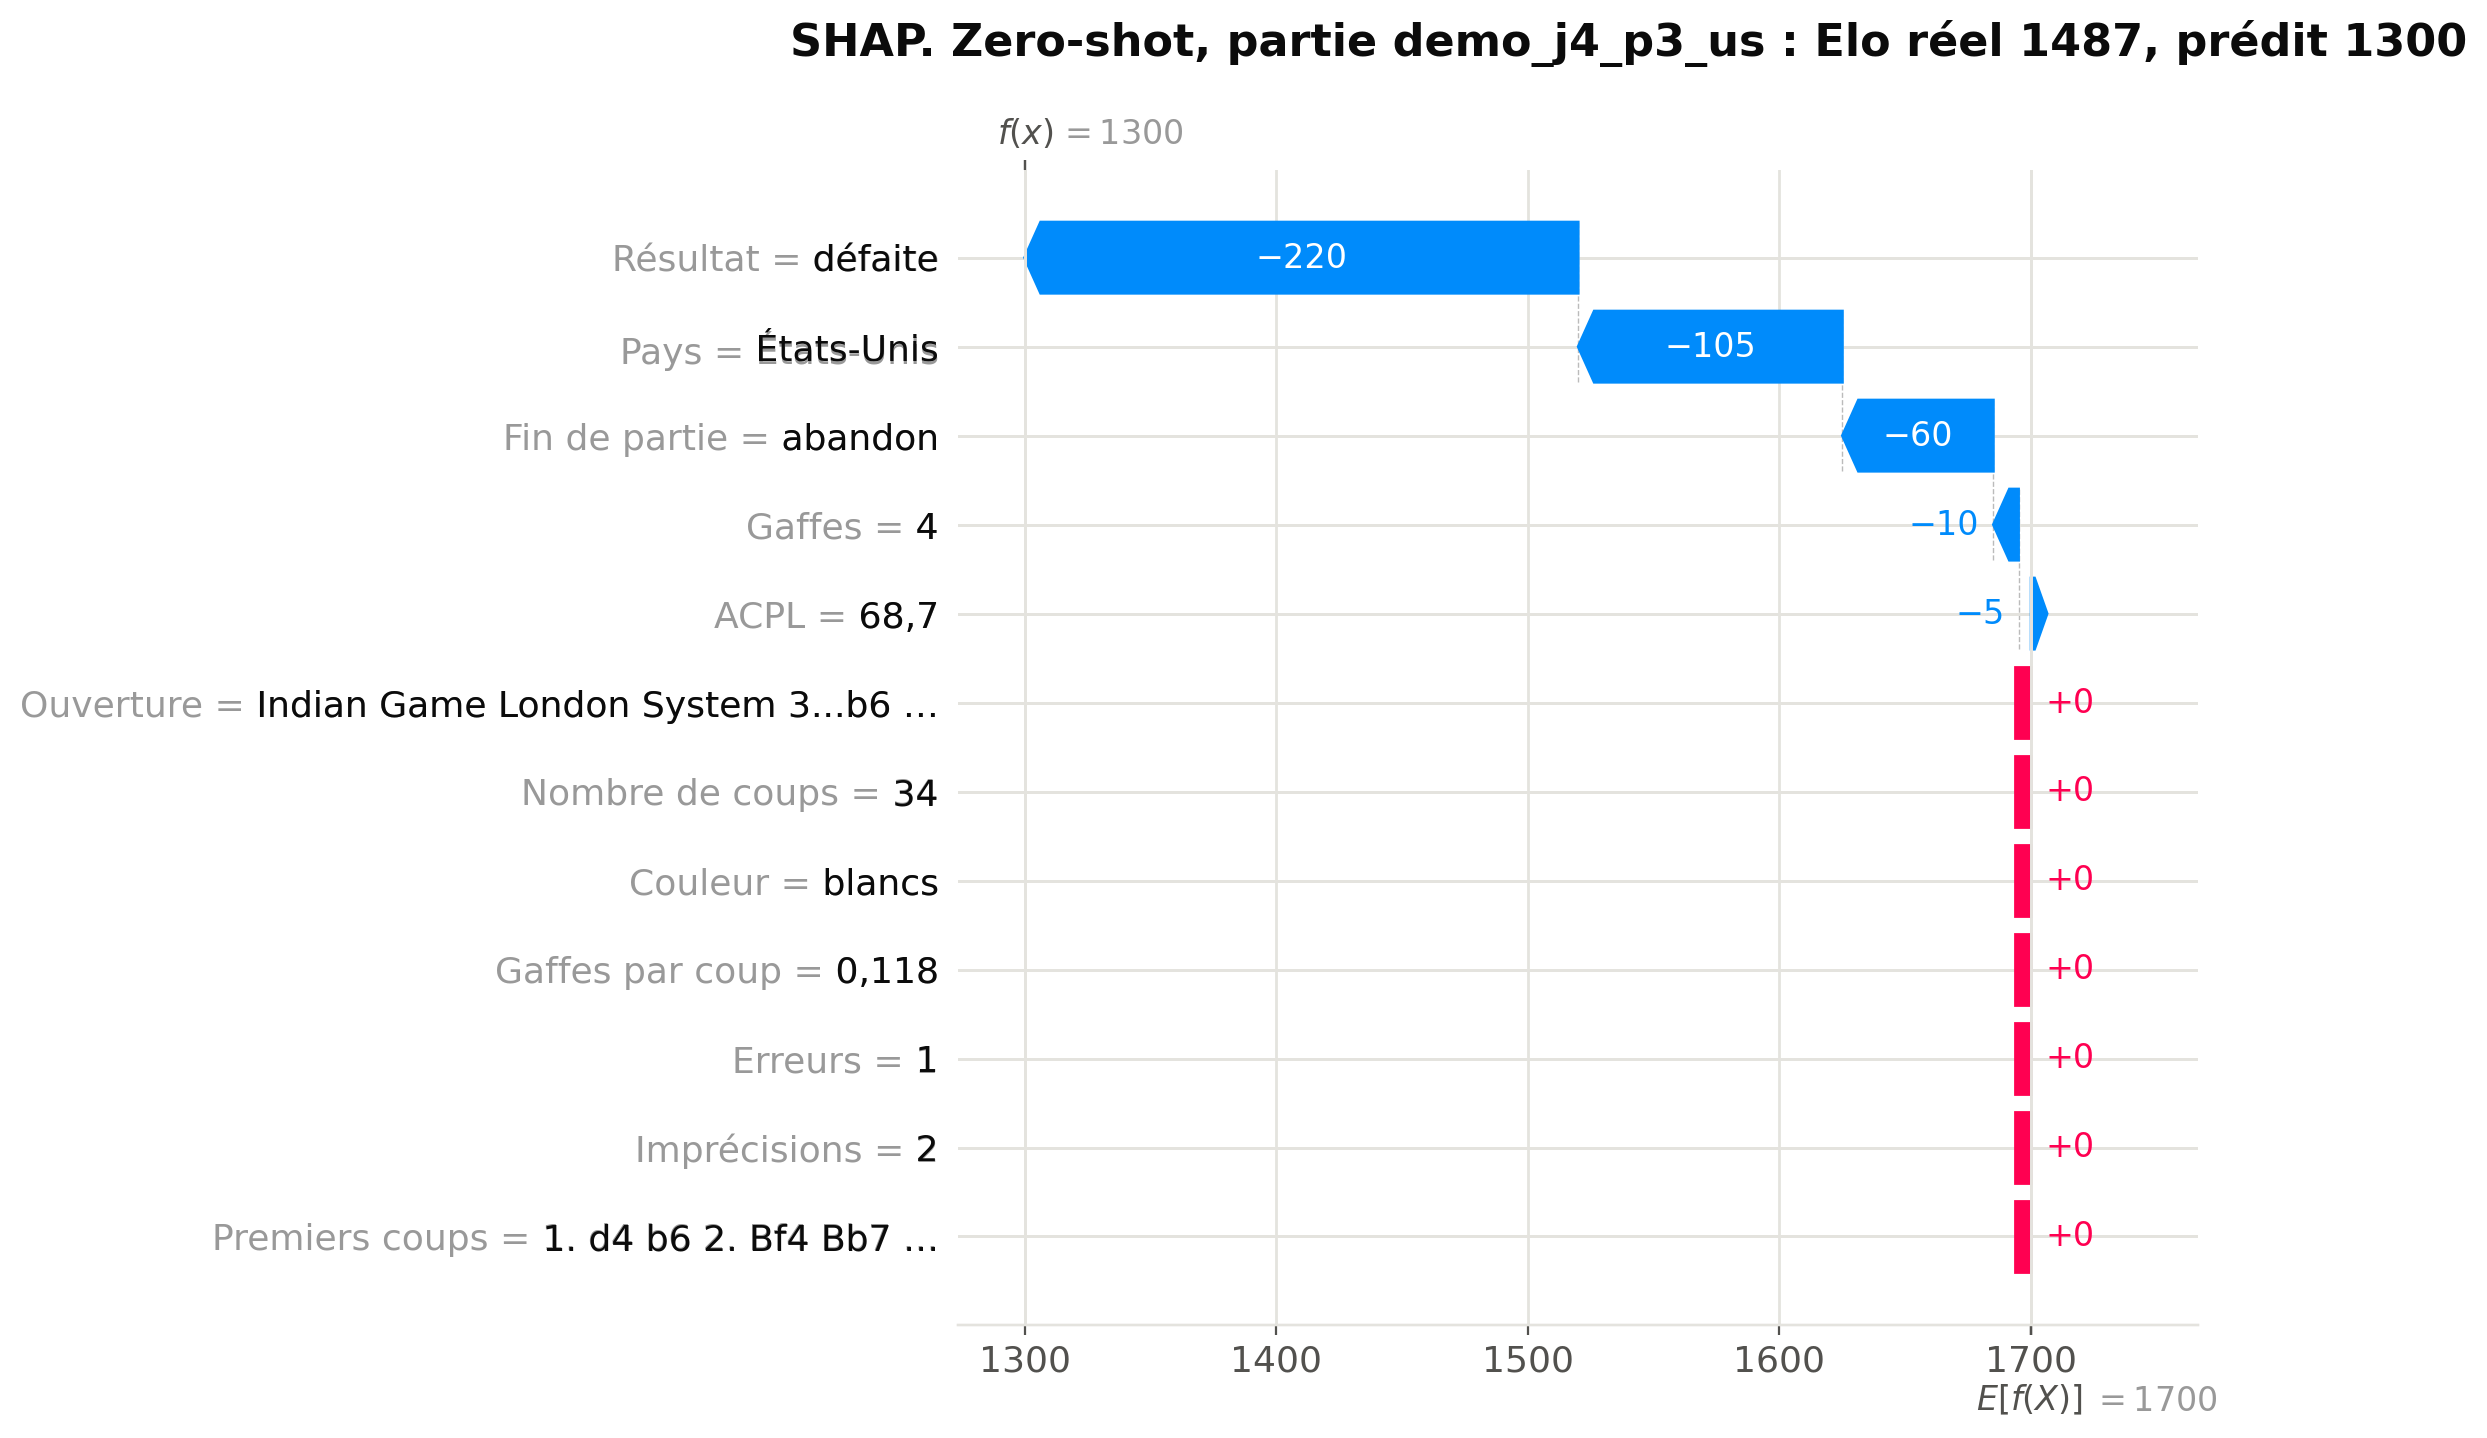

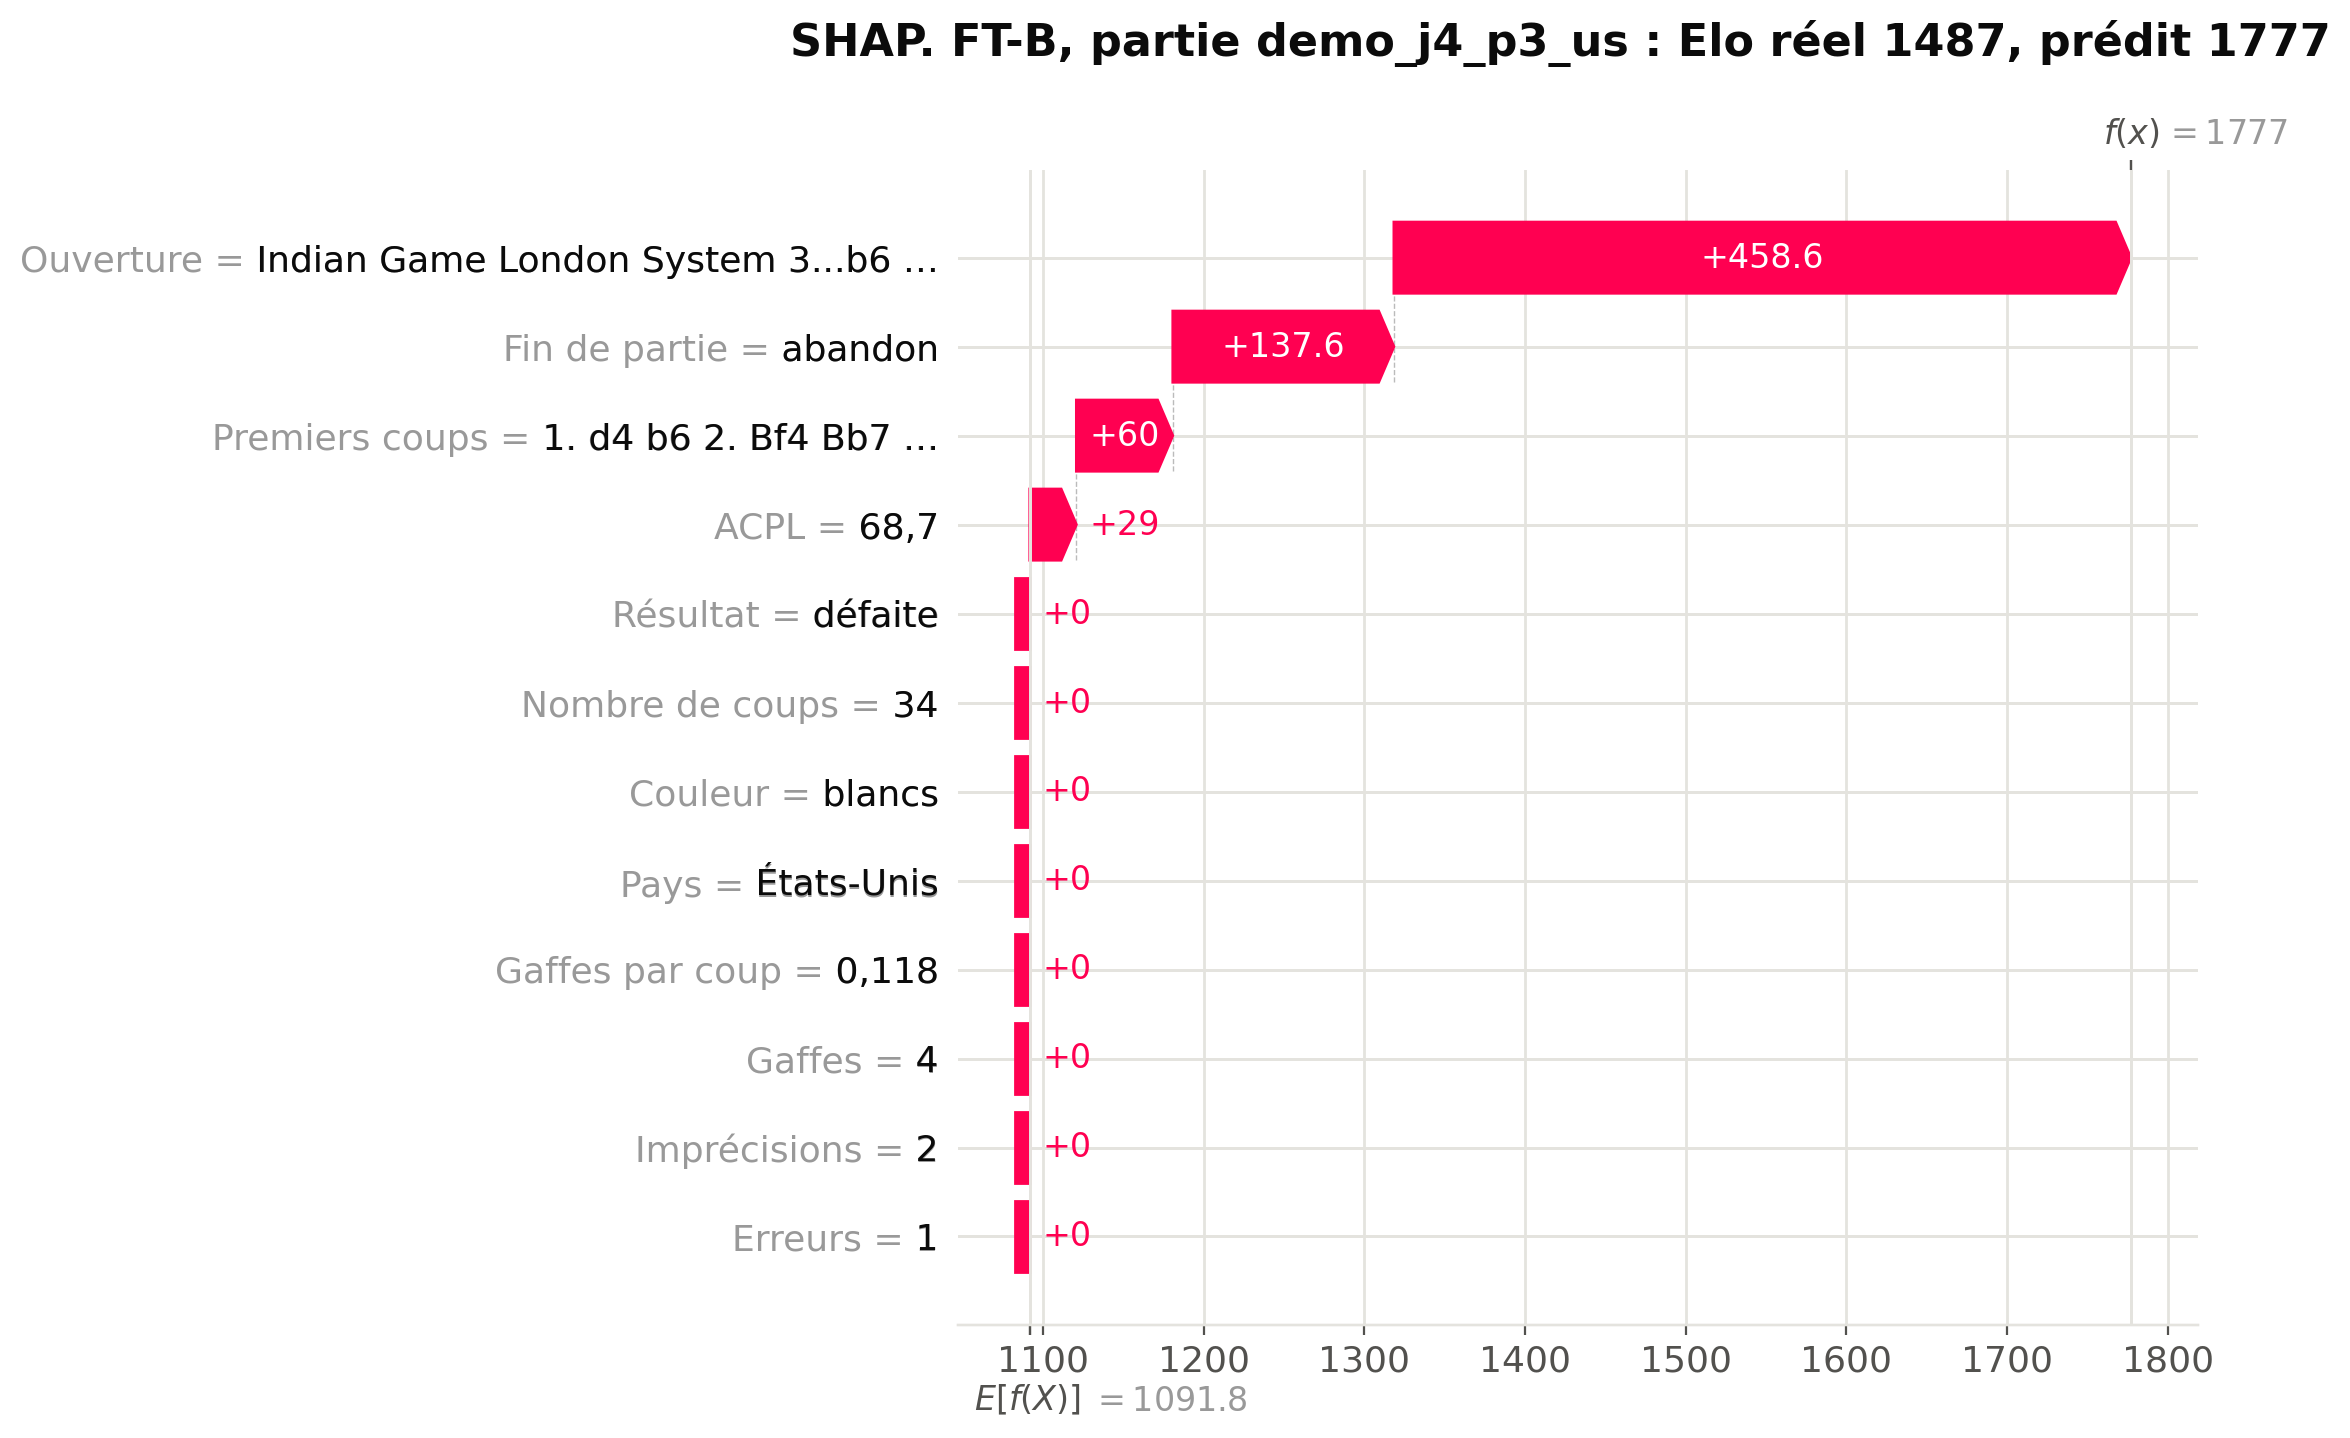

*Source : `06_xai_kaggle.ipynb`*

In [27]:
show_image("resultats_xai/fig_waterfall_zero_shot_demo_j4_p3_us.png", 760)
show_image("resultats_xai/fig_waterfall_ft_b_demo_j4_p3_us.png", 760)
source("06_xai_kaggle.ipynb")

## 9. Limites et éthique

> **À retenir.** Nos conclusions valent pour des parties rapides de chess.com, dans 5 pays, sur un échantillon non aléatoire. Les tests sont de taille modeste. Le modèle retenu ne serait pas assez précis pour placer seul un joueur dans une poule. L'anonymisation protège les pseudos, mais une partie publique reste en principe retrouvable.

**Échantillonnage.** La boule de neige favorise les joueurs actifs, et les quotas imposent un équilibre qui n'existe pas forcément sur chess.com. Le haut de la tranche 1900+ dépend des leaderboards, plus présents en Inde et aux États-Unis. Rien ne garantit les mêmes résultats sur un jeu déséquilibré : c'est justement là que FT-B pourrait servir.

**Petites tailles.**
- Test : 437 parties de 89 joueurs. Test de biais : 140 parties de 79 joueurs, et les intervalles, calculés sur les parties, sont un peu trop étroits.
- 45 intervalles dans la comparaison des 5 approches : un intervalle qui exclut 0 de justesse peut être dû au hasard.
- XAI : 12 parties seulement. Démo : 12 parties de 4 joueurs.

**Prédictions concentrées.** FT-A et FT-B n'utilisent que 23 valeurs (1677 représente 24,5 % des réponses de FT-A, 1777 25,6 % de celles de FT-B). La bonne tranche n'est trouvée que dans 28 % des cas. Pour un tournoi, il faudrait au mieux s'en servir comme d'un premier avis, puis le corriger avec les résultats suivants.

**Quantification 4 bits.** FT-A et FT-B sont évalués en 4 bits, le zero-shot en `float16`. Une petite partie des écarts peut venir de là. Le calcul n'est pas non plus parfaitement reproductible : en relançant l'XAI, FT-A a redonné ses 12 prédictions du test, et FT-B 11 sur 12 (1677 au lieu de 1577 pour la dernière).

**Hors domaine.** Le modèle n'a vu que des parties rapides. Le même joueur peut avoir un Elo très différent selon la cadence : Joueur 3 est à 844 en rapide, mais à 416 en blitz (profil public chess.com, consulté le 11/11/2026). Utiliser le modèle sur du blitz, du bullet ou une autre plateforme donnerait des estimations sans fondement.

**Indices indirects du pays.** Le test contrefactuel ne change que la ligne du pays. Certains noms d'ouverture contiennent une nationalité (« French Defense », « King's Indian ») : un modèle pourrait s'en servir comme indice indirect. Ce lien n'a pas été testé.

**Anonymisation et ré-identification.**
- Les prompts ne contiennent ni pseudo, ni prénom, ni lien, et `build_prompts.py` le vérifie. Les fichiers avec les pseudos (`data/*.csv`) ne sont pas versionnés, le dépôt étant public.
- Pourtant, les parties de chess.com sont publiques. Avec l'ouverture, les 10 premiers coups et le nombre de coups, on peut en principe retrouver une partie, donc son joueur. L'anonymisation réduit le risque, elle ne l'élimine pas.
- La démo utilise nos propres parties. La version publique de ce notebook n'affiche que « Joueur 1 » à « Joueur 4 ».

**Coût de calcul.** Stockfish a demandé environ 6 h sur 6 moteurs. Chaque méthode LLM a demandé des heures de GPU T4 (Colab et Kaggle), et l'XAI jusqu'à 150 appels au modèle par partie expliquée. Le gradient boosting s'entraîne en quelques secondes sur CPU, pour une précision équivalente. La sobriété plaide pour lui.

## 10. Conclusion

> **À retenir.** Le biais de pays a surtout été réduit par deux choix : **un dataset équilibré** par quotas, qui ne laisse aucun lien entre pays et Elo à apprendre, et **le fine-tuning sur des données réelles**, qui remplace les a priori du modèle par ce que montrent les parties. Tirer le pays au hasard (FT-B) va dans le bon sens, sans gain démontré.

- **(a) Données.** Un dataset réel de 4 200 parties, dont nous avons mesuré les biais : échantillonnage en boule de neige, leaderboards, accuracy manquante de façon non aléatoire, variables qui trahissent la réponse. Les quotas neutralisent le lien entre pays et Elo, et les variables à risque sont exclues.
- **(b) LLM.** Qwen3-4B-Instruct-2507, adapté par prompt engineering, RAG et fine-tuning QLoRA. Seul le fine-tuning atteint le niveau du gradient boosting (MAE de 382 pour FT-B, contre 369). Nous retenons FT-B, aussi précis que FT-A et le moins dépendant du pays.
- **(c) Cas d'usage.** Estimer l'Elo d'un joueur sans classement à partir d'une partie, pour le placer dans une poule de tournoi. Le modèle classe correctement nos joueurs dans l'ensemble, avec des ratés nets.
- **(d) XAI.** SHAP et LIME montrent que le pays pèse 15,5 % de la décision du modèle de base, et 0,2 % de celle de FT-B. Le modèle retenu s'appuie sur la qualité du jeu.

**Ce que nous retenons.** Un biais se mesure, à chaque étape : le few-shot v1 l'a créé avec 7 exemples. On le réduit d'abord en amont, par les données et l'entraînement. Et un modèle simple, explicable et sobre peut faire aussi bien qu'un LLM.

## 11. Annexe : vérification des chiffres cités

Chaque chiffre cité dans le texte est recalculé ici à partir des CSV du dépôt, puis comparé à la valeur écrite, à l'arrondi près. La cellule s'arrête si un seul ne correspond pas. Les chiffres tirés des données locales non versionnées ne sont vérifiés que si elles sont présentes. L'Elo blitz de Joueur 3 vient du profil chess.com et n'est pas vérifiable ici.

In [28]:
def row(path, **conditions):
    frame = read(path)
    for column, value in conditions.items():
        frame = frame[frame[column.replace("_", " ")] == value]
    assert len(frame) == 1, (path, conditions)
    return frame.iloc[0]


ft_scores = "resultats_finetuning_complets/scores_global.csv"
mae_csv = "resultats_finetuning_complets/comparaison_mae.csv"
gaps_csv = "resultats_finetuning_complets/biais_ecarts_france.csv"
spread_csv = "resultats_finetuning_complets/biais_etendue_par_partie.csv"
share_csv = "resultats_xai/part_du_pays.csv"
diff_csv = "resultats_xai/part_du_pays_differences.csv"
freq_csv = "resultats_finetuning_complets/valeurs_frequentes.csv"


def score(model, column):
    return scores.loc[model, column]


def top_share(model):
    return row(freq_csv, Modèle=model)["Part de la plus fréquente (%)"]


lesson_v = read("resultats_prompting_v2/comparaison_premiere_execution.csv").query("Variante == 'Few-shot'").set_index("Pays")
effect = read("resultats_finetuning_complets/pays_effet_sur_erreur.csv").query("Groupe == 'Global'").set_index("Version")
xai_share = read(share_csv).set_index(["Méthode", "Modèle"])
xai_diff = read(diff_csv).set_index(["Méthode", "Comparaison"])
demo_changes = {name: (demo[f"{name}, avec pays"] != demo[f"{name}, sans pays"]).sum() for name in DEMO_MODELS}
friend_gap = friend_table.set_index(["Partie de démo", "Modèle"])["États-Unis − France"]

CHECKS = [
    # (chiffre cité, valeur recalculée, valeur écrite, tolérance)
    ("Parties du dataset", len(games), 4200, 0),
    ("Parties de train / val / test", (len(splits["train"]), len(splits["val"]), len(splits["test"])), (3332, 431, 437), 0),
    ("Parties par tranche, France / autres pays", (quotas["France"].unique().tolist(), quotas.drop(columns="France").stack().unique().tolist()), ([240], [90]), 0),
    ("Part des parties d'adversaires visités (%)", 100 * (games["source"] == "opponent").mean(), 93, 0.5),
    ("Parties de leaderboard", (games["source"] == "leaderboard").sum(), 101, 0),
    ("Leaderboard, toutes en 1900+", games.loc[games["source"] == "leaderboard", "elo_bin"].unique().tolist(), ["1900+"], 0),
    ("Part du leaderboard dans 1900+ (%)", 100 * (games.loc[games["elo_bin"] == "1900+", "source"] == "leaderboard").mean(), 17, 0.5),
    ("Part du leaderboard dans 1900+, France (%)", 100 * (games.query("elo_bin == '1900+' and country == 'FR'")["source"] == "leaderboard").mean(), 8, 0.5),
    ("Part du leaderboard dans 1900+, Inde et États-Unis (%)", [round(100 * (games.query(f"elo_bin == '1900+' and country == '{c}'")["source"] == "leaderboard").mean()) for c in ("IN", "US")], [26, 26], 0),
    ("Corrélation de rang ACPL / accuracy", SPEARMAN, -0.92, 0.005),
    ("Accuracy absente (%)", 100 * MISSING_ACCURACY, 71.5, 0.05),
    ("MAE constante", score("Constante", "MAE"), 530, 0.5),
    ("MAE régression linéaire", score("Régression linéaire", "MAE"), 377, 0.5),
    ("MAE gradient boosting", score("Gradient boosting", "MAE"), 369, 0.5),
    ("R² gradient boosting", score("Gradient boosting", "R²"), 0.44, 0.005),
    ("MAE zero-shot", score("LLM zero-shot", "MAE"), 644, 0.5),
    ("Erreur moyenne zero-shot", score("LLM zero-shot", "Erreur moyenne"), 460, 0.5),
    ("Zero-shot : part de 1800 (%)", top_share("LLM zero-shot"), 44.9, 0.05),
    ("Zero-shot : valeurs distinctes", row(freq_csv, Modèle="LLM zero-shot")["Valeurs distinctes"], 8, 0),
    ("MAE few-shot v2", score("LLM few-shot", "MAE"), 507, 0.5),
    ("MAE few-shot v1", prompting.loc["LLM few-shot, exemples avec pays", "MAE"], 510, 0.5),
    ("R² few-shot", score("LLM few-shot", "R²"), 0.06, 0.005),
    ("Few-shot : part de 1024 (%)", top_share("LLM few-shot"), 46.9, 0.05),
    ("MAE RAG", score("LLM RAG", "MAE"), 573, 0.5),
    ("Erreur moyenne RAG", score("LLM RAG", "Erreur moyenne"), 275, 0.5),
    ("RAG moins médiane des voisins", row("resultats_rag/comparaison_mae.csv", Modèle="LLM RAG", Comparé_à="Médiane des voisins")["Différence de MAE"], 121, 0.5),
    ("MAE FT-A / FT-B", (score("LLM FT-A", "MAE"), score("LLM FT-B", "MAE")), (380, 382), 0.5),
    ("R² FT-A / FT-B", (score("LLM FT-A", "R²"), score("LLM FT-B", "R²")), (0.39, 0.38), 0.005),
    ("Bonne tranche FT-B (%)", score("LLM FT-B", "Bonne tranche (%)"), 28, 0.65),
    ("Valeurs distinctes FT-A / FT-B", (row(freq_csv, Modèle="LLM FT-A")["Valeurs distinctes"], row(freq_csv, Modèle="LLM FT-B")["Valeurs distinctes"]), (23, 23), 0),
    ("FT-A : part de 1677 (%) ; FT-B : part de 1777 (%)", (top_share("LLM FT-A"), top_share("LLM FT-B")), (24.5, 25.6), 0.05),
    ("FT-B moins gradient boosting", row(mae_csv, Modèle="LLM FT-B", Comparé_à="Gradient boosting")["Différence de MAE"], 13, 0.5),
    ("FT-B moins FT-A (MAE) et IC", tuple(row(mae_csv, Modèle="LLM FT-B", Comparé_à="LLM FT-A")[["Différence de MAE", "IC 95 % bas", "IC 95 % haut"]]), (2.8, -14.8, 20.3), 0.05),
    ("FT-B moins few-shot / RAG / zero-shot", tuple(row(mae_csv, Modèle="LLM FT-B", Comparé_à=c)["Différence de MAE"] for c in ("LLM few-shot", "LLM RAG", "LLM zero-shot")), (-125, -191, -262), 0.5),
    ("Zero-shot : écart États-Unis / Inde / Allemagne", tuple(row(gaps_csv, Variante="Zero-shot", country=c)["Écart moyen"] for c in ("US", "IN", "DE")), (-91, 49, 49), 0.5),
    ("FT-A et FT-B : aucun écart significatif", read(gaps_csv).query("Variante in ['FT-A', 'FT-B']")["IC exclut 0"].any(), False, 0),
    ("Few-shot v2 : Brésil / Allemagne / États-Unis", tuple(row(gaps_csv, Variante="Few-shot", country=c)["Écart moyen"] for c in ("BR", "DE", "US")), (-62, 46, 37), 0.5),
    ("Few-shot v1 : Brésil", lesson_v.loc["Brésil", "Écart, première exécution"], -243, 0.5),
    ("Étendue zero-shot / few-shot / RAG / FT-A / FT-B", tuple(read(spread_csv).set_index("Méthode").loc[["Zero-shot", "Few-shot", "RAG", "FT-A", "FT-B"], "Étendue moyenne"]), (150, 120, 58, 37, 16), 0.5),
    ("Pays change la prédiction : zero-shot / FT-B (%)", tuple(read(spread_csv).set_index("Méthode").loc[["Zero-shot", "FT-B"], "Parties où le pays change la prédiction (%)"]), (78, 10), 0.5),
    ("Étendue FT-B moins FT-A et IC", SPREAD_DIFF, (-21, -51, 5), 0.5),
    ("Parties où FT-A et FT-B ne bougent pas", int((spread_by_game("ft_a").reindex(spread_diff.index).eq(0) & spread_by_game("ft_b").reindex(spread_diff.index).eq(0)).sum()), 109, 0),
    ("Effet du pays sur l'erreur, FT-A, et IC", tuple(effect.loc["FT-A", ["Variation de l'erreur absolue", "IC 95 % bas", "IC 95 % haut"]]), (-6.7, -15.2, 0.6), 0.05),
    ("Part du pays SHAP : zero-shot / FT-A / FT-B (%)", tuple(xai_share.loc[("SHAP", m), "Part du pays (%)"] for m in ("Zero-shot", "FT-A", "FT-B")), (15.5, 1.0, 0.2), 0.05),
    ("Rang du pays, zero-shot (SHAP)", xai_share.loc[("SHAP", "Zero-shot"), "Rang du pays sur 12"], 2, 0),
    ("Part du pays LIME : zero-shot / FT-A / FT-B (%)", tuple(xai_share.loc[("LIME", m), "Part du pays (%)"] for m in ("Zero-shot", "FT-A", "FT-B")), (8.8, 7.0, 5.8), 0.05),
    ("SHAP : FT-B moins FT-A (points)", xai_diff.loc[("SHAP", "FT-B moins FT-A"), "Écart de part (points)"], -0.7, 0.05),
    ("SHAP : baisses significatives après fine-tuning", tuple(xai_diff.loc[("SHAP", c), "IC 95 % haut"] < 0 for c in ("FT-A moins Zero-shot", "FT-B moins Zero-shot")), (True, True), 0),
    ("LIME : aucune différence significative", any(xai_diff.loc["LIME", "IC 95 % haut"] < 0) or any(xai_diff.loc["LIME", "IC 95 % bas"] > 0), False, 0),
    ("SHAP du pays, g1852 : zero-shot / FT-A / FT-B", tuple(read(f"resultats_xai/shap_{m}.csv").query("game_id == 'g1852' and variable == 'country'")["shap"].iloc[0] for m in ("zero_shot", "ft_a", "ft_b")), (-190, 10, -10), 0.5),
    ("Gradient boosting : part du pays (%)", baseline_share["Part du pays (%)"].iloc[0], 0.9, 0.05),
    ("Gradient boosting : rang du pays", baseline_share["Rang du pays sur 12"].iloc[0], 11, 0),
    ("Gradient boosting : part de l'ACPL (%)", read("resultats_xai_baseline/importance_globale.csv").set_index("Variable").loc["ACPL", "Part (%)"], 36.7, 0.05),
    ("Démo : erreur moyenne zero-shot / FT-A / FT-B", tuple(DEMO_MAE.values()), (622, 388, 403), 0.5),
    ("Démo : Joueur 4, États-Unis − France, zero-shot", friend_gap.xs("Zero-shot", level="Modèle").tolist(), [-100, -100, -100], 0),
    ("Démo : Joueur 4, États-Unis − France, FT-A / FT-B", (friend_gap.xs("FT-A", level="Modèle").tolist(), friend_gap.xs("FT-B", level="Modèle").tolist()), ([0, -200, 0], [100, 0, 0]), 0),
    ("Démo : prédictions changées sans pays (sur 15)", tuple(demo_changes.values()), (8, 2, 2), 0),
    ("Démo : SHAP du pays, partie 3 États-Unis, zero-shot / FT-B", tuple(read(f"resultats_xai/shap_{m}.csv").query("game_id == 'demo_j4_p3_us' and variable == 'country'")["shap"].iloc[0] for m in ("zero_shot", "ft_b")), (-105, 0), 0.5),
    ("Démo : partie 3 de Joueur 1, Elo réel et FT-A / FT-B", tuple(france.query("Partie == 'demo_j1_p3'")[["Elo réel", "FT-A, avec pays", "FT-B, avec pays"]].iloc[0]), (969, 101, 101), 0),
    ("Démo : Joueur 2, parties 1 et 2, FT (min, max)", (france.query("Partie in ['demo_j2_p1', 'demo_j2_p2']")[["FT-A, avec pays", "FT-B, avec pays"]].min().min(), france.query("Partie in ['demo_j2_p1', 'demo_j2_p2']")[["FT-A, avec pays", "FT-B, avec pays"]].max().max()), (1017, 1517), 0),
    ("Démo : zero-shot entre 1300 et 1850", (demo["Zero-shot, avec pays"].min(), demo["Zero-shot, avec pays"].max()), (1300, 1850), 0),
    ("Démo : Joueur 4, FT entre 1577 et 1777", (france[france["Partie"].str.startswith("demo_j4")][["FT-A, avec pays", "FT-B, avec pays"]].min().min(), france[france["Partie"].str.startswith("demo_j4")][["FT-A, avec pays", "FT-B, avec pays"]].max().max()), (1577, 1777), 0),
]
if HAS_LOCAL_DATA:
    CHECKS += [
        ("Joueurs au total / dans le test", (ids["username"].nunique(), ids.loc[ids["split"] == "test", "username"].nunique()), (856, 89), 0),
        ("Accuracy absente : Inde / Brésil / France / Allemagne / États-Unis (%)", tuple(MISSING_BY_COUNTRY.loc[["Inde", "Brésil", "France", "Allemagne", "États-Unis"]]), (76.8, 75.4, 70.5, 70.3, 65.9), 0.05),
        ("Accuracy absente : sous 1900 (min, max) et 1900+ (%)", (MISSING_BY_BIN.drop("1900+").min(), MISSING_BY_BIN.drop("1900+").max(), MISSING_BY_BIN["1900+"]), (73, 79, 49), 0.5),
    ]


def matches(computed, cited, tolerance):
    if isinstance(cited, (list, tuple)):
        return len(computed) == len(cited) and all(matches(a, b, tolerance) for a, b in zip(computed, cited))
    if isinstance(cited, (bool, np.bool_)) or isinstance(cited, str):
        return computed == cited
    return abs(float(computed) - cited) <= tolerance + 1e-9


def short(value):
    if isinstance(value, (list, tuple)):
        return "(" + " ; ".join(short(v) for v in value) + ")"
    if isinstance(value, (float, np.floating)) and not float(value).is_integer():
        return f"{value:.3f}".rstrip("0")
    return str(value if not isinstance(value, (np.integer, np.floating)) else value.item())


report = pd.DataFrame([{"Chiffre cité": label, "Valeur écrite": short(cited), "Recalculée": short(computed),
                        "OK": "oui" if matches(computed, cited, tolerance) else "NON"} for label, computed, cited, tolerance in CHECKS])
show_table(report)
failed = report[report["OK"] != "oui"]
assert failed.empty, f"Chiffres à corriger : {failed['Chiffre cité'].tolist()}"
print(f"{len(report)} vérifications, toutes correctes.")

Chiffre cité,Valeur écrite,Recalculée,OK
Parties du dataset,4200,4200,oui
Parties de train / val / test,(3332 ; 431 ; 437),(3332 ; 431 ; 437),oui
"Parties par tranche, France / autres pays",((240) ; (90)),((240) ; (90)),oui
Part des parties d'adversaires visités (%),93,92.81,oui
Parties de leaderboard,101,101,oui
"Leaderboard, toutes en 1900+",(1900+),(1900+),oui
Part du leaderboard dans 1900+ (%),17,16.833,oui
"Part du leaderboard dans 1900+, France (%)",8,8.333,oui
"Part du leaderboard dans 1900+, Inde et États-Unis (%)",(26 ; 26),(26 ; 26),oui
Corrélation de rang ACPL / accuracy,-0.92,-0.916,oui


65 vérifications, toutes correctes.
